# Back to Basic Regression

I need to start again. I've been to far into the weeds, and I need to start again. Kaya Identities, simple linear regressions, more complex regressions, etc. KISS: Keep It Simple, Stupid

## Imports

In [95]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from odym import dynamic_stock_model as dsm
from scipy import stats
from scipy.interpolate import interp1d
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from scipy.optimize import curve_fit
import weibull
import math
from scipy.stats import linregress 
import matplotlib.lines as mlines
import matplotlib.ticker as mtick
from matplotlib.ticker import PercentFormatter
import plotly.graph_objects as go
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from scipy.optimize import curve_fit
import pmdarima as pm



## Data Imports

In [96]:
df_population = pd.read_csv(r"C:\Users\aorga\OneDrive\Documents\01_CU\00_Research\02_US Structural Steel MFA\input_data_population.csv", index_col=0)
df_gdp = pd.read_csv(r"C:\Users\aorga\OneDrive\Documents\01_CU\00_Research\02_US Structural Steel MFA\input_data_GDP.csv", index_col=0)
df_steel = pd.read_csv(r'C:\Users\aorga\OneDrive\Documents\01_CU\00_Research\02_US Structural Steel MFA\input_data_production.csv', index_col=0)
df_energy_use = pd.read_excel(r"C:\Users\aorga\OneDrive\Documents\01_CU\00_Research\02_US Structural Steel MFA\final_energy_use.xlsx", index_col=0)

In [ ]:
## Get GDP df
df_gdp.index = df_gdp.index.astype(int)  # ensure index is numeric
df_gdp = df_gdp.sort_index()
df_gdp = df_gdp.reindex(
    range(df_gdp.index.min(), df_gdp.index.max() + 1)
)

cols = ['gdp_ssp1','gdp_ssp2','gdp_ssp3','gdp_ssp4','gdp_ssp5']

df_gdp[cols] = (
    df_gdp[cols]
      .apply(pd.to_numeric, errors='coerce')
      .interpolate(method='cubic')
)

df_gdp= df_gdp.loc[df_gdp.index >= 1931]

In [98]:
## Get pop DF
df_population.index = df_population.index.astype(int)  # ensure index is numeric
df_population = df_population.sort_index()
df_population = df_population.reindex(
    range(1931, 2100+1)
)

cols = ['pop_ssp1','pop_ssp2','pop_ssp3','pop_ssp4','pop_ssp5']

df_population[cols] = (
    df_population[cols]
      .interpolate(method='cubic')
)

In [99]:
## Get energy DF
df_energy_use.index = df_energy_use.index.astype(int)  # ensure index is numeric
df_energy_use = df_energy_use.sort_index()
df_energy_use = df_energy_use.reindex(
    range(1931, 2100+1)
)

cols = ['energy usage']

df_energy_use[cols] = (
    df_energy_use[cols]
      .interpolate(method='linear', limit_area='inside')
)

In [100]:
df_steel

,total-production,structural-total
1931,23536.93607,1630
1932,12411.20919,860
1933,21075.74094,1460
1934,23636.72651,1637
1935,30928.68612,2142
...,...,...
2019,87300.00000,6582
2020,73500.00000,5693
2021,85900.00000,7095
2022,81200.00000,6869


## Get slopes and intercepts for equation

In [101]:
df_elasticities = pd.concat([df_population['pop_ssp2'],df_gdp['gdp_ssp2'],df_energy_use['energy usage'],df_steel['structural-total'],df_steel['total-production']],axis = 1)
df_elasticities = df_elasticities.loc[1931:2023]

In [102]:
df_elasticities

,pop_ssp2,gdp_ssp2,energy usage,structural-total,total-production
1931,124039648.0,9931.000000,23.680000,1630.0,23536.93607
1932,124840471.0,8381.000000,22.869000,860.0,12411.20919
1933,125578763.0,8048.000000,22.058000,1460.0,21075.74094
1934,126373773.0,8667.000000,21.247000,1637.0,23636.72651
1935,127250232.0,9681.000000,20.436000,2142.0,30928.68612
...,...,...,...,...,...
2019,330226227.0,57268.309700,96.595282,6582.0,87300.00000
2020,331515736.0,59395.970000,88.870945,5693.0,73500.00000
2021,332099760.0,61180.334978,93.363948,7095.0,85900.00000
2022,333288000.0,62596.163901,92.382874,6869.0,81200.00000


## Univariate Regression

### All years (1931-2023)


pop_ssp2
  Slope:     0.000222
  Intercept: 21981.509865
  R²:        0.5511

gdp_ssp2
  Slope:     0.912185
  Intercept: 43548.362070
  R²:        0.5026

energy usage
  Slope:     615.244945
  Intercept: 31593.780193
  R²:        0.6849

structural-total (2001–2023 only)
  Slope:     7.401289
  Intercept: 41692.083042
  R²:        0.5518


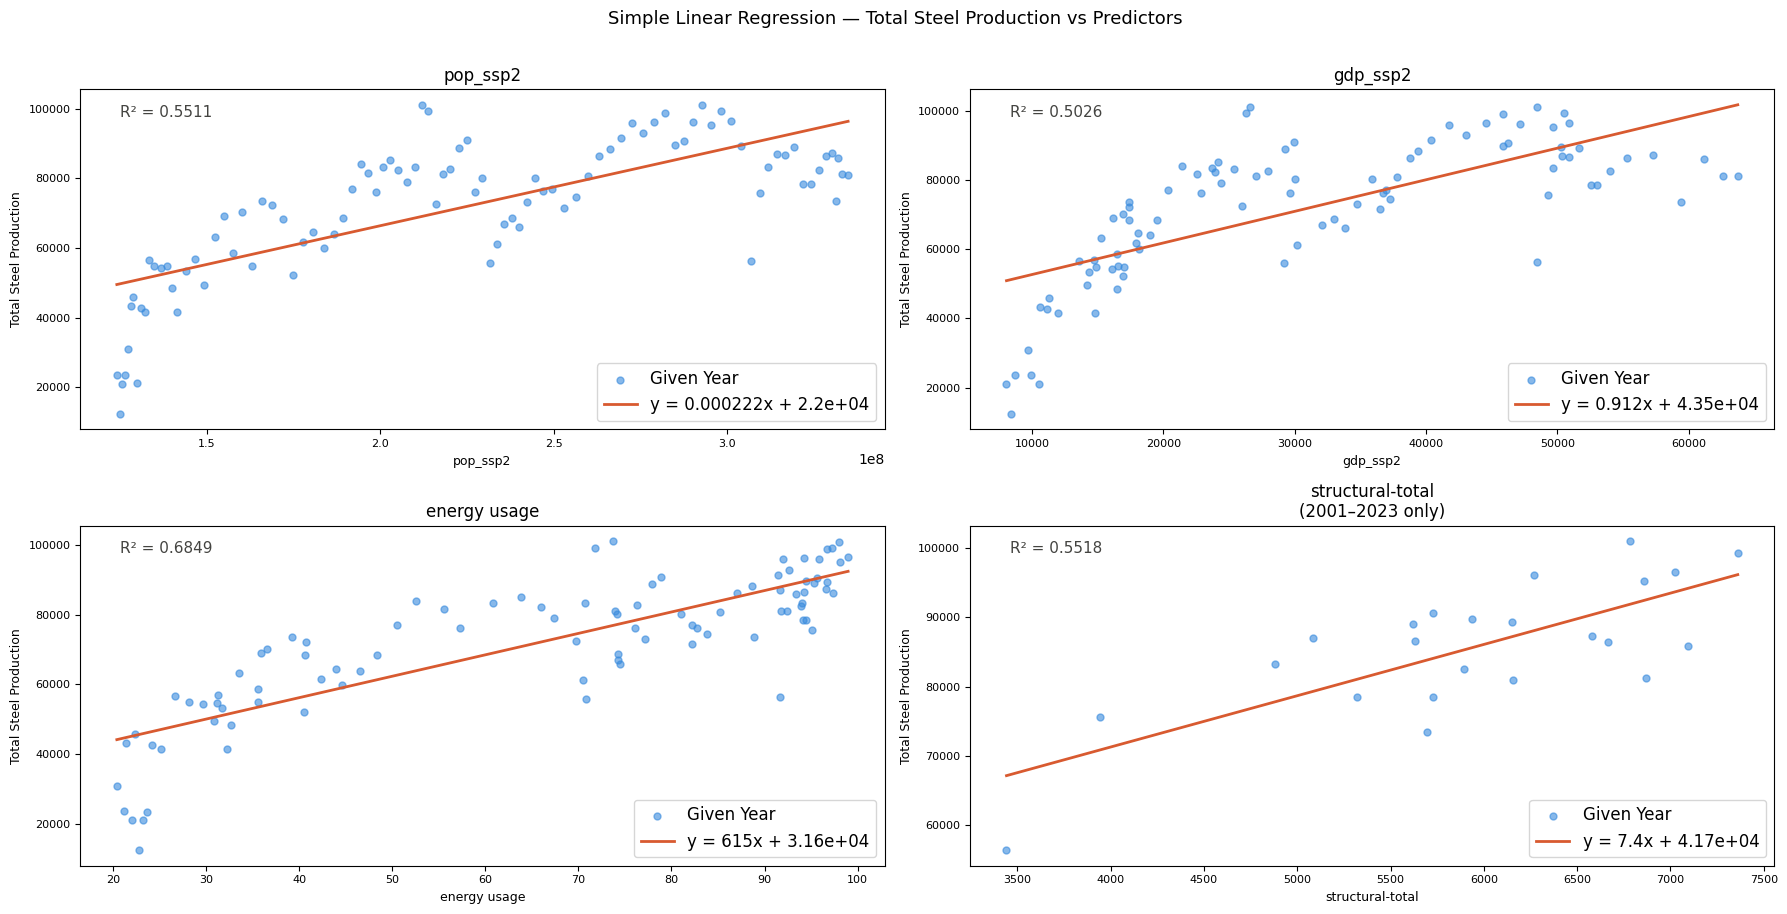

In [103]:
## Get slope and intercept of each one (Univariate regression)
# ── config ───────────────────────────────────────────────────────────────────
full_vars = ["pop_ssp2", "gdp_ssp2", "energy usage"]
all_vars  = full_vars + ["structural-total"]
results   = {}

# ── full-range regression (1931–2023) ────────────────────────────────────────
for col in full_vars:
    x = df_elasticities[[col]].values
    y = df_elasticities["total-production"].values

    model = LinearRegression().fit(x, y)
    results[col] = {
        "x": x.flatten(), "y": y,
        "slope": model.coef_[0],
        "intercept": model.intercept_,
        "r2": model.score(x, y),
        "label": col,
    }

    print(f"\n{col}")
    print(f"  Slope:     {model.coef_[0]:.6f}")
    print(f"  Intercept: {model.intercept_:.6f}")
    print(f"  R²:        {model.score(x, y):.4f}")

# ── structural-total: 2001–2023 only ─────────────────────────────────────────
df_struct = df_elasticities.loc[2001:2023]  
x = df_struct[["structural-total"]].values
y = df_struct["total-production"].values

model = LinearRegression().fit(x, y)
results["structural-total"] = {
    "x": x.flatten(), "y": y,
    "slope": model.coef_[0],
    "intercept": model.intercept_,
    "r2": model.score(x, y),
    "label": "structural-total\n(2001–2023 only)",
}

print(f"\nstructural-total (2001–2023 only)")
print(f"  Slope:     {model.coef_[0]:.6f}")
print(f"  Intercept: {model.intercept_:.6f}")
print(f"  R²:        {model.score(x, y):.4f}")

# ── 2x2 plot ─────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(2, 2, figsize=(18, 9))
axes = axes.flatten()

for ax, col in zip(axes, all_vars):
    r = results[col]
    x_vals = r["x"]
    y_vals = r["y"]

    x_line = np.linspace(x_vals.min(), x_vals.max(), 200)
    y_line = r["slope"] * x_line + r["intercept"]

    ax.scatter(x_vals, y_vals, alpha=0.6, s=25, color="#378ADD", label="Given Year")
    ax.plot(x_line, y_line, color="#D85A30", linewidth=2,
            label=f"y = {r['slope']:.3g}x + {r['intercept']:.3g}")

    ax.set_title(r["label"], fontsize=12)
    ax.set_xlabel(col.split("\n")[0], fontsize=9)
    ax.set_ylabel("Total Steel Production", fontsize=9)
    ax.legend(fontsize=12)
    ax.text(0.05, 0.92, f"R² = {r['r2']:.4f}", transform=ax.transAxes,
            fontsize=11, color="#444441")
    ax.tick_params(labelsize=8)

plt.suptitle("Simple Linear Regression — Total Steel Production vs Predictors",
             fontsize=13, y=1.01)
plt.tight_layout()
plt.show()

### All Years fit against structural steel production


pop_ssp2
  Slope:     0.000016
  Intercept: 1451.520586
  R²:        0.5403

gdp_ssp2
  Slope:     0.065863
  Intercept: 2936.365739
  R²:        0.5133

energy usage
  Slope:     42.695214
  Intercept: 2185.475590
  R²:        0.6461

structural-total (2001–2023 only)
  Slope:     1.000000
  Intercept: -0.000000
  R²:        1.0000


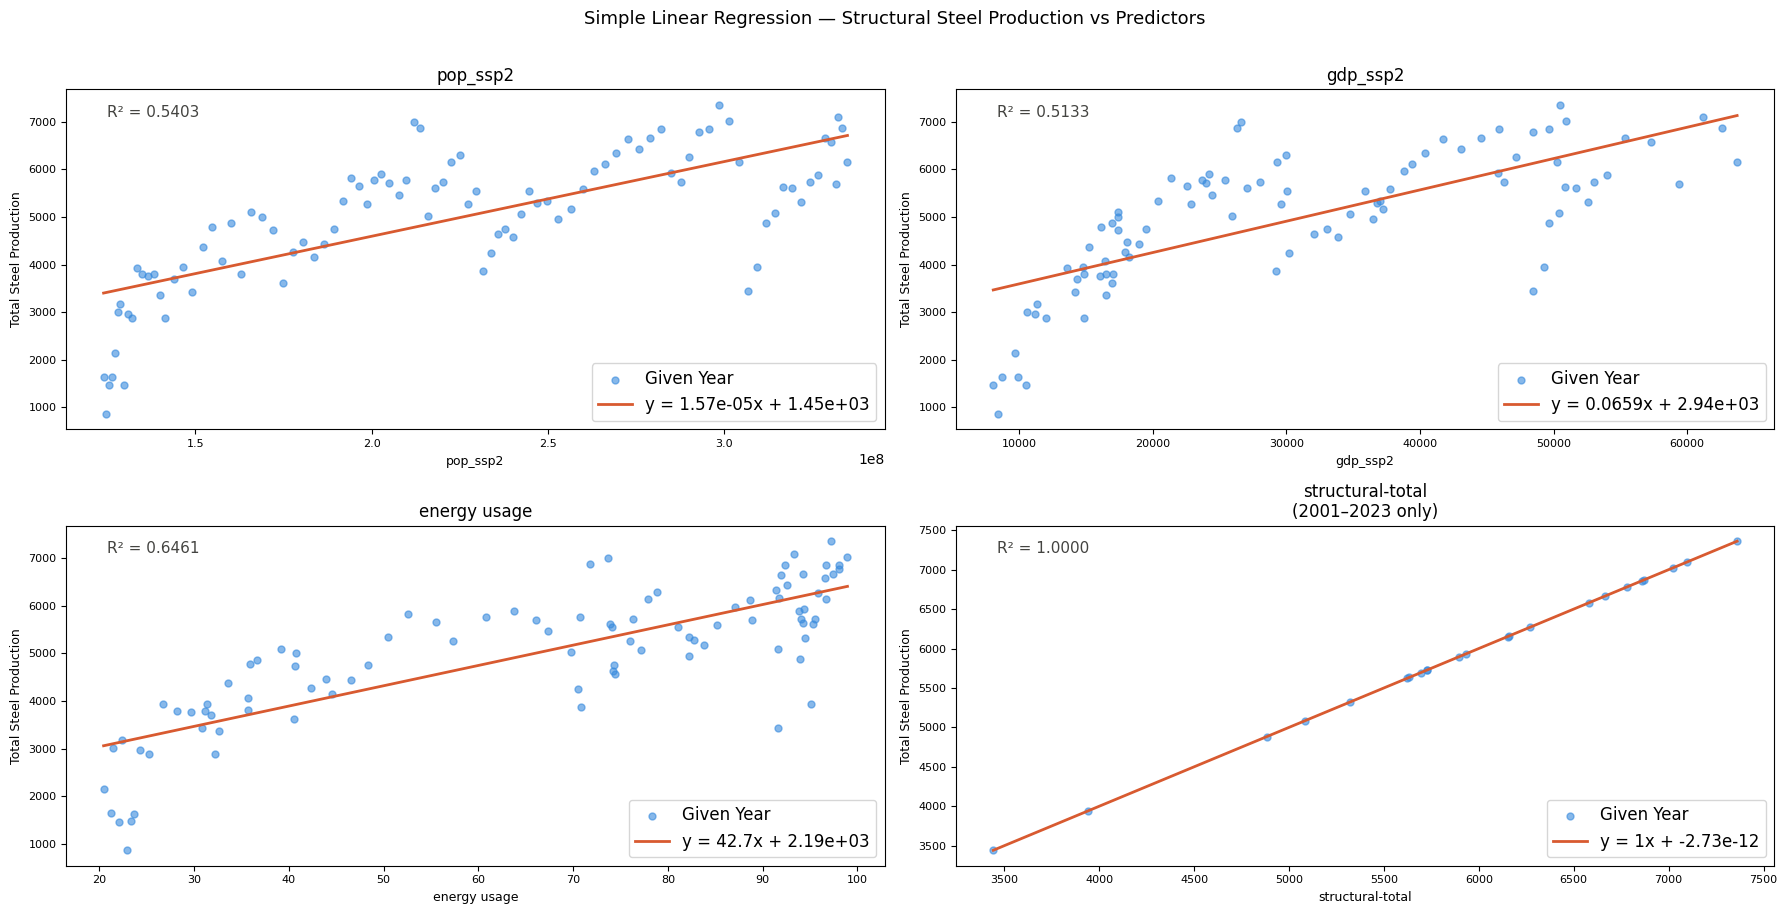

In [104]:
## Get slope and intercept of each one (Univariate regression)
# ── config ───────────────────────────────────────────────────────────────────
full_vars = ["pop_ssp2", "gdp_ssp2", "energy usage"]
all_vars  = full_vars + ["structural-total"]
results   = {}

# ── full-range regression (1931–2023) ────────────────────────────────────────
for col in full_vars:
    x = df_elasticities[[col]].values
    y = df_elasticities["structural-total"].values

    model = LinearRegression().fit(x, y)
    results[col] = {
        "x": x.flatten(), "y": y,
        "slope": model.coef_[0],
        "intercept": model.intercept_,
        "r2": model.score(x, y),
        "label": col,
    }

    print(f"\n{col}")
    print(f"  Slope:     {model.coef_[0]:.6f}")
    print(f"  Intercept: {model.intercept_:.6f}")
    print(f"  R²:        {model.score(x, y):.4f}")

# ── structural-total: 2001–2023 only ─────────────────────────────────────────
df_struct = df_elasticities.loc[2001:2023]  
x = df_struct[["structural-total"]].values
y = df_struct["structural-total"].values

model = LinearRegression().fit(x, y)
results["structural-total"] = {
    "x": x.flatten(), "y": y,
    "slope": model.coef_[0],
    "intercept": model.intercept_,
    "r2": model.score(x, y),
    "label": "structural-total\n(2001–2023 only)",
}

print(f"\nstructural-total (2001–2023 only)")
print(f"  Slope:     {model.coef_[0]:.6f}")
print(f"  Intercept: {model.intercept_:.6f}")
print(f"  R²:        {model.score(x, y):.4f}")

# ── 2x2 plot ─────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(2, 2, figsize=(18, 9))
axes = axes.flatten()

for ax, col in zip(axes, all_vars):
    r = results[col]
    x_vals = r["x"]
    y_vals = r["y"]

    x_line = np.linspace(x_vals.min(), x_vals.max(), 200)
    y_line = r["slope"] * x_line + r["intercept"]

    ax.scatter(x_vals, y_vals, alpha=0.6, s=25, color="#378ADD", label="Given Year")
    ax.plot(x_line, y_line, color="#D85A30", linewidth=2,
            label=f"y = {r['slope']:.3g}x + {r['intercept']:.3g}")

    ax.set_title(r["label"], fontsize=12)
    ax.set_xlabel(col.split("\n")[0], fontsize=9)
    ax.set_ylabel("Total Steel Production", fontsize=9)
    ax.legend(fontsize=12)
    ax.text(0.05, 0.92, f"R² = {r['r2']:.4f}", transform=ax.transAxes,
            fontsize=11, color="#444441")
    ax.tick_params(labelsize=8)

plt.suptitle("Simple Linear Regression — Structural Steel Production vs Predictors",
             fontsize=13, y=1.01)
plt.tight_layout()
plt.show()

### Post-War (1950-2023)

In [105]:
# # ── filter to 1950 onward ────────────────────────────────────────────────────
# df_postwar = df_elasticities.loc[1950:]  # change to df[df["year"] >= 1950] if year is a column

# # ── config ───────────────────────────────────────────────────────────────────
# full_vars = ["pop_ssp2", "gdp_ssp2", "energy usage"]
# all_vars  = full_vars + ["structural-total"]
# results   = {}

# # ── full-range regression (1950–2023) ────────────────────────────────────────
# for col in full_vars:
#     x = df_postwar[[col]].values
#     y = df_postwar["total-production"].values

#     model = LinearRegression().fit(x, y)
#     results[col] = {
#         "x": x.flatten(), "y": y,
#         "slope": model.coef_[0],
#         "intercept": model.intercept_,
#         "r2": model.score(x, y),
#         "label": col,
#     }

#     print(f"\n{col}")
#     print(f"  Slope:     {model.coef_[0]:.6f}")
#     print(f"  Intercept: {model.intercept_:.6f}")
#     print(f"  R²:        {model.score(x, y):.4f}")

# # ── structural-total: 2001–2023 only ─────────────────────────────────────────
# df_struct = df_postwar.loc[2001:2023]  # already within 1950+ so no change needed

# x = df_struct[["structural-total"]].values
# y = df_struct["total-production"].values

# model = LinearRegression().fit(x, y)
# results["structural-total"] = {
#     "x": x.flatten(), "y": y,
#     "slope": model.coef_[0],
#     "intercept": model.intercept_,
#     "r2": model.score(x, y),
#     "label": "structural-total\n(2001–2023 only)",
# }

# print(f"\nstructural-total (2001–2023 only)")
# print(f"  Slope:     {model.coef_[0]:.6f}")
# print(f"  Intercept: {model.intercept_:.6f}")
# print(f"  R²:        {model.score(x, y):.4f}")

# # ── 2x2 plot ─────────────────────────────────────────────────────────────────
# fig, axes = plt.subplots(2, 2, figsize=(12, 9))
# axes = axes.flatten()

# for ax, col in zip(axes, all_vars):
#     r = results[col]
#     x_vals = r["x"]
#     y_vals = r["y"]

#     x_line = np.linspace(x_vals.min(), x_vals.max(), 200)
#     y_line = r["slope"] * x_line + r["intercept"]

#     ax.scatter(x_vals, y_vals, alpha=0.6, s=25, color="#378ADD", label="Data")
#     ax.plot(x_line, y_line, color="#D85A30", linewidth=2,
#             label=f"y = {r['slope']:.3g}x + {r['intercept']:.3g}")

#     ax.set_title(r["label"], fontsize=11)
#     ax.set_xlabel(col.split("\n")[0], fontsize=9)
#     ax.set_ylabel("total-production", fontsize=9)
#     ax.legend(fontsize=8)
#     ax.text(0.05, 0.92, f"R² = {r['r2']:.4f}", transform=ax.transAxes,
#             fontsize=9, color="#444441")
#     ax.tick_params(labelsize=8)

# plt.suptitle("Simple Linear Regression — Total Production vs each predictor (Post War)",
#              fontsize=13, y=1.01)
# plt.tight_layout()
# plt.show()

### Historic Regression


pop_ssp2
  Slope:     0.000222
  Intercept: 21981.509865
  R²:        0.5511

gdp_ssp2
  Slope:     0.912185
  Intercept: 43548.362070
  R²:        0.5026

energy usage
  Slope:     615.244945
  Intercept: 31593.780193
  R²:        0.6849


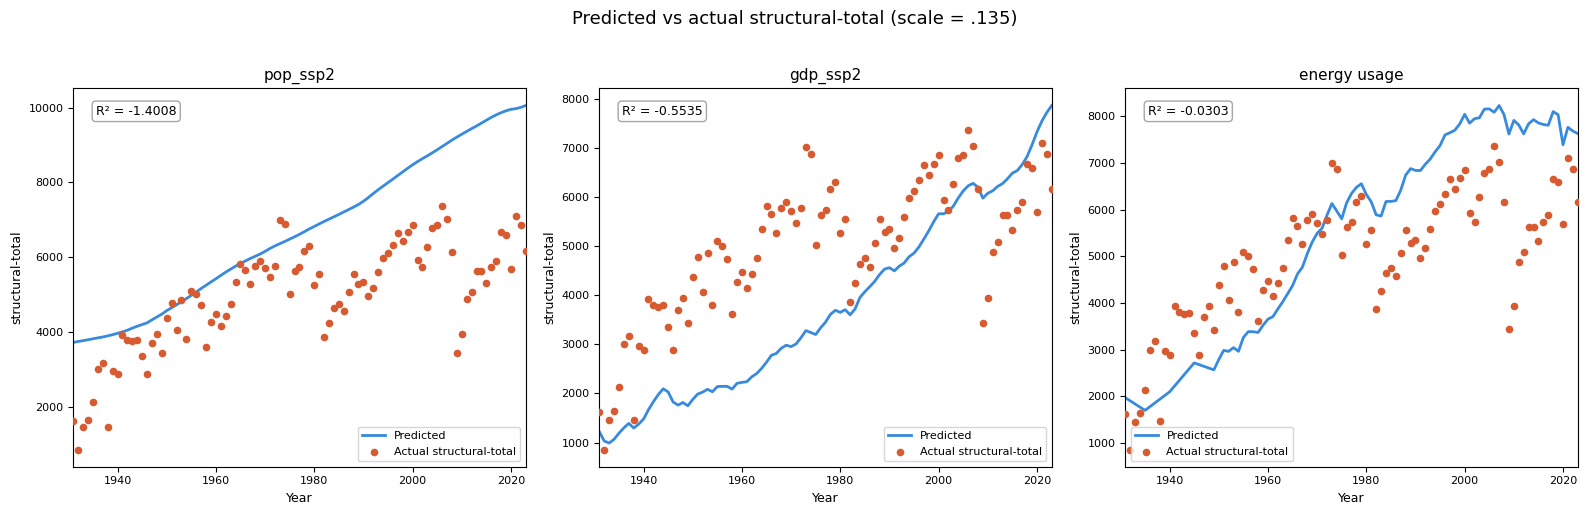

In [106]:
# ── load your dataframe ──────────────────────────────────────────────────────
# df = pd.read_csv("your_file.csv", index_col=0)

# ── scaling constant ─────────────────────────────────────────────────────────
SCALE = 1/7.4

# ── fit regressions on 1950+ data ────────────────────────────────────────────
full_vars = ["pop_ssp2", "gdp_ssp2", "energy usage"]
slopes = {}

for col in full_vars:
    x = df_elasticities[[col]].values
    y = df_elasticities["total-production"].values
    model = LinearRegression().fit(x, y)
    slopes[col] = model.coef_[0]

    print(f"\n{col}")
    print(f"  Slope:     {model.coef_[0]:.6f}")
    print(f"  Intercept: {model.intercept_:.6f}")
    print(f"  R²:        {model.score(x, y):.4f}")

# ── apply scaled slope to predict structural-total (full 1931–2023) ──────────
# predicted structural-total = slope * SCALE * x  for each predictor
years = df_elasticities.index  # 1931–2023

actual_idx  = df_elasticities.index
actual_vals = df_elasticities["structural-total"]

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, col in zip(axes, full_vars):
    predicted_full    = slopes[col] * SCALE * df_elasticities[col]
    predicted_overlap = slopes[col] * SCALE * df_elasticities[col]

    # R² comparing predicted vs actual over 2001–2023 only
    r2_historic = r2_score(actual_vals, predicted_overlap)

    ax.plot(years, predicted_full, color="#378ADD", linewidth=2, label=f"Predicted")
    ax.scatter(actual_idx, actual_vals, color="#D85A30", s=20, zorder=3, label="Actual structural-total")

    ax.set_title(col, fontsize=11)
    ax.set_xlabel("Year", fontsize=9)
    ax.set_ylabel("structural-total", fontsize=9)
    ax.legend(fontsize=8)
    ax.tick_params(labelsize=8)
    ax.set_xlim(1931, 2023)

    # R² annotation in corner
    ax.text(0.05, 0.93, f"R² = {r2_historic:.4f}",
            transform=ax.transAxes, fontsize=9,
            bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="gray", alpha=0.7))

plt.suptitle(f"Predicted vs actual structural-total (scale = .135)",
             fontsize=13, y=1.02)
plt.tight_layout()
plt.show()

### Historic Regression against Structural Steel Production


pop_ssp2
  Slope:     0.000016
  Intercept: 1451.520586
  R²:        0.5403

gdp_ssp2
  Slope:     0.065863
  Intercept: 2936.365739
  R²:        0.5133

energy usage
  Slope:     42.695214
  Intercept: 2185.475590
  R²:        0.6461


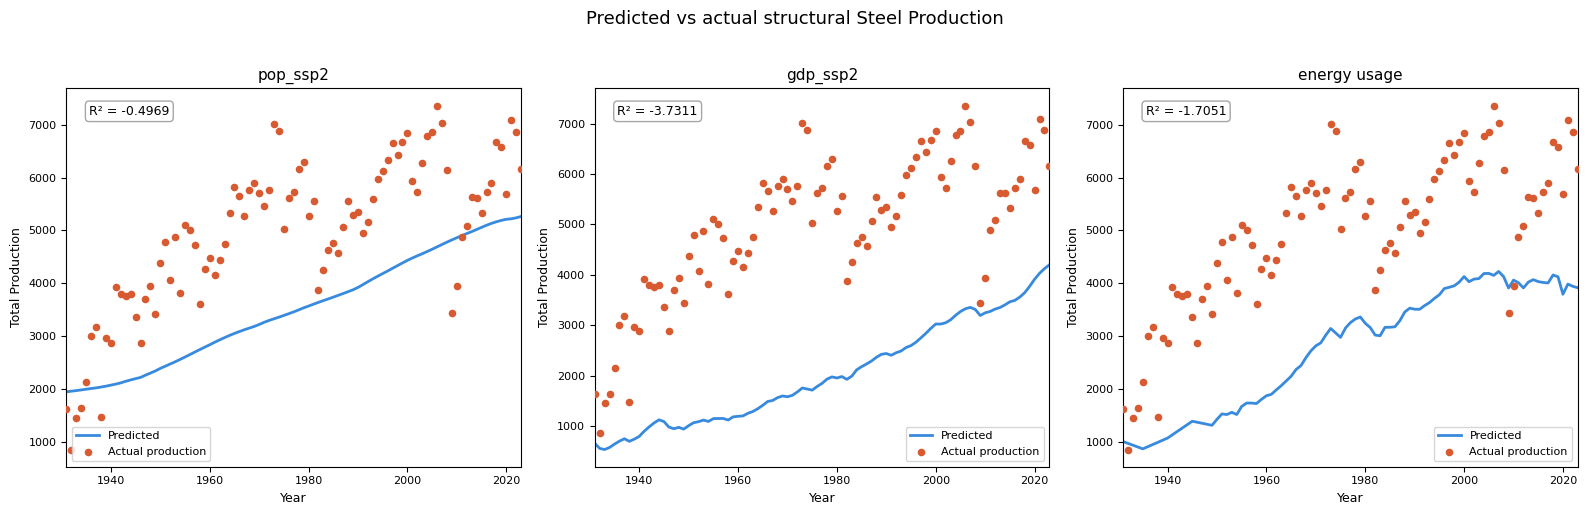

In [107]:
# ── load your dataframe ──────────────────────────────────────────────────────
# df = pd.read_csv("your_file.csv", index_col=0)

# ── scaling constant ─────────────────────────────────────────────────────────
SCALE = 1

# ── fit regressions on 1950+ data ────────────────────────────────────────────
full_vars = ["pop_ssp2", "gdp_ssp2", "energy usage"]
slopes = {}

for col in full_vars:
    x = df_elasticities[[col]].values
    y = df_elasticities["structural-total"].values
    model = LinearRegression().fit(x, y)
    slopes[col] = model.coef_[0]

    print(f"\n{col}")
    print(f"  Slope:     {model.coef_[0]:.6f}")
    print(f"  Intercept: {model.intercept_:.6f}")
    print(f"  R²:        {model.score(x, y):.4f}")

# ── apply scaled slope to predict structural-total (full 1931–2023) ──────────
# predicted structural-total = slope * SCALE * x  for each predictor
years = df_elasticities.index  # 1931–2023

actual_idx  = df_elasticities.index
actual_vals = df_elasticities["structural-total"]

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, col in zip(axes, full_vars):
    predicted_full    = slopes[col] * SCALE * df_elasticities[col]
    predicted_overlap = slopes[col] * SCALE * df_elasticities[col]

    # R² comparing predicted vs actual over 2001–2023 only
    r2_historic = r2_score(actual_vals, predicted_overlap)

    ax.plot(years, predicted_full, color="#378ADD", linewidth=2, label=f"Predicted")
    ax.scatter(actual_idx, actual_vals, color="#D85A30", s=20, zorder=3, label="Actual production")

    ax.set_title(col, fontsize=11)
    ax.set_xlabel("Year", fontsize=9)
    ax.set_ylabel("Total Production", fontsize=9)
    ax.legend(fontsize=8)
    ax.tick_params(labelsize=8)
    ax.set_xlim(1931, 2023)

    # R² annotation in corner
    ax.text(0.05, 0.93, f"R² = {r2_historic:.4f}",
            transform=ax.transAxes, fontsize=9,
            bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="gray", alpha=0.7))

plt.suptitle(f"Predicted vs actual structural Steel Production",
             fontsize=13, y=1.02)
plt.tight_layout()
plt.show()

### Historic Regression against total production


pop_ssp2
  Slope:     0.000222
  Intercept: 21981.509865
  R²:        0.5511

gdp_ssp2
  Slope:     0.912185
  Intercept: 43548.362070
  R²:        0.5026

energy usage
  Slope:     615.244945
  Intercept: 31593.780193
  R²:        0.6849


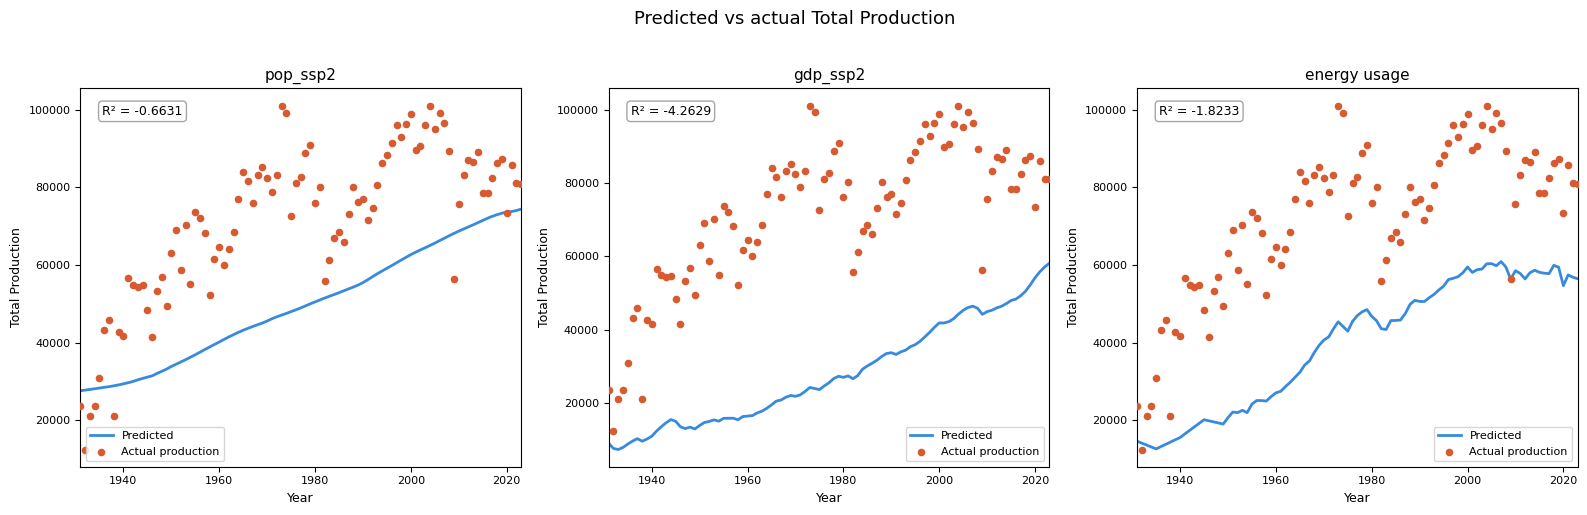

In [108]:
# ── load your dataframe ──────────────────────────────────────────────────────
# df = pd.read_csv("your_file.csv", index_col=0)

# ── scaling constant ─────────────────────────────────────────────────────────
SCALE = 1

# ── fit regressions on 1950+ data ────────────────────────────────────────────
full_vars = ["pop_ssp2", "gdp_ssp2", "energy usage"]
slopes = {}

for col in full_vars:
    x = df_elasticities[[col]].values
    y = df_elasticities["total-production"].values
    model = LinearRegression().fit(x, y)
    slopes[col] = model.coef_[0]

    print(f"\n{col}")
    print(f"  Slope:     {model.coef_[0]:.6f}")
    print(f"  Intercept: {model.intercept_:.6f}")
    print(f"  R²:        {model.score(x, y):.4f}")

# ── apply scaled slope to predict structural-total (full 1931–2023) ──────────
# predicted structural-total = slope * SCALE * x  for each predictor
years = df_elasticities.index  # 1931–2023

actual_idx  = df_elasticities.index
actual_vals = df_elasticities["total-production"]

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, col in zip(axes, full_vars):
    predicted_full    = slopes[col] * SCALE * df_elasticities[col]
    predicted_overlap = slopes[col] * SCALE * df_elasticities[col]

    # R² comparing predicted vs actual over 2001–2023 only
    r2_historic = r2_score(actual_vals, predicted_overlap)

    ax.plot(years, predicted_full, color="#378ADD", linewidth=2, label=f"Predicted")
    ax.scatter(actual_idx, actual_vals, color="#D85A30", s=20, zorder=3, label="Actual production")

    ax.set_title(col, fontsize=11)
    ax.set_xlabel("Year", fontsize=9)
    ax.set_ylabel("Total Production", fontsize=9)
    ax.legend(fontsize=8)
    ax.tick_params(labelsize=8)
    ax.set_xlim(1931, 2023)

    # R² annotation in corner
    ax.text(0.05, 0.93, f"R² = {r2_historic:.4f}",
            transform=ax.transAxes, fontsize=9,
            bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="gray", alpha=0.7))

plt.suptitle(f"Predicted vs actual Total Production",
             fontsize=13, y=1.02)
plt.tight_layout()
plt.show()

## Multivariate Regression

### Against Structural Steel Production

Multivariate regression
  pop_ssp2 slope: -0.000241
  gdp_ssp2 slope: 0.027030
  energy usage slope: 1177.122265
  Intercept:    48000.629893
  R²:           0.7280

  R² vs actual structural-total: -1.5197


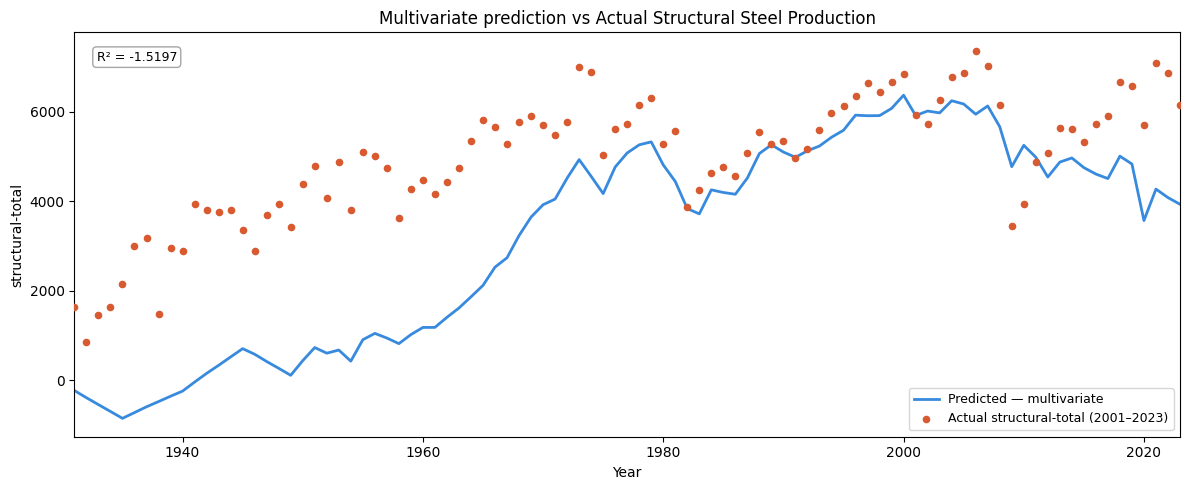

In [109]:
# ── fit multivariate regression on data ────────────────────────────────
SCALE = 1/7.4
full_vars = ["pop_ssp2", "gdp_ssp2", "energy usage"]

X_fit = df_elasticities[full_vars].values
y_fit = df_elasticities["total-production"].values

model = LinearRegression().fit(X_fit, y_fit)

print("Multivariate regression")
for col, coef in zip(full_vars, model.coef_):
    print(f"  {col} slope: {coef:.6f}")
print(f"  Intercept:    {model.intercept_:.6f}")
print(f"  R²:           {model.score(X_fit, y_fit):.4f}")

# ── apply scaled slopes to predict structural-total (full 1931–2023) ─────────
# predicted = SCALE * (slope_1*x_1 + slope_2*x_2 + slope_3*x_3)
predicted_full = SCALE * (df_elasticities[full_vars].values @ model.coef_)

actual_idx  = df_elasticities.index
actual_vals = df_elasticities["structural-total"]

predicted_overlap = SCALE * (df_elasticities.loc[:,full_vars].values @ model.coef_)
r2_historic = r2_score(actual_vals, predicted_overlap)

print(f"\n  R² vs actual structural-total: {r2_historic:.4f}")

# ── plot ──────────────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(df_elasticities.index, predicted_full, color="#378ADD", linewidth=2,
        label=f"Predicted — multivariate")
ax.scatter(actual_idx, actual_vals, color="#D85A30", s=20, zorder=3,
           label="Actual structural-total (2001–2023)")

ax.set_title("Multivariate prediction vs Actual Structural Steel Production", fontsize=12)
ax.set_xlabel("Year", fontsize=10)
ax.set_ylabel("structural-total", fontsize=10)
ax.set_xlim(1931, 2023)
ax.legend(fontsize=9)
ax.text(0.02, 0.93, f"R² = {r2_historic:.4f}",
        transform=ax.transAxes, fontsize=9,
        bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="gray", alpha=0.7))

plt.tight_layout()
plt.show()

### Against Total Steel Production

Multivariate regression
  pop_ssp2 slope: -0.000241
  gdp_ssp2 slope: 0.027030
  energy usage slope: 1177.122265
  Intercept:    48000.629893
  R²:           0.7280

  R² vs actual steel production: 0.7280


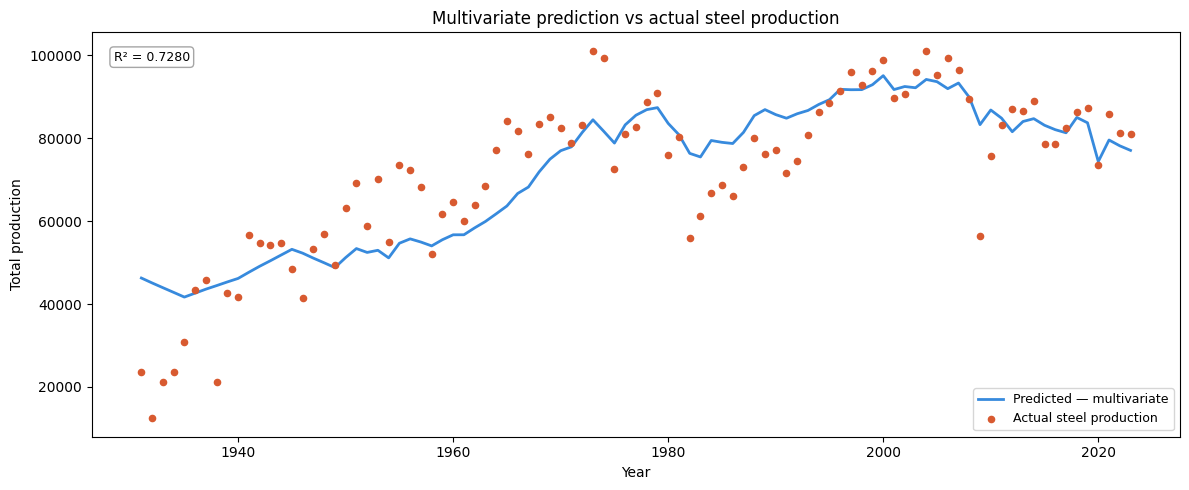

In [110]:
# ── fit multivariate regression on data ──────────────────────────────────────
full_vars = ["pop_ssp2", "gdp_ssp2", "energy usage"]

X_fit = df_elasticities[full_vars].values
y_fit = df_elasticities["total-production"].values

model = LinearRegression().fit(X_fit, y_fit)

print("Multivariate regression")
for col, coef in zip(full_vars, model.coef_):
    print(f"  {col} slope: {coef:.6f}")
print(f"  Intercept:    {model.intercept_:.6f}")
print(f"  R²:           {model.score(X_fit, y_fit):.4f}")

# ── predict — use model.predict() so intercept is included automatically ─────
predicted_full = model.predict(df_elasticities[full_vars].values)

actual_idx  = df_elasticities.index
actual_vals = df_elasticities["total-production"]

r2_historic = r2_score(actual_vals, predicted_full)
print(f"\n  R² vs actual steel production: {r2_historic:.4f}")

# ── plot ──────────────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(actual_idx, predicted_full, color="#378ADD", linewidth=2,
        label="Predicted — multivariate")
ax.scatter(actual_idx, actual_vals, color="#D85A30", s=20, zorder=3,
           label="Actual steel production")

ax.set_title("Multivariate prediction vs actual steel production", fontsize=12)
ax.set_xlabel("Year", fontsize=10)
ax.set_ylabel("Total production", fontsize=10)
ax.legend(fontsize=9,loc = "lower right")
ax.text(0.02, 0.93, f"R² = {r2_historic:.4f}",
        transform=ax.transAxes, fontsize=9,
        bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="gray", alpha=0.7))

plt.tight_layout()
plt.show()

### Fitted against structural Steel production

Multivariate regression
  pop_ssp2 slope: -0.000027
  gdp_ssp2 slope: 0.052545
  energy usage slope: 78.115929
  Intercept:    4222.912349
  R²:           0.6749

  R² vs actual structural steel production: 0.6749


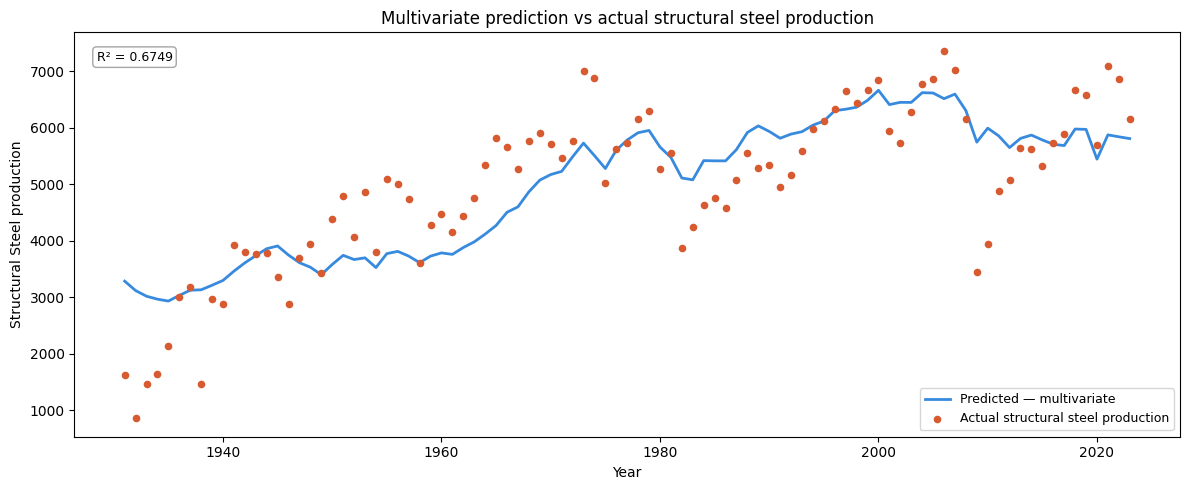

In [111]:
# ── fit multivariate regression on data ──────────────────────────────────────
full_vars = ["pop_ssp2", "gdp_ssp2", "energy usage"]

X_fit = df_elasticities[full_vars].values
y_fit = df_elasticities["structural-total"].values

model = LinearRegression().fit(X_fit, y_fit)

print("Multivariate regression")
for col, coef in zip(full_vars, model.coef_):
    print(f"  {col} slope: {coef:.6f}")
print(f"  Intercept:    {model.intercept_:.6f}")
print(f"  R²:           {model.score(X_fit, y_fit):.4f}")

# ── predict — use model.predict() so intercept is included automatically ─────
predicted_full = model.predict(df_elasticities[full_vars].values)

actual_idx  = df_elasticities.index
actual_vals = df_elasticities["structural-total"]

r2_historic = r2_score(actual_vals, predicted_full)
print(f"\n  R² vs actual structural steel production: {r2_historic:.4f}")

# ── plot ──────────────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(actual_idx, predicted_full, color="#378ADD", linewidth=2,
        label="Predicted — multivariate")
ax.scatter(actual_idx, actual_vals, color="#D85A30", s=20, zorder=3,
           label="Actual structural steel production")

ax.set_title("Multivariate prediction vs actual structural steel production", fontsize=12)
ax.set_xlabel("Year", fontsize=10)
ax.set_ylabel("Structural Steel production", fontsize=10)
ax.legend(fontsize=9,loc = "lower right")
ax.text(0.02, 0.93, f"R² = {r2_historic:.4f}",
        transform=ax.transAxes, fontsize=9,
        bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="gray", alpha=0.7))

plt.tight_layout()
plt.show()

## Levesque Model

Power-law regression (1950–2023)
  pop    — coef: 0.213773,  exponent: 0.662399
  gdp    — coef: 21.083595,  exponent: -4.085588
  energy — coef: 680.733550,  exponent: -20.107704

  R² (full 1931–2023): 0.5776


C:\Users\aorga\AppData\Local\Temp\ipykernel_60020\2756877462.py:17: OptimizeWarning: Covariance of the parameters could not be estimated
  popt, pcov = curve_fit(


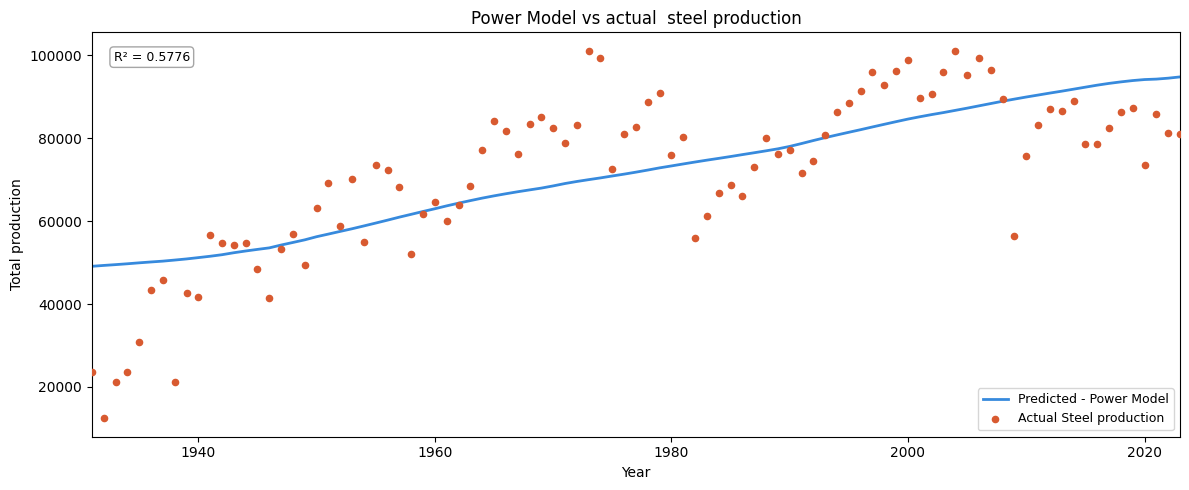

In [112]:
# ── fit on 1950+ ─────────────────────────────────────────────────────────────
df_power_law = df_elasticities

pop    = df_power_law["pop_ssp2"].values
gdp    = df_power_law["gdp_ssp2"].values
energy = df_power_law["energy usage"].values
y      = df_power_law["total-production"].values

# ── model: a*pop^b + c*gdp^d + e*energy^f ────────────────────────────────────
def power_model(X, a, b, c, d, e, f):
    pop, gdp, energy = X
    return a * np.power(pop, b) + c * np.power(gdp, d) + e * np.power(energy, f)

# initial guesses: coefficients=1, exponents=1
p0 = [1, 1, 1, 1, 1, 1]

popt, pcov = curve_fit(
    power_model,
    (pop, gdp, energy),
    y,
    p0=p0,
    maxfev=50000
)

a, b, c, d, e, f = popt

print("Power-law regression (1950–2023)")
print(f"  pop    — coef: {a:.6f},  exponent: {b:.6f}")
print(f"  gdp    — coef: {c:.6f},  exponent: {d:.6f}")
print(f"  energy — coef: {e:.6f},  exponent: {f:.6f}")

# ── predict over full 1931–2023 ───────────────────────────────────────────────
pop_full    = df_elasticities["pop_ssp2"].values
gdp_full    = df_elasticities["gdp_ssp2"].values
energy_full = df_elasticities["energy usage"].values

predicted_full = power_model((pop_full, gdp_full, energy_full), *popt)

actual_vals = df_elasticities["total-production"]
r2 = r2_score(actual_vals, predicted_full)
print(f"\n  R² (full 1931–2023): {r2:.4f}")

# ── plot ──────────────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(df_elasticities.index, predicted_full, color="#378ADD", linewidth=2,
        label="Predicted - Power Model")
ax.scatter(df_elasticities.index, actual_vals, color="#D85A30", s=20, zorder=3,
           label="Actual Steel production")

ax.set_title("Power Model vs actual  steel production", fontsize=12)
ax.set_xlabel("Year", fontsize=10)
ax.set_ylabel("Total production", fontsize=10)
ax.set_xlim(1931, 2023)
ax.legend(fontsize=9)
ax.text(0.02, 0.93, f"R² = {r2:.4f}",
        transform=ax.transAxes, fontsize=9,
        bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="gray", alpha=0.7))

plt.tight_layout()
plt.show()

### Levesque Structural Fit

Power-law regression (1950–2023)
  pop    — coef: 24152.860029,  exponent: -1.622519
  gdp    — coef: -24704.899275,  exponent: 0.652129
  energy — coef: -12865.826047,  exponent: 0.806202

  R² (full 1931–2023): 0.7276


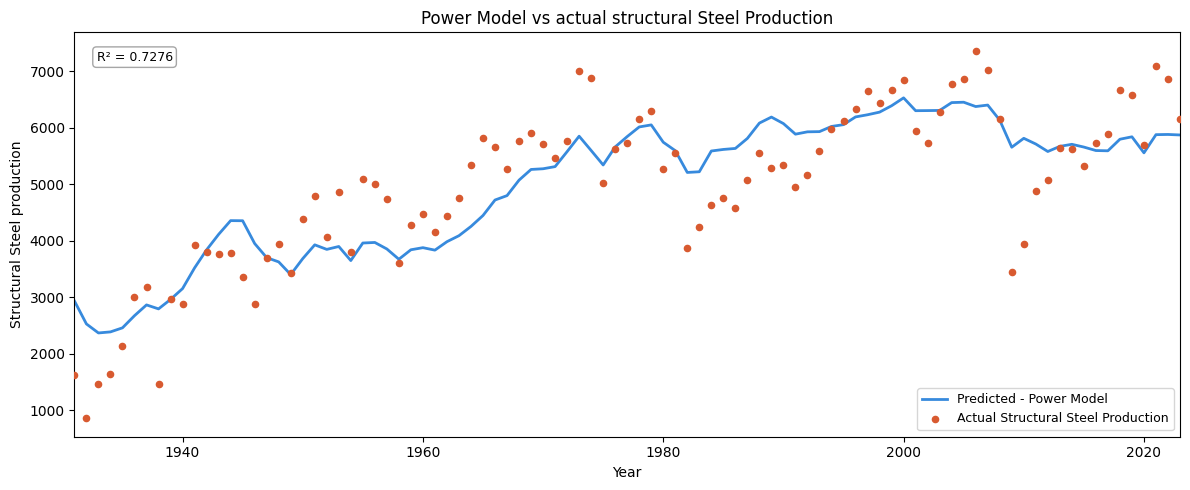

In [113]:
# ── fit on 1950+ ─────────────────────────────────────────────────────────────
df_power_law = df_elasticities

pop    = df_power_law["pop_ssp2"].values
gdp    = df_power_law["gdp_ssp2"].values
energy = df_power_law["energy usage"].values
y      = df_power_law["structural-total"].values

# ── model: a*pop^b + c*gdp^d + e*energy^f ────────────────────────────────────
def power_model(X, a, b, c, d, e, f):
    pop, gdp, energy = X
    return a * np.power(pop, b) * c * np.power(gdp, d) * e * np.power(energy, f)

# initial guesses: coefficients=1, exponents=1
p0 = [1, 1, 1, 1, 1, 1]

popt, pcov = curve_fit(
    power_model,
    (pop, gdp, energy),
    y,
    p0=p0,
    maxfev=50000
)

a, b, c, d, e, f = popt

print("Power-law regression (1950–2023)")
print(f"  pop    — coef: {a:.6f},  exponent: {b:.6f}")
print(f"  gdp    — coef: {c:.6f},  exponent: {d:.6f}")
print(f"  energy — coef: {e:.6f},  exponent: {f:.6f}")

# ── predict over full 1931–2023 ───────────────────────────────────────────────
pop_full    = df_elasticities["pop_ssp2"].values
gdp_full    = df_elasticities["gdp_ssp2"].values
energy_full = df_elasticities["energy usage"].values

predicted_full = power_model((pop_full, gdp_full, energy_full), *popt)

actual_vals = df_elasticities["structural-total"]
r2 = r2_score(actual_vals, predicted_full)
print(f"\n  R² (full 1931–2023): {r2:.4f}")

# ── plot ──────────────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(df_elasticities.index, predicted_full, color="#378ADD", linewidth=2,
        label="Predicted - Power Model")
ax.scatter(df_elasticities.index, actual_vals, color="#D85A30", s=20, zorder=3,
           label="Actual Structural Steel Production")

ax.set_title("Power Model vs actual structural Steel Production", fontsize=12)
ax.set_xlabel("Year", fontsize=10)
ax.set_ylabel("Structural Steel production", fontsize=10)
ax.set_xlim(1931, 2023)
ax.legend(fontsize=9)
ax.text(0.02, 0.93, f"R² = {r2:.4f}",
        transform=ax.transAxes, fontsize=9,
        bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="gray", alpha=0.7))

plt.tight_layout()
plt.show()

In [114]:
print("\nFitted parameters:")
print(f"  pop    — coef: {a:.4f},  exponent: {b:.4f}")
print(f"  gdp    — coef: {c:.4f},  exponent: {d:.4f}")
print(f"  energy — coef: {e:.4f},  exponent: {f:.4f}")

# check the scale of each term's contribution
print("\nMean contribution of each term:")
print(f"  pop term:    {np.mean(a * np.power(pop_full, b)):.2f}")
print(f"  gdp term:    {np.mean(c * np.power(gdp_full, d)):.2f}")
print(f"  energy term: {np.mean(e * np.power(energy_full, f)):.2f}")


Fitted parameters:
  pop    — coef: 24152.8600,  exponent: -1.6225
  gdp    — coef: -24704.8993,  exponent: 0.6521
  energy — coef: -12865.8260,  exponent: 0.8062

Mean contribution of each term:
  pop term:    0.00
  gdp term:    -20228094.74
  energy term: -366712.74


Cobb-Douglas regression
  A (scale):      2065011307386781440.000000
  pop exponent:   -2.553946
  gdp exponent:   1.111548
  energy exponent:0.966487

Handwritten equation:
  ŷ = 2065011307386781440.0000 × pop^-2.5539 × gdp^1.1115 × energy^0.9665

  R²: 0.7036


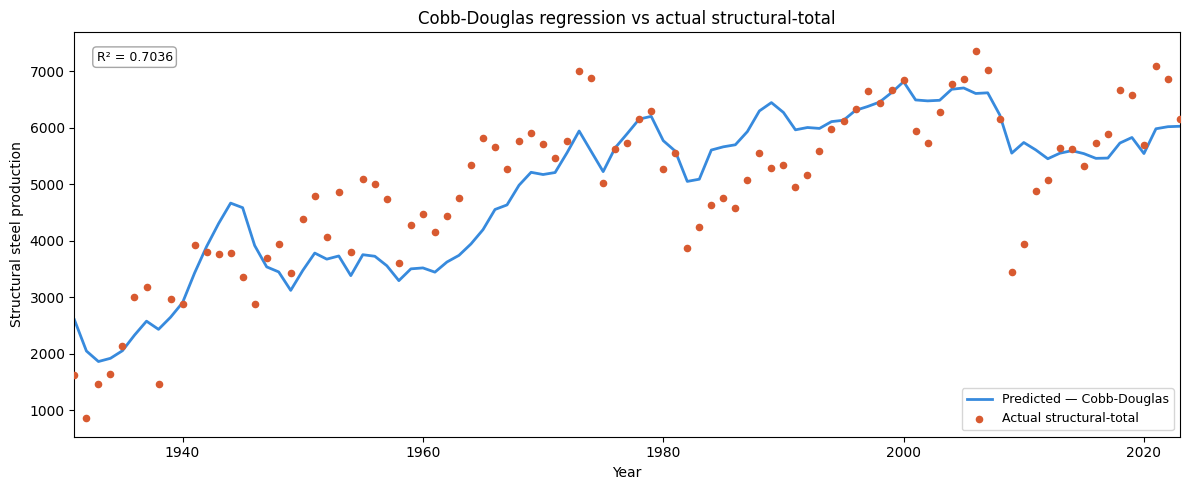

In [115]:
# ── data ──────────────────────────────────────────────────────────────────────
pop    = df_elasticities["pop_ssp2"].values
gdp    = df_elasticities["gdp_ssp2"].values
energy = df_elasticities["energy usage"].values
y      = df_elasticities["structural-total"].values

# ── Cobb-Douglas: y = A * pop^b * gdp^d * energy^f ───────────────────────────
# linearise by taking logs: log(y) = log(A) + b*log(pop) + d*log(gdp) + f*log(energy)
# then fit with OLS — much more stable than curve_fit

log_y      = np.log(y)
log_pop    = np.log(pop)
log_gdp    = np.log(gdp)
log_energy = np.log(energy)

# stack into design matrix with intercept
X = np.column_stack([np.ones(len(y)), log_pop, log_gdp, log_energy])
coeffs, residuals, rank, sv = np.linalg.lstsq(X, log_y, rcond=None)

log_A, b, d, f = coeffs
A = np.exp(log_A)

print("Cobb-Douglas regression")
print(f"  A (scale):      {A:.6f}")
print(f"  pop exponent:   {b:.6f}")
print(f"  gdp exponent:   {d:.6f}")
print(f"  energy exponent:{f:.6f}")
print(f"\nHandwritten equation:")
print(f"  ŷ = {A:.4f} × pop^{b:.4f} × gdp^{d:.4f} × energy^{f:.4f}")

# ── predict ───────────────────────────────────────────────────────────────────
predicted_full = A * np.power(pop, b) * np.power(gdp, d) * np.power(energy, f)

r2 = r2_score(y, predicted_full)
print(f"\n  R²: {r2:.4f}")

# ── plot ──────────────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(df_elasticities.index, predicted_full, color="#378ADD", linewidth=2,
        label="Predicted — Cobb-Douglas")
ax.scatter(df_elasticities.index, y, color="#D85A30", s=20, zorder=3,
           label="Actual structural-total")

ax.set_title("Cobb-Douglas regression vs actual structural-total", fontsize=12)
ax.set_xlabel("Year", fontsize=10)
ax.set_ylabel("Structural steel production", fontsize=10)
ax.set_xlim(df_elasticities.index.min(), df_elasticities.index.max())
ax.legend(fontsize=9)
ax.text(0.02, 0.93, f"R² = {r2:.4f}",
        transform=ax.transAxes, fontsize=9,
        bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="gray", alpha=0.7))

plt.tight_layout()
plt.show()

## Fitting the model based on moving average

In [116]:
df_elasticities

,pop_ssp2,gdp_ssp2,energy usage,structural-total,total-production
1931,124039648.0,9931.000000,23.680000,1630.0,23536.93607
1932,124840471.0,8381.000000,22.869000,860.0,12411.20919
1933,125578763.0,8048.000000,22.058000,1460.0,21075.74094
1934,126373773.0,8667.000000,21.247000,1637.0,23636.72651
1935,127250232.0,9681.000000,20.436000,2142.0,30928.68612
...,...,...,...,...,...
2019,330226227.0,57268.309700,96.595282,6582.0,87300.00000
2020,331515736.0,59395.970000,88.870945,5693.0,73500.00000
2021,332099760.0,61180.334978,93.363948,7095.0,85900.00000
2022,333288000.0,62596.163901,92.382874,6869.0,81200.00000


In [117]:
## Make 2 year MA dataframe

df_MA_2 = df_elasticities[['pop_ssp2', 'gdp_ssp2', 'energy usage','structural-total']].rolling(window=2).mean().dropna()
df_MA_5 = df_elasticities[['pop_ssp2', 'gdp_ssp2', 'energy usage','structural-total']].rolling(window=5).mean().dropna()
df_MA_10 = df_elasticities[['pop_ssp2', 'gdp_ssp2', 'energy usage','structural-total']].rolling(window=10).mean().dropna()



### 2 Year MA elasticities


pop_ssp2
  Slope:     0.000016
  Intercept: 1495.605164
  R²:        0.5688

gdp_ssp2
  Slope:     0.065377
  Intercept: 2967.226934
  R²:        0.5379

energy usage
  Slope:     41.956116
  Intercept: 2241.782505
  R²:        0.6741


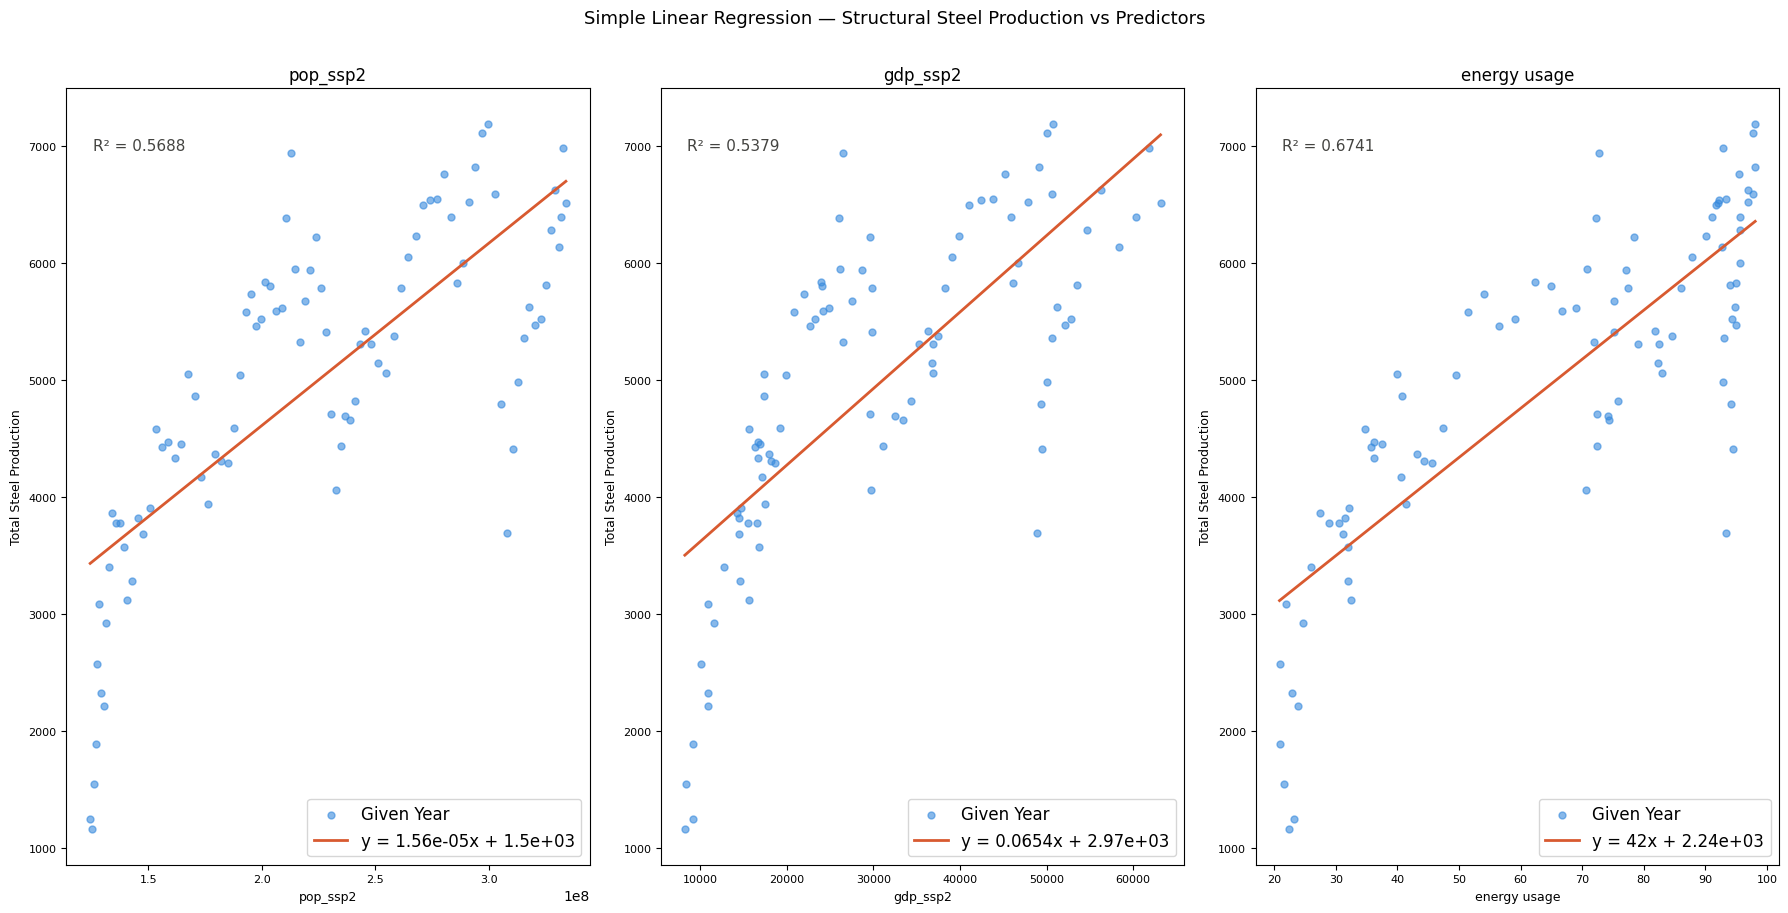

In [118]:
## Get slope and intercept of each one (Univariate regression)
# ── config ───────────────────────────────────────────────────────────────────
full_vars = ["pop_ssp2", "gdp_ssp2", "energy usage"]
all_vars  = full_vars + ["structural-total"]
results   = {}

# ── full-range regression (1931–2023) ────────────────────────────────────────
for col in full_vars:
    x = df_MA_2[[col]].values
    y = df_MA_2["structural-total"].values

    model = LinearRegression().fit(x, y)
    results[col] = {
        "x": x.flatten(), "y": y,
        "slope": model.coef_[0],
        "intercept": model.intercept_,
        "r2": model.score(x, y),
        "label": col,
    }

    print(f"\n{col}")
    print(f"  Slope:     {model.coef_[0]:.6f}")
    print(f"  Intercept: {model.intercept_:.6f}")
    print(f"  R²:        {model.score(x, y):.4f}")


# ── 2x2 plot ─────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(18, 9))
axes = axes.flatten()

for ax, col in zip(axes, all_vars):
    r = results[col]
    x_vals = r["x"]
    y_vals = r["y"]

    x_line = np.linspace(x_vals.min(), x_vals.max(), 200)
    y_line = r["slope"] * x_line + r["intercept"]

    ax.scatter(x_vals, y_vals, alpha=0.6, s=25, color="#378ADD", label="Given Year")
    ax.plot(x_line, y_line, color="#D85A30", linewidth=2,
            label=f"y = {r['slope']:.3g}x + {r['intercept']:.3g}")

    ax.set_title(r["label"], fontsize=12)
    ax.set_xlabel(col.split("\n")[0], fontsize=9)
    ax.set_ylabel("Total Steel Production", fontsize=9)
    ax.legend(fontsize=12)
    ax.text(0.05, 0.92, f"R² = {r['r2']:.4f}", transform=ax.transAxes,
            fontsize=11, color="#444441")
    ax.tick_params(labelsize=8)

plt.suptitle("Simple Linear Regression — Structural Steel Production vs Predictors",
             fontsize=13, y=1.01)
plt.tight_layout()
plt.show()

Multivariate regression
  pop_ssp2 slope: -0.000022
  gdp_ssp2 slope: 0.037052
  energy usage slope: 73.857988
  Intercept:    3876.289182
  R²:           0.6985

  R² vs actual structural steel production: 0.6985


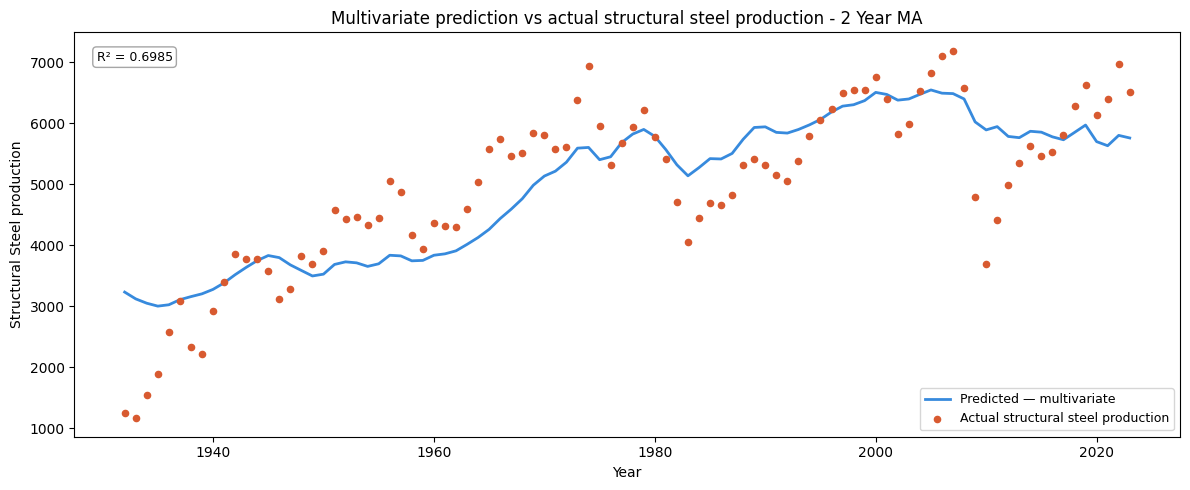

In [119]:
# ── fit multivariate regression on data ──────────────────────────────────────
full_vars = ["pop_ssp2", "gdp_ssp2", "energy usage"]

X_fit = df_MA_2[full_vars].values
y_fit = df_MA_2["structural-total"].values

model = LinearRegression().fit(X_fit, y_fit)

print("Multivariate regression")
for col, coef in zip(full_vars, model.coef_):
    print(f"  {col} slope: {coef:.6f}")
print(f"  Intercept:    {model.intercept_:.6f}")
print(f"  R²:           {model.score(X_fit, y_fit):.4f}")

# ── predict — use model.predict() so intercept is included automatically ─────
predicted_full = model.predict(df_MA_2[full_vars].values)

actual_idx  = df_MA_2.index
actual_vals = df_MA_2["structural-total"]

r2_historic = r2_score(actual_vals, predicted_full)
print(f"\n  R² vs actual structural steel production: {r2_historic:.4f}")

# ── plot ──────────────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(actual_idx, predicted_full, color="#378ADD", linewidth=2,
        label="Predicted — multivariate")
ax.scatter(actual_idx, actual_vals, color="#D85A30", s=20, zorder=3,
           label="Actual structural steel production")

ax.set_title("Multivariate prediction vs actual structural steel production - 2 Year MA", fontsize=12)
ax.set_xlabel("Year", fontsize=10)
ax.set_ylabel("Structural Steel production", fontsize=10)
ax.legend(fontsize=9,loc = "lower right")
ax.text(0.02, 0.93, f"R² = {r2_historic:.4f}",
        transform=ax.transAxes, fontsize=9,
        bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="gray", alpha=0.7))

plt.tight_layout()
plt.show()

Power-law regression (1950–2023)
  pop    — coef: -11007.694293,  exponent: -1.446930
  gdp    — coef: 11192.466323,  exponent: 0.562079
  energy — coef: -5868.258498,  exponent: 0.785455

  R² (full 1931–2023): 0.7518


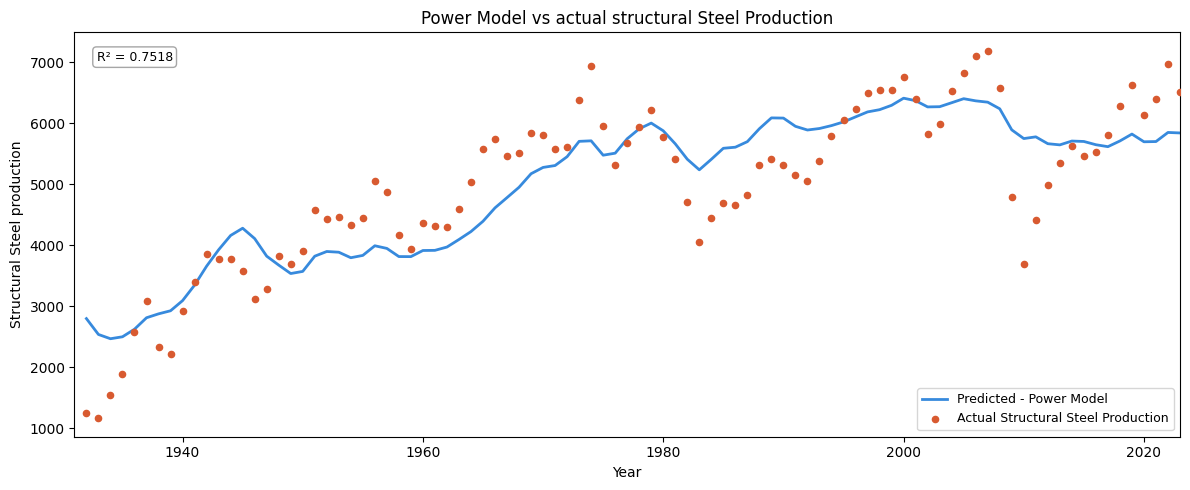

In [120]:
# ── fit on 1950+ ─────────────────────────────────────────────────────────────
df_power_law_MA_2 = df_MA_2

pop    = df_power_law_MA_2["pop_ssp2"].values
gdp    = df_power_law_MA_2["gdp_ssp2"].values
energy = df_power_law_MA_2["energy usage"].values
y      = df_power_law_MA_2["structural-total"].values

# ── model: a*pop^b + c*gdp^d + e*energy^f ────────────────────────────────────
def power_model(X, a, b, c, d, e, f):
    pop, gdp, energy = X
    return a * np.power(pop, b) * c * np.power(gdp, d) * e * np.power(energy, f)

# initial guesses: coefficients=1, exponents=1
p0 = [1, 1, 1, 1, 1, 1]

popt, pcov = curve_fit(
    power_model,
    (pop, gdp, energy),
    y,
    p0=p0,
    maxfev=50000
)

a, b, c, d, e, f = popt

print("Power-law regression (1950–2023)")
print(f"  pop    — coef: {a:.6f},  exponent: {b:.6f}")
print(f"  gdp    — coef: {c:.6f},  exponent: {d:.6f}")
print(f"  energy — coef: {e:.6f},  exponent: {f:.6f}")

# ── predict over full 1931–2023 ───────────────────────────────────────────────
pop_full    = df_MA_2["pop_ssp2"].values
gdp_full    = df_MA_2["gdp_ssp2"].values
energy_full = df_MA_2["energy usage"].values

predicted_full = power_model((pop_full, gdp_full, energy_full), *popt)

actual_vals = df_MA_2["structural-total"]
r2 = r2_score(actual_vals, predicted_full)
print(f"\n  R² (full 1931–2023): {r2:.4f}")

# ── plot ──────────────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(df_MA_2.index, predicted_full, color="#378ADD", linewidth=2,
        label="Predicted - Power Model")
ax.scatter(df_MA_2.index, actual_vals, color="#D85A30", s=20, zorder=3,
           label="Actual Structural Steel Production")

ax.set_title("Power Model vs actual structural Steel Production", fontsize=12)
ax.set_xlabel("Year", fontsize=10)
ax.set_ylabel("Structural Steel production", fontsize=10)
ax.set_xlim(1931, 2023)
ax.legend(fontsize=9)
ax.text(0.02, 0.93, f"R² = {r2:.4f}",
        transform=ax.transAxes, fontsize=9,
        bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="gray", alpha=0.7))

plt.tight_layout()
plt.show()

Cobb-Douglas regression
  A (scale):      74948675242828624.000000
  pop exponent:   -2.303233
  gdp exponent:   0.976515
  energy exponent:0.939722

Handwritten equation:
  ŷ = 74948675242828624.0000 × pop^-2.3032 × gdp^0.9765 × energy^0.9397

  R²: 0.7304


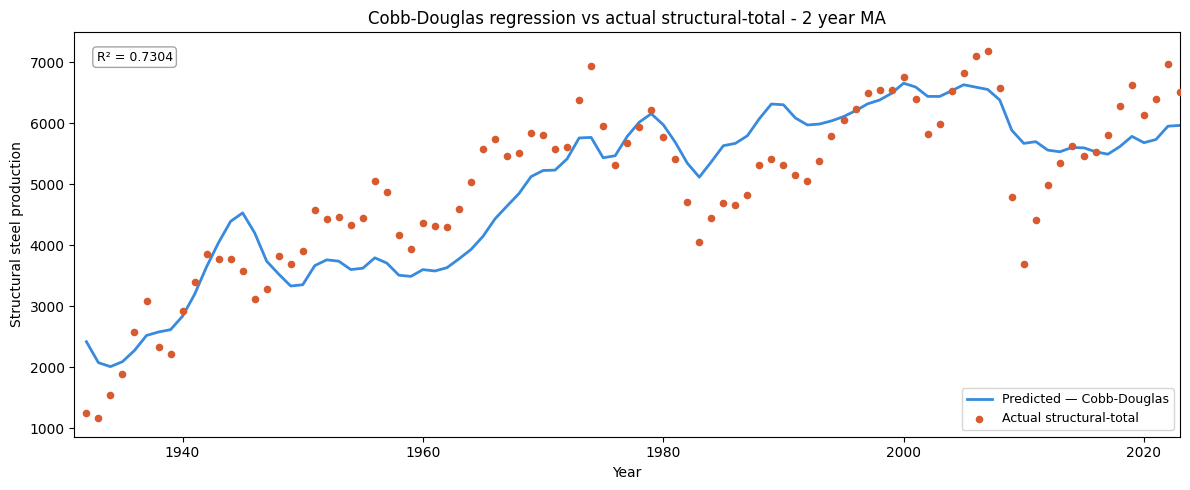

In [121]:
# ── data ──────────────────────────────────────────────────────────────────────
pop    = df_MA_2["pop_ssp2"].values
gdp    = df_MA_2["gdp_ssp2"].values
energy = df_MA_2["energy usage"].values
y      = df_MA_2["structural-total"].values

# ── Cobb-Douglas: y = A * pop^b * gdp^d * energy^f ───────────────────────────
# linearise by taking logs: log(y) = log(A) + b*log(pop) + d*log(gdp) + f*log(energy)
# then fit with OLS — much more stable than curve_fit

log_y      = np.log(y)
log_pop    = np.log(pop)
log_gdp    = np.log(gdp)
log_energy = np.log(energy)

# stack into design matrix with intercept
X = np.column_stack([np.ones(len(y)), log_pop, log_gdp, log_energy])
coeffs, residuals, rank, sv = np.linalg.lstsq(X, log_y, rcond=None)

log_A, b, d, f = coeffs
A = np.exp(log_A)

print("Cobb-Douglas regression")
print(f"  A (scale):      {A:.6f}")
print(f"  pop exponent:   {b:.6f}")
print(f"  gdp exponent:   {d:.6f}")
print(f"  energy exponent:{f:.6f}")
print(f"\nHandwritten equation:")
print(f"  ŷ = {A:.4f} × pop^{b:.4f} × gdp^{d:.4f} × energy^{f:.4f}")

# ── predict ───────────────────────────────────────────────────────────────────
predicted_full = A * np.power(pop, b) * np.power(gdp, d) * np.power(energy, f)

r2 = r2_score(y, predicted_full)
print(f"\n  R²: {r2:.4f}")

# ── plot ──────────────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(df_MA_2.index, predicted_full, color="#378ADD", linewidth=2,
        label="Predicted — Cobb-Douglas")
ax.scatter(df_MA_2.index, y, color="#D85A30", s=20, zorder=3,
           label="Actual structural-total")

ax.set_title("Cobb-Douglas regression vs actual structural-total - 2 year MA", fontsize=12)
ax.set_xlabel("Year", fontsize=10)
ax.set_ylabel("Structural steel production", fontsize=10)
ax.set_xlim(df_elasticities.index.min(), df_elasticities.index.max())
ax.legend(fontsize=9)
ax.text(0.02, 0.93, f"R² = {r2:.4f}",
        transform=ax.transAxes, fontsize=9,
        bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="gray", alpha=0.7))

plt.tight_layout()
plt.show()

### 5 Year MA


pop_ssp2
  Slope:     0.000015
  Intercept: 1722.184287
  R²:        0.6144

gdp_ssp2
  Slope:     0.061829
  Intercept: 3120.070935
  R²:        0.5662

energy usage
  Slope:     39.250920
  Intercept: 2441.858086
  R²:        0.7288


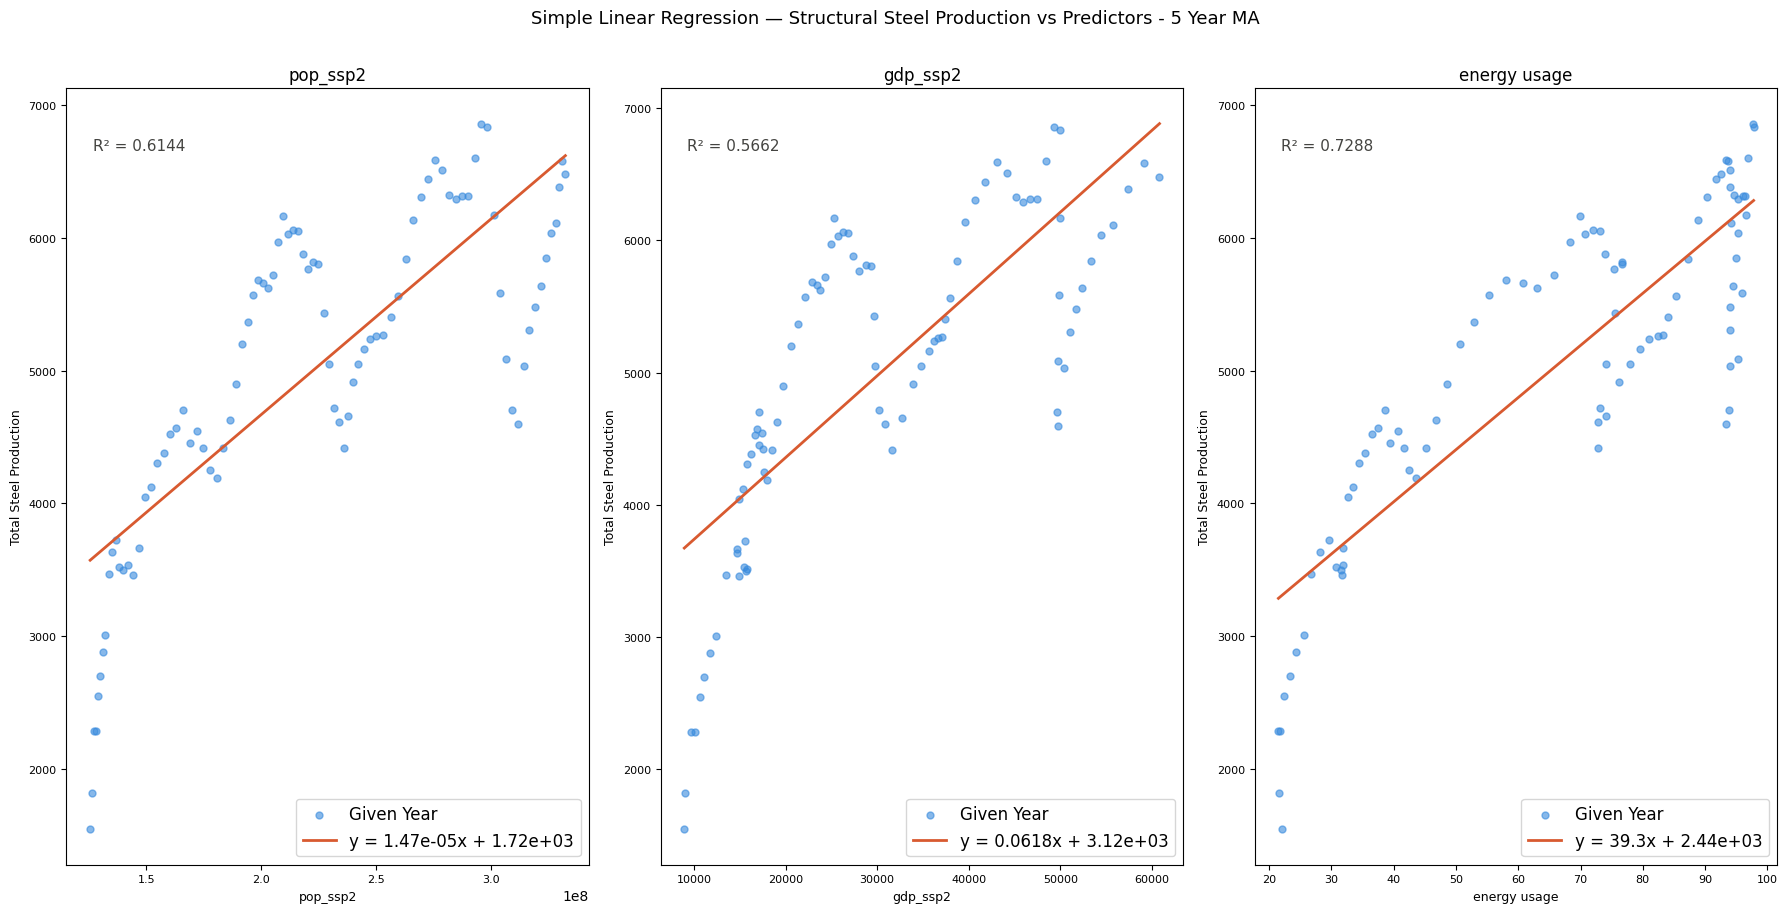

In [122]:
## Elasticiticies
## Get slope and intercept of each one (Univariate regression)
# ── config ───────────────────────────────────────────────────────────────────
full_vars = ["pop_ssp2", "gdp_ssp2", "energy usage"]
all_vars  = full_vars + ["structural-total"]
results   = {}

# ── full-range regression (1931–2023) ────────────────────────────────────────
for col in full_vars:
    x = df_MA_5[[col]].values
    y = df_MA_5["structural-total"].values

    model = LinearRegression().fit(x, y)
    results[col] = {
        "x": x.flatten(), "y": y,
        "slope": model.coef_[0],
        "intercept": model.intercept_,
        "r2": model.score(x, y),
        "label": col,
    }

    print(f"\n{col}")
    print(f"  Slope:     {model.coef_[0]:.6f}")
    print(f"  Intercept: {model.intercept_:.6f}")
    print(f"  R²:        {model.score(x, y):.4f}")


# ── 2x2 plot ─────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(18, 9))
axes = axes.flatten()

for ax, col in zip(axes, all_vars):
    r = results[col]
    x_vals = r["x"]
    y_vals = r["y"]

    x_line = np.linspace(x_vals.min(), x_vals.max(), 200)
    y_line = r["slope"] * x_line + r["intercept"]

    ax.scatter(x_vals, y_vals, alpha=0.6, s=25, color="#378ADD", label="Given Year")
    ax.plot(x_line, y_line, color="#D85A30", linewidth=2,
            label=f"y = {r['slope']:.3g}x + {r['intercept']:.3g}")

    ax.set_title(r["label"], fontsize=12)
    ax.set_xlabel(col.split("\n")[0], fontsize=9)
    ax.set_ylabel("Total Steel Production", fontsize=9)
    ax.legend(fontsize=12)
    ax.text(0.05, 0.92, f"R² = {r['r2']:.4f}", transform=ax.transAxes,
            fontsize=11, color="#444441")
    ax.tick_params(labelsize=8)

plt.suptitle("Simple Linear Regression — Structural Steel Production vs Predictors - 5 Year MA",
             fontsize=13, y=1.01)
plt.tight_layout()
plt.show()

Multivariate regression
  pop_ssp2 slope: -0.000006
  gdp_ssp2 slope: -0.024013
  energy usage slope: 66.593746
  Intercept:    2765.291387
  R²:           0.7589

  R² vs actual structural steel production: 0.7589


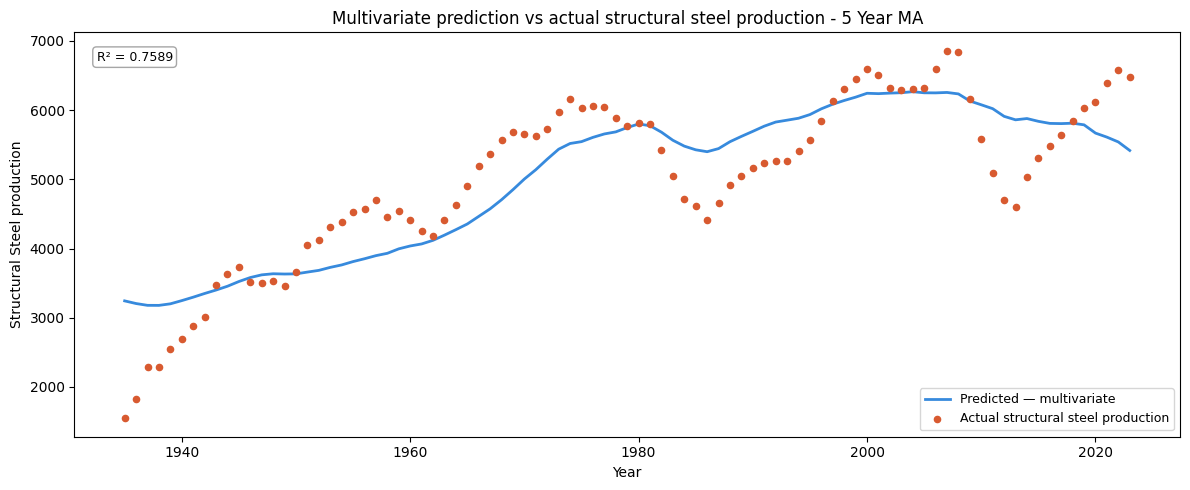

In [123]:
# ── fit multivariate regression on data ──────────────────────────────────────
full_vars = ["pop_ssp2", "gdp_ssp2", "energy usage"]

X_fit = df_MA_5[full_vars].values
y_fit = df_MA_5["structural-total"].values

model = LinearRegression().fit(X_fit, y_fit)

print("Multivariate regression")
for col, coef in zip(full_vars, model.coef_):
    print(f"  {col} slope: {coef:.6f}")
print(f"  Intercept:    {model.intercept_:.6f}")
print(f"  R²:           {model.score(X_fit, y_fit):.4f}")

# ── predict — use model.predict() so intercept is included automatically ─────
predicted_full = model.predict(df_MA_5[full_vars].values)

actual_idx  = df_MA_5.index
actual_vals = df_MA_5["structural-total"]

r2_historic = r2_score(actual_vals, predicted_full)
print(f"\n  R² vs actual structural steel production: {r2_historic:.4f}")

# ── plot ──────────────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(actual_idx, predicted_full, color="#378ADD", linewidth=2,
        label="Predicted — multivariate")
ax.scatter(actual_idx, actual_vals, color="#D85A30", s=20, zorder=3,
           label="Actual structural steel production")

ax.set_title("Multivariate prediction vs actual structural steel production - 5 Year MA", fontsize=12)
ax.set_xlabel("Year", fontsize=10)
ax.set_ylabel("Structural Steel production", fontsize=10)
ax.legend(fontsize=9,loc = "lower right")
ax.text(0.02, 0.93, f"R² = {r2_historic:.4f}",
        transform=ax.transAxes, fontsize=9,
        bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="gray", alpha=0.7))

plt.tight_layout()
plt.show()

Power-law regression (1950–2023)
  pop    — coef: -895.467276,  exponent: -0.858494
  gdp    — coef: 887.077782,  exponent: 0.183148
  energy — coef: -514.050962,  exponent: 0.800685

  R² (full 1931–2023): 0.8027


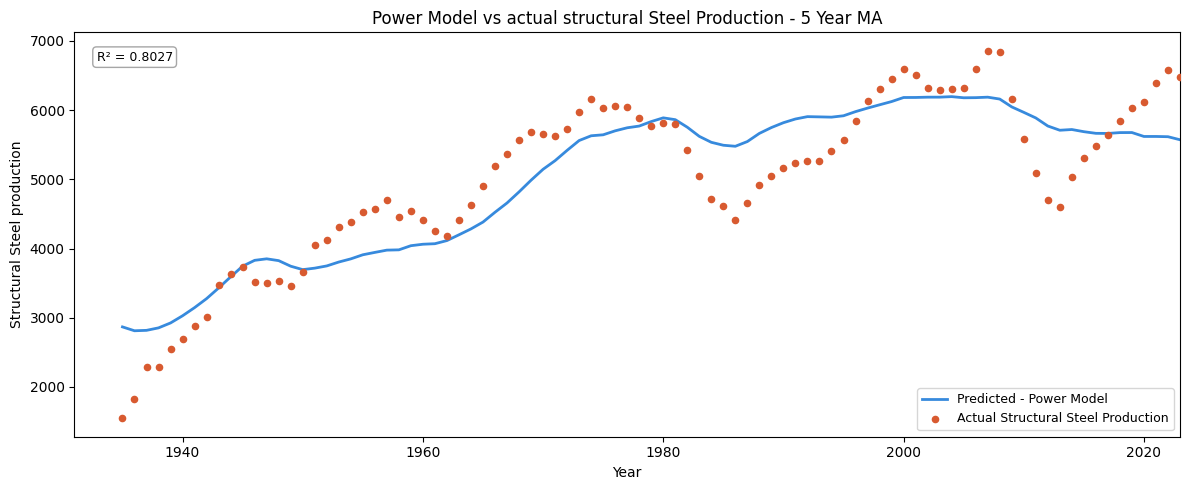

In [124]:
# ── fit on 1950+ ─────────────────────────────────────────────────────────────
df_power_law_MA_5 = df_MA_5

pop    = df_power_law_MA_5["pop_ssp2"].values
gdp    = df_power_law_MA_5["gdp_ssp2"].values
energy = df_power_law_MA_5["energy usage"].values
y      = df_power_law_MA_5["structural-total"].values

# ── model: a*pop^b + c*gdp^d + e*energy^f ────────────────────────────────────
def power_model(X, a, b, c, d, e, f):
    pop, gdp, energy = X
    return a * np.power(pop, b) * c * np.power(gdp, d) * e * np.power(energy, f)

# initial guesses: coefficients=1, exponents=1
p0 = [1, 1, 1, 1, 1, 1]

popt, pcov = curve_fit(
    power_model,
    (pop, gdp, energy),
    y,
    p0=p0,
    maxfev=50000
)

a, b, c, d, e, f = popt

print("Power-law regression (1950–2023)")
print(f"  pop    — coef: {a:.6f},  exponent: {b:.6f}")
print(f"  gdp    — coef: {c:.6f},  exponent: {d:.6f}")
print(f"  energy — coef: {e:.6f},  exponent: {f:.6f}")

# ── predict over full 1931–2023 ───────────────────────────────────────────────
pop_full    = df_power_law_MA_5["pop_ssp2"].values
gdp_full    = df_power_law_MA_5["gdp_ssp2"].values
energy_full = df_power_law_MA_5["energy usage"].values

predicted_full = power_model((pop_full, gdp_full, energy_full), *popt)

actual_vals = df_power_law_MA_5["structural-total"]
r2 = r2_score(actual_vals, predicted_full)
print(f"\n  R² (full 1931–2023): {r2:.4f}")

# ── plot ──────────────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(df_power_law_MA_5.index, predicted_full, color="#378ADD", linewidth=2,
        label="Predicted - Power Model")
ax.scatter(df_power_law_MA_5.index, actual_vals, color="#D85A30", s=20, zorder=3,
           label="Actual Structural Steel Production")

ax.set_title("Power Model vs actual structural Steel Production - 5 Year MA", fontsize=12)
ax.set_xlabel("Year", fontsize=10)
ax.set_ylabel("Structural Steel production", fontsize=10)
ax.set_xlim(1931, 2023)
ax.legend(fontsize=9)
ax.text(0.02, 0.93, f"R² = {r2:.4f}",
        transform=ax.transAxes, fontsize=9,
        bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="gray", alpha=0.7))

plt.tight_layout()
plt.show()

Cobb-Douglas regression
  A (scale):      2778587896058.882324
  pop exponent:   -1.491202
  gdp exponent:   0.440055
  energy exponent:0.966823

Handwritten equation:
  ŷ = 2778587896058.8823 × pop^-1.4912 × gdp^0.4401 × energy^0.9668

  R²: 0.7887


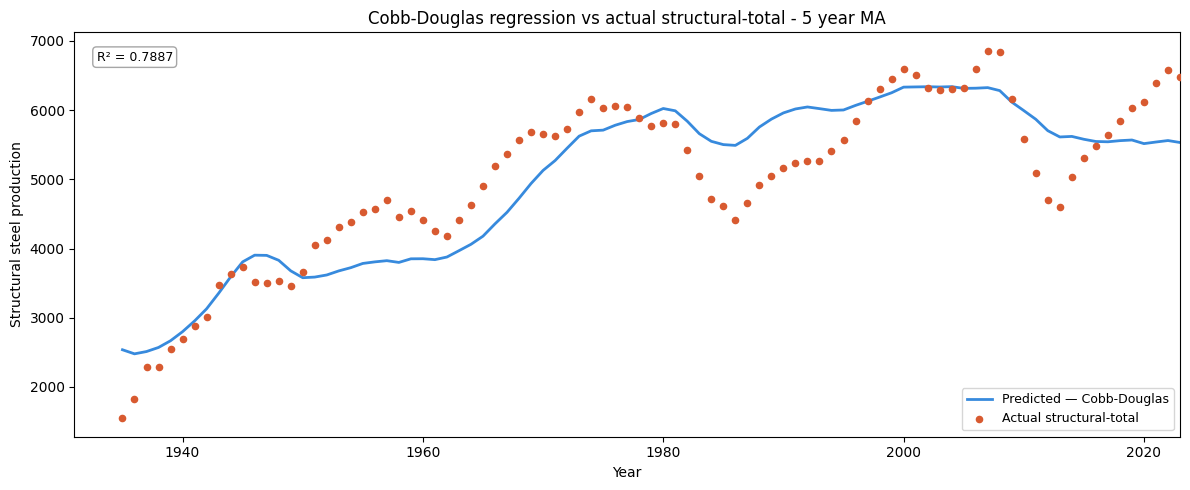

In [125]:
# ── data ──────────────────────────────────────────────────────────────────────
pop    = df_MA_5["pop_ssp2"].values
gdp    = df_MA_5["gdp_ssp2"].values
energy = df_MA_5["energy usage"].values
y      = df_MA_5["structural-total"].values

# ── Cobb-Douglas: y = A * pop^b * gdp^d * energy^f ───────────────────────────
# linearise by taking logs: log(y) = log(A) + b*log(pop) + d*log(gdp) + f*log(energy)
# then fit with OLS — much more stable than curve_fit

log_y      = np.log(y)
log_pop    = np.log(pop)
log_gdp    = np.log(gdp)
log_energy = np.log(energy)

# stack into design matrix with intercept
X = np.column_stack([np.ones(len(y)), log_pop, log_gdp, log_energy])
coeffs, residuals, rank, sv = np.linalg.lstsq(X, log_y, rcond=None)

log_A, b, d, f = coeffs
A = np.exp(log_A)

print("Cobb-Douglas regression")
print(f"  A (scale):      {A:.6f}")
print(f"  pop exponent:   {b:.6f}")
print(f"  gdp exponent:   {d:.6f}")
print(f"  energy exponent:{f:.6f}")
print(f"\nHandwritten equation:")
print(f"  ŷ = {A:.4f} × pop^{b:.4f} × gdp^{d:.4f} × energy^{f:.4f}")

# ── predict ───────────────────────────────────────────────────────────────────
predicted_full = A * np.power(pop, b) * np.power(gdp, d) * np.power(energy, f)

r2 = r2_score(y, predicted_full)
print(f"\n  R²: {r2:.4f}")

# ── plot ──────────────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(df_MA_5.index, predicted_full, color="#378ADD", linewidth=2,
        label="Predicted — Cobb-Douglas")
ax.scatter(df_MA_5.index, y, color="#D85A30", s=20, zorder=3,
           label="Actual structural-total")

ax.set_title("Cobb-Douglas regression vs actual structural-total - 5 year MA", fontsize=12)
ax.set_xlabel("Year", fontsize=10)
ax.set_ylabel("Structural steel production", fontsize=10)
ax.set_xlim(df_elasticities.index.min(), df_elasticities.index.max())
ax.legend(fontsize=9)
ax.text(0.02, 0.93, f"R² = {r2:.4f}",
        transform=ax.transAxes, fontsize=9,
        bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="gray", alpha=0.7))

plt.tight_layout()
plt.show()

### 10 Year MA


pop_ssp2
  Slope:     0.000014
  Intercept: 1987.139280
  R²:        0.6543

gdp_ssp2
  Slope:     0.057369
  Intercept: 3314.205076
  R²:        0.5828

energy usage
  Slope:     36.040428
  Intercept: 2683.141759
  R²:        0.7708


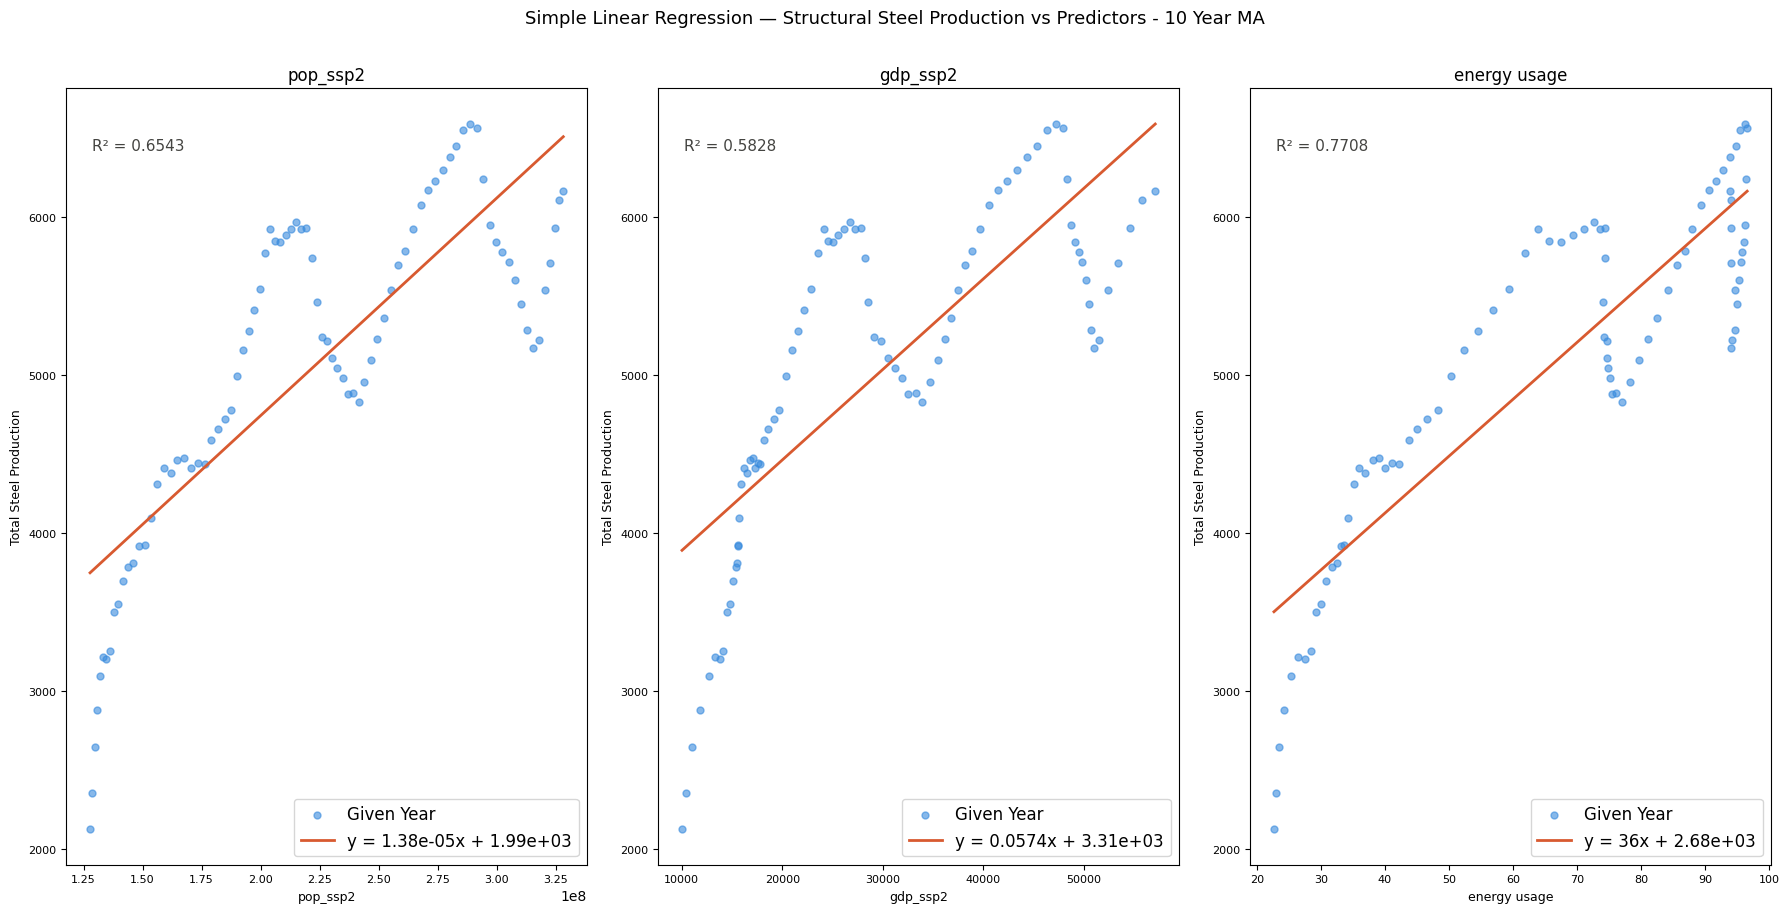

In [126]:
## Get slope and intercept of each one (Univariate regression)
# ── config ───────────────────────────────────────────────────────────────────
full_vars = ["pop_ssp2", "gdp_ssp2", "energy usage"]
all_vars  = full_vars + ["structural-total"]
results   = {}

# ── full-range regression (1931–2023) ────────────────────────────────────────
for col in full_vars:
    x = df_MA_10[[col]].values
    y = df_MA_10["structural-total"].values

    model = LinearRegression().fit(x, y)
    results[col] = {
        "x": x.flatten(), "y": y,
        "slope": model.coef_[0],
        "intercept": model.intercept_,
        "r2": model.score(x, y),
        "label": col,
    }

    print(f"\n{col}")
    print(f"  Slope:     {model.coef_[0]:.6f}")
    print(f"  Intercept: {model.intercept_:.6f}")
    print(f"  R²:        {model.score(x, y):.4f}")


# ── 2x2 plot ─────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(18, 9))
axes = axes.flatten()

for ax, col in zip(axes, all_vars):
    r = results[col]
    x_vals = r["x"]
    y_vals = r["y"]

    x_line = np.linspace(x_vals.min(), x_vals.max(), 200)
    y_line = r["slope"] * x_line + r["intercept"]

    ax.scatter(x_vals, y_vals, alpha=0.6, s=25, color="#378ADD", label="Given Year")
    ax.plot(x_line, y_line, color="#D85A30", linewidth=2,
            label=f"y = {r['slope']:.3g}x + {r['intercept']:.3g}")

    ax.set_title(r["label"], fontsize=12)
    ax.set_xlabel(col.split("\n")[0], fontsize=9)
    ax.set_ylabel("Total Steel Production", fontsize=9)
    ax.legend(fontsize=12)
    ax.text(0.05, 0.92, f"R² = {r['r2']:.4f}", transform=ax.transAxes,
            fontsize=11, color="#444441")
    ax.tick_params(labelsize=8)

plt.suptitle("Simple Linear Regression — Structural Steel Production vs Predictors - 10 Year MA",
             fontsize=13, y=1.01)
plt.tight_layout()
plt.show()

Multivariate regression
  pop_ssp2 slope: 0.000014
  gdp_ssp2 slope: -0.102031
  energy usage slope: 57.211968
  Intercept:    1351.963170
  R²:           0.8341

  R² vs actual structural steel production: 0.8341


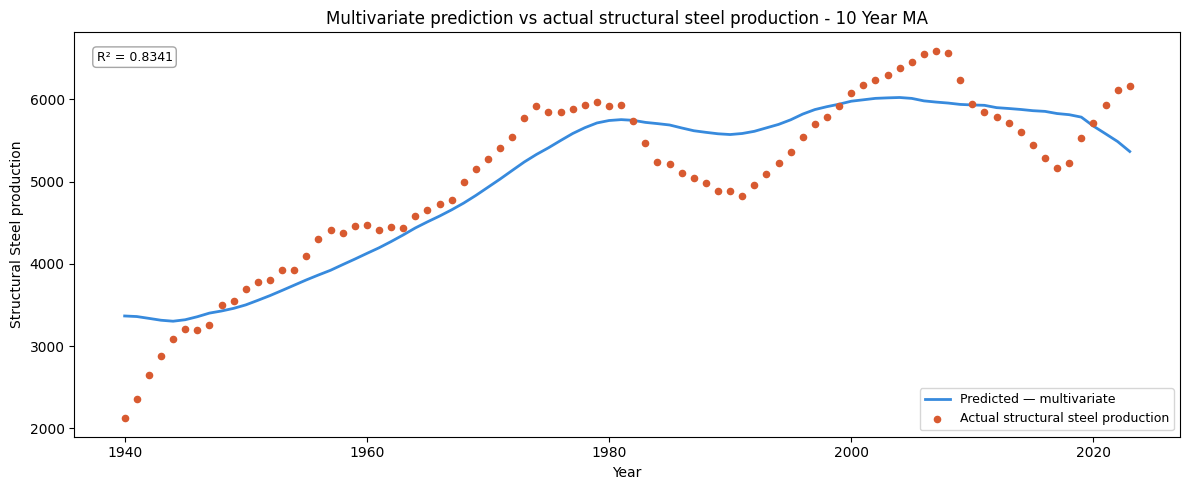

In [127]:
# ── fit multivariate regression on data ──────────────────────────────────────
full_vars = ["pop_ssp2", "gdp_ssp2", "energy usage"]

X_fit = df_MA_10[full_vars].values
y_fit = df_MA_10["structural-total"].values

model = LinearRegression().fit(X_fit, y_fit)

print("Multivariate regression")
for col, coef in zip(full_vars, model.coef_):
    print(f"  {col} slope: {coef:.6f}")
print(f"  Intercept:    {model.intercept_:.6f}")
print(f"  R²:           {model.score(X_fit, y_fit):.4f}")

# ── predict — use model.predict() so intercept is included automatically ─────
predicted_full = model.predict(df_MA_10[full_vars].values)

actual_idx  = df_MA_10.index
actual_vals = df_MA_10["structural-total"]

r2_historic = r2_score(actual_vals, predicted_full)
print(f"\n  R² vs actual structural steel production: {r2_historic:.4f}")

# ── plot ──────────────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(actual_idx, predicted_full, color="#378ADD", linewidth=2,
        label="Predicted — multivariate")
ax.scatter(actual_idx, actual_vals, color="#D85A30", s=20, zorder=3,
           label="Actual structural steel production")

ax.set_title("Multivariate prediction vs actual structural steel production - 10 Year MA", fontsize=12)
ax.set_xlabel("Year", fontsize=10)
ax.set_ylabel("Structural Steel production", fontsize=10)
ax.legend(fontsize=9,loc = "lower right")
ax.text(0.02, 0.93, f"R² = {r2_historic:.4f}",
        transform=ax.transAxes, fontsize=9,
        bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="gray", alpha=0.7))

plt.tight_layout()
plt.show()

Power-law regression (1950–2023)
  pop    — coef: 25.558625,  exponent: -0.029118
  gdp    — coef: -25.484530,  exponent: -0.320384
  energy — coef: -13.728521,  exponent: 0.791182

  R² (full 1931–2023): 0.8574


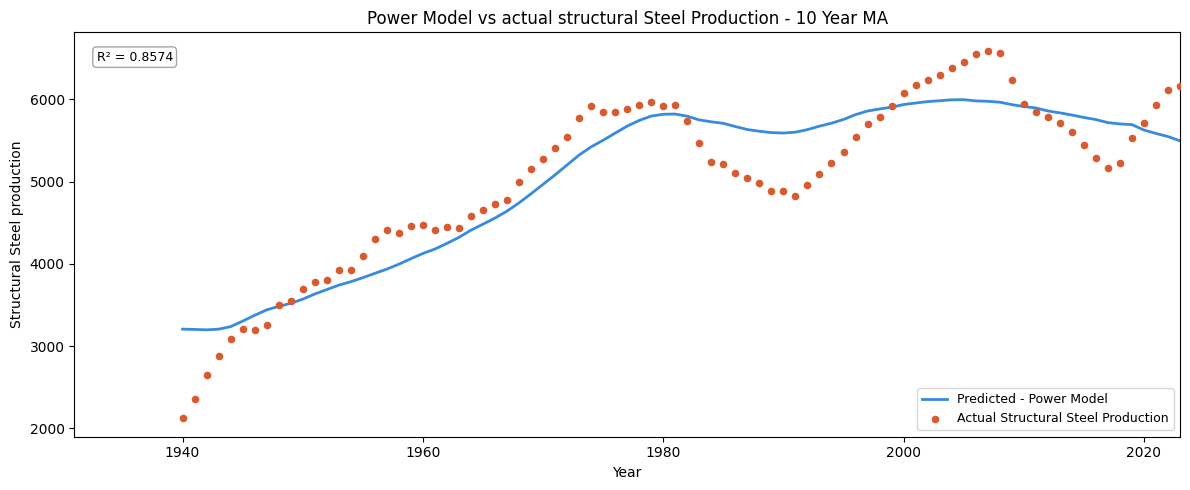

In [128]:
# ── data ─────────────────────────────────────────────────────────────
df_power_law_MA_10 = df_MA_10

pop    = df_power_law_MA_10["pop_ssp2"].values
gdp    = df_power_law_MA_10["gdp_ssp2"].values
energy = df_power_law_MA_10["energy usage"].values
y      = df_power_law_MA_10["structural-total"].values

# ── model: a*pop^b + c*gdp^d + e*energy^f ────────────────────────────────────
def power_model(X, a, b, c, d, e, f):
    pop, gdp, energy = X
    return a * np.power(pop, b) * c * np.power(gdp, d) * e * np.power(energy, f)

# initial guesses: coefficients=1, exponents=1
p0 = [1, 1, 1, 1, 1, 1]

popt, pcov = curve_fit(
    power_model,
    (pop, gdp, energy),
    y,
    p0=p0,
    maxfev=50000
)

a, b, c, d, e, f = popt

print("Power-law regression (1950–2023)")
print(f"  pop    — coef: {a:.6f},  exponent: {b:.6f}")
print(f"  gdp    — coef: {c:.6f},  exponent: {d:.6f}")
print(f"  energy — coef: {e:.6f},  exponent: {f:.6f}")

# ── predict over full 1931–2023 ───────────────────────────────────────────────
pop_full    = df_power_law_MA_10["pop_ssp2"].values
gdp_full    = df_power_law_MA_10["gdp_ssp2"].values
energy_full = df_power_law_MA_10["energy usage"].values

predicted_full = power_model((pop_full, gdp_full, energy_full), *popt)

actual_vals = df_power_law_MA_10["structural-total"]
r2 = r2_score(actual_vals, predicted_full)
print(f"\n  R² (full 1931–2023): {r2:.4f}")

# ── plot ──────────────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(df_power_law_MA_10.index, predicted_full, color="#378ADD", linewidth=2,
        label="Predicted - Power Model")
ax.scatter(df_power_law_MA_10.index, actual_vals, color="#D85A30", s=20, zorder=3,
           label="Actual Structural Steel Production")

ax.set_title("Power Model vs actual structural Steel Production - 10 Year MA", fontsize=12)
ax.set_xlabel("Year", fontsize=10)
ax.set_ylabel("Structural Steel production", fontsize=10)
ax.set_xlim(1931, 2023)
ax.legend(fontsize=9)
ax.text(0.02, 0.93, f"R² = {r2:.4f}",
        transform=ax.transAxes, fontsize=9,
        bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="gray", alpha=0.7))

plt.tight_layout()
plt.show()

Cobb-Douglas regression
  A (scale):      4191214.203341
  pop exponent:   -0.464681
  gdp exponent:   -0.153113
  energy exponent:0.911337

Handwritten equation:
  ŷ = 4191214.2033 × pop^-0.4647 × gdp^-0.1531 × energy^0.9113

  R²: 0.8511


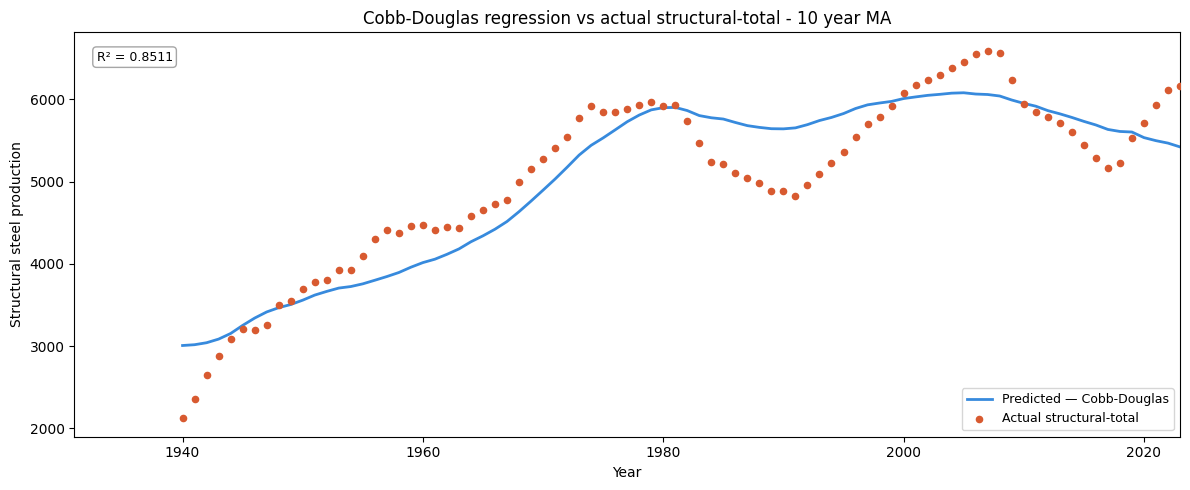

In [129]:
# ── data ──────────────────────────────────────────────────────────────────────
pop    = df_MA_10["pop_ssp2"].values
gdp    = df_MA_10["gdp_ssp2"].values
energy = df_MA_10["energy usage"].values
y      = df_MA_10["structural-total"].values

# ── Cobb-Douglas: y = A * pop^b * gdp^d * energy^f ───────────────────────────
# linearise by taking logs: log(y) = log(A) + b*log(pop) + d*log(gdp) + f*log(energy)
# then fit with OLS — much more stable than curve_fit

log_y      = np.log(y)
log_pop    = np.log(pop)
log_gdp    = np.log(gdp)
log_energy = np.log(energy)

# stack into design matrix with intercept
X = np.column_stack([np.ones(len(y)), log_pop, log_gdp, log_energy])
coeffs, residuals, rank, sv = np.linalg.lstsq(X, log_y, rcond=None)

log_A, b, d, f = coeffs
A = np.exp(log_A)

print("Cobb-Douglas regression")
print(f"  A (scale):      {A:.6f}")
print(f"  pop exponent:   {b:.6f}")
print(f"  gdp exponent:   {d:.6f}")
print(f"  energy exponent:{f:.6f}")
print(f"\nHandwritten equation:")
print(f"  ŷ = {A:.4f} × pop^{b:.4f} × gdp^{d:.4f} × energy^{f:.4f}")

# ── predict ───────────────────────────────────────────────────────────────────
predicted_full = A * np.power(pop, b) * np.power(gdp, d) * np.power(energy, f)

r2 = r2_score(y, predicted_full)
print(f"\n  R²: {r2:.4f}")

# ── plot ──────────────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(df_MA_10.index, predicted_full, color="#378ADD", linewidth=2,
        label="Predicted — Cobb-Douglas")
ax.scatter(df_MA_10.index, y, color="#D85A30", s=20, zorder=3,
           label="Actual structural-total")

ax.set_title("Cobb-Douglas regression vs actual structural-total - 10 year MA", fontsize=12)
ax.set_xlabel("Year", fontsize=10)
ax.set_ylabel("Structural steel production", fontsize=10)
ax.set_xlim(df_elasticities.index.min(), df_elasticities.index.max())
ax.legend(fontsize=9)
ax.text(0.02, 0.93, f"R² = {r2:.4f}",
        transform=ax.transAxes, fontsize=9,
        bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="gray", alpha=0.7))

plt.tight_layout()
plt.show()

In [130]:
df_steel['structural-total'].iloc[1:]

1932     860
1933    1460
1934    1637
1935    2142
1936    3002
        ... 
2019    6582
2020    5693
2021    7095
2022    6869
2023    6157
Name: structural-total, Length: 92, dtype: int64

## 2 Year Model Comp

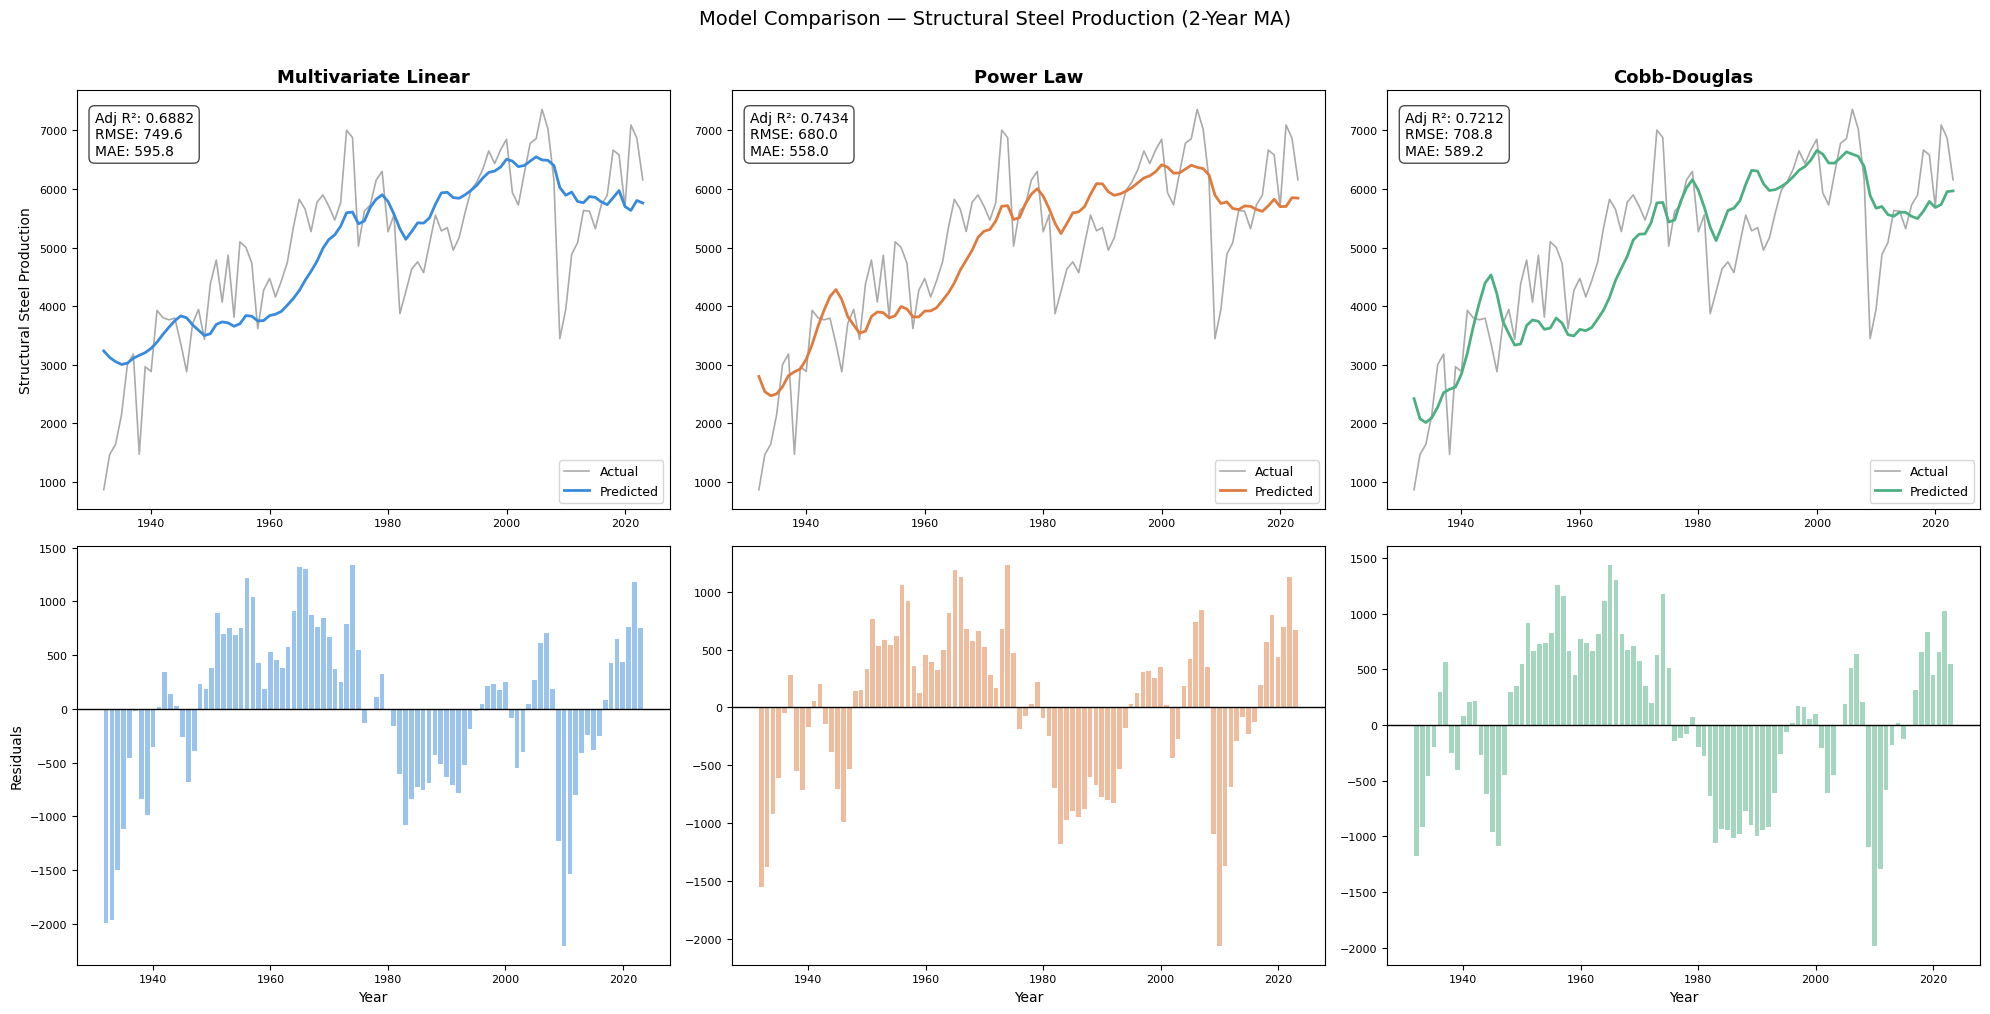

In [131]:
# ── shared data ───────────────────────────────────────────────────────────────
full_vars = ["pop_ssp2", "gdp_ssp2", "energy usage"]
n = len(df_MA_2)
k = 3  # number of predictors

pop    = df_MA_2["pop_ssp2"].values
gdp    = df_MA_2["gdp_ssp2"].values
energy = df_MA_2["energy usage"].values
y      = df_MA_2["structural-total"].values

def adj_r2(r2, n, k):
    return 1 - (1 - r2) * (n - 1) / (n - k - 1)

# ── 1. Multivariate Linear ────────────────────────────────────────────────────
X_fit = df_MA_2[full_vars].values
lin_model = LinearRegression().fit(X_fit, y)
pred_lin  = lin_model.predict(X_fit)

r2_lin   = r2_score(y, pred_lin)
metrics_lin = {
    "Adj R²": adj_r2(r2_lin, n, k),
    "RMSE":   np.sqrt(mean_squared_error(y, pred_lin)),
    "MAE":    mean_absolute_error(y, pred_lin),
}
resid_lin = y - pred_lin

# ── 2. Power Law ──────────────────────────────────────────────────────────────
def power_model(X, a, b, c, d, e, f):
    pop, gdp, energy = X
    return a * np.power(pop, b) * c * np.power(gdp, d) * e * np.power(energy, f)

popt, _ = curve_fit(power_model, (pop, gdp, energy), y, p0=[1,1,1,1,1,1], maxfev=50000)
pred_pow = power_model((pop, gdp, energy), *popt)

r2_pow   = r2_score(y, pred_pow)
metrics_pow = {
    "Adj R²": adj_r2(r2_pow, n, k),
    "RMSE":   np.sqrt(mean_squared_error(y, pred_pow)),
    "MAE":    mean_absolute_error(y, pred_pow),
}
resid_pow = y - pred_pow

# ── 3. Cobb-Douglas ───────────────────────────────────────────────────────────
log_X = np.column_stack([np.ones(n), np.log(pop), np.log(gdp), np.log(energy)])
coeffs, _, _, _ = np.linalg.lstsq(log_X, np.log(y), rcond=None)
log_A, b_cd, d_cd, f_cd = coeffs
A_cd = np.exp(log_A)
pred_cd = A_cd * np.power(pop, b_cd) * np.power(gdp, d_cd) * np.power(energy, f_cd)

r2_cd   = r2_score(y, pred_cd)
metrics_cd = {
    "Adj R²": adj_r2(r2_cd, n, k),
    "RMSE":   np.sqrt(mean_squared_error(y, pred_cd)),
    "MAE":    mean_absolute_error(y, pred_cd),
}
resid_cd = y - pred_cd

# ── plot ──────────────────────────────────────────────────────────────────────
models = [
    ("Multivariate Linear", pred_lin, resid_lin, metrics_lin, "#378ADD"),
    ("Power Law",           pred_pow, resid_pow, metrics_pow, "#E07B3F"),
    ("Cobb-Douglas",        pred_cd,  resid_cd,  metrics_cd,  "#4CAF82"),
]

fig, axes = plt.subplots(2, 3, figsize=(20, 10))
idx = df_MA_2.index

for col, (title, pred, resid, metrics, color) in enumerate(models):

    # ── top row: actual vs predicted ─────────────────────────────────────────
    ax = axes[0, col]
    ax.plot(idx, df_steel["structural-total"].iloc[1:],    color="#AAAAAA", linewidth=1.2, label="Actual")
    ax.plot(idx, pred, color=color,     linewidth=2,   label="Predicted")
    ax.set_title(title, fontsize=13, fontweight="bold")
    ax.set_ylabel("Structural Steel Production" if col == 0 else "")
    ax.legend(fontsize=9)

    metric_text = "\n".join(f"{k}: {v:,.1f}" if k != "Adj R²"
                            else f"{k}: {v:.4f}"
                            for k, v in metrics.items())
    ax.text(0.03, 0.95, metric_text, transform=ax.transAxes,
            fontsize=10, verticalalignment="top",
            bbox=dict(boxstyle="round,pad=0.4", facecolor="white", alpha=0.7))
    ax.tick_params(labelsize=8)

    # ── bottom row: residuals ─────────────────────────────────────────────────
    ax = axes[1, col]
    ax.bar(idx, resid, color=color, alpha=0.5, width=0.8)
    ax.axhline(0, color="black", linewidth=1)
    ax.set_xlabel("Year")
    ax.set_ylabel("Residuals" if col == 0 else "")
    ax.tick_params(labelsize=8)

plt.suptitle("Model Comparison — Structural Steel Production (2-Year MA)",
             fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

## 5 Year Model Comp

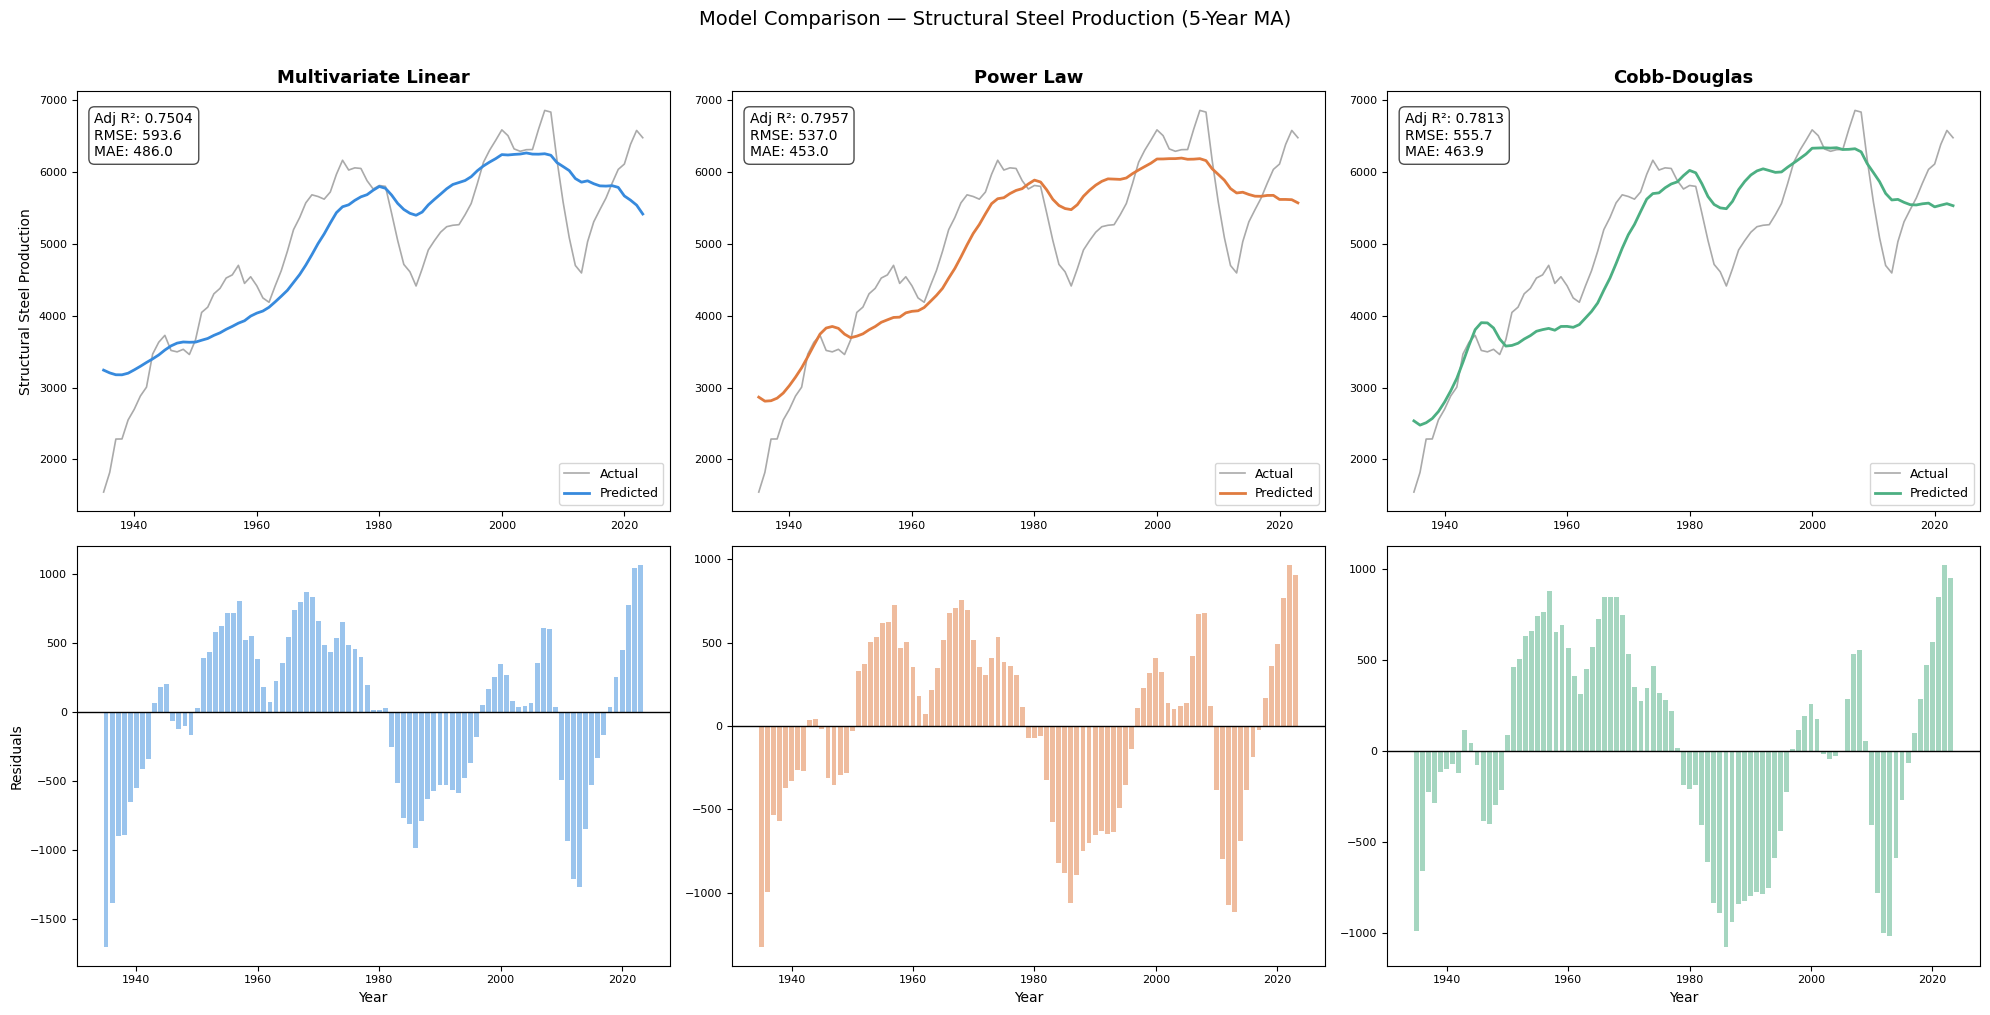

In [132]:
# ── shared data ───────────────────────────────────────────────────────────────
full_vars = ["pop_ssp2", "gdp_ssp2", "energy usage"]
n = len(df_MA_5)
k = 3  # number of predictors

pop    = df_MA_5["pop_ssp2"].values
gdp    = df_MA_5["gdp_ssp2"].values
energy = df_MA_5["energy usage"].values
y      = df_MA_5["structural-total"].values

def adj_r2(r2, n, k):
    return 1 - (1 - r2) * (n - 1) / (n - k - 1)

# ── 1. Multivariate Linear ────────────────────────────────────────────────────
X_fit = df_MA_5[full_vars].values
lin_model = LinearRegression().fit(X_fit, y)
pred_lin  = lin_model.predict(X_fit)

r2_lin   = r2_score(y, pred_lin)
metrics_lin = {
    "Adj R²": adj_r2(r2_lin, n, k),
    "RMSE":   np.sqrt(mean_squared_error(y, pred_lin)),
    "MAE":    mean_absolute_error(y, pred_lin),
}
resid_lin = y - pred_lin

# ── 2. Power Law ──────────────────────────────────────────────────────────────
def power_model(X, a, b, c, d, e, f):
    pop, gdp, energy = X
    return a * np.power(pop, b) * c * np.power(gdp, d) * e * np.power(energy, f)

popt, _ = curve_fit(power_model, (pop, gdp, energy), y, p0=[1,1,1,1,1,1], maxfev=50000)
pred_pow = power_model((pop, gdp, energy), *popt)

r2_pow   = r2_score(y, pred_pow)
metrics_pow = {
    "Adj R²": adj_r2(r2_pow, n, k),
    "RMSE":   np.sqrt(mean_squared_error(y, pred_pow)),
    "MAE":    mean_absolute_error(y, pred_pow),
}
resid_pow = y - pred_pow

# ── 3. Cobb-Douglas ───────────────────────────────────────────────────────────
log_X = np.column_stack([np.ones(n), np.log(pop), np.log(gdp), np.log(energy)])
coeffs, _, _, _ = np.linalg.lstsq(log_X, np.log(y), rcond=None)
log_A, b_cd, d_cd, f_cd = coeffs
A_cd = np.exp(log_A)
pred_cd = A_cd * np.power(pop, b_cd) * np.power(gdp, d_cd) * np.power(energy, f_cd)

r2_cd   = r2_score(y, pred_cd)
metrics_cd = {
    "Adj R²": adj_r2(r2_cd, n, k),
    "RMSE":   np.sqrt(mean_squared_error(y, pred_cd)),
    "MAE":    mean_absolute_error(y, pred_cd),
}
resid_cd = y - pred_cd

# ── plot ──────────────────────────────────────────────────────────────────────
models = [
    ("Multivariate Linear", pred_lin, resid_lin, metrics_lin, "#378ADD"),
    ("Power Law",           pred_pow, resid_pow, metrics_pow, "#E07B3F"),
    ("Cobb-Douglas",        pred_cd,  resid_cd,  metrics_cd,  "#4CAF82"),
]

fig, axes = plt.subplots(2, 3, figsize=(20, 10))
idx = df_MA_5.index

for col, (title, pred, resid, metrics, color) in enumerate(models):

    # ── top row: actual vs predicted ─────────────────────────────────────────
    ax = axes[0, col]
    ax.plot(idx, y,    color="#AAAAAA", linewidth=1.2, label="Actual")
    ax.plot(idx, pred, color=color,     linewidth=2,   label="Predicted")
    ax.set_title(title, fontsize=13, fontweight="bold")
    ax.set_ylabel("Structural Steel Production" if col == 0 else "")
    ax.legend(fontsize=9)

    metric_text = "\n".join(f"{k}: {v:,.1f}" if k != "Adj R²"
                            else f"{k}: {v:.4f}"
                            for k, v in metrics.items())
    ax.text(0.03, 0.95, metric_text, transform=ax.transAxes,
            fontsize=10, verticalalignment="top",
            bbox=dict(boxstyle="round,pad=0.4", facecolor="white", alpha=0.7))
    ax.tick_params(labelsize=8)

    # ── bottom row: residuals ─────────────────────────────────────────────────
    ax = axes[1, col]
    ax.bar(idx, resid, color=color, alpha=0.5, width=0.8)
    ax.axhline(0, color="black", linewidth=1)
    ax.set_xlabel("Year")
    ax.set_ylabel("Residuals" if col == 0 else "")
    ax.tick_params(labelsize=8)

plt.suptitle("Model Comparison — Structural Steel Production (5-Year MA)",
             fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

## 10 Year Model Comp

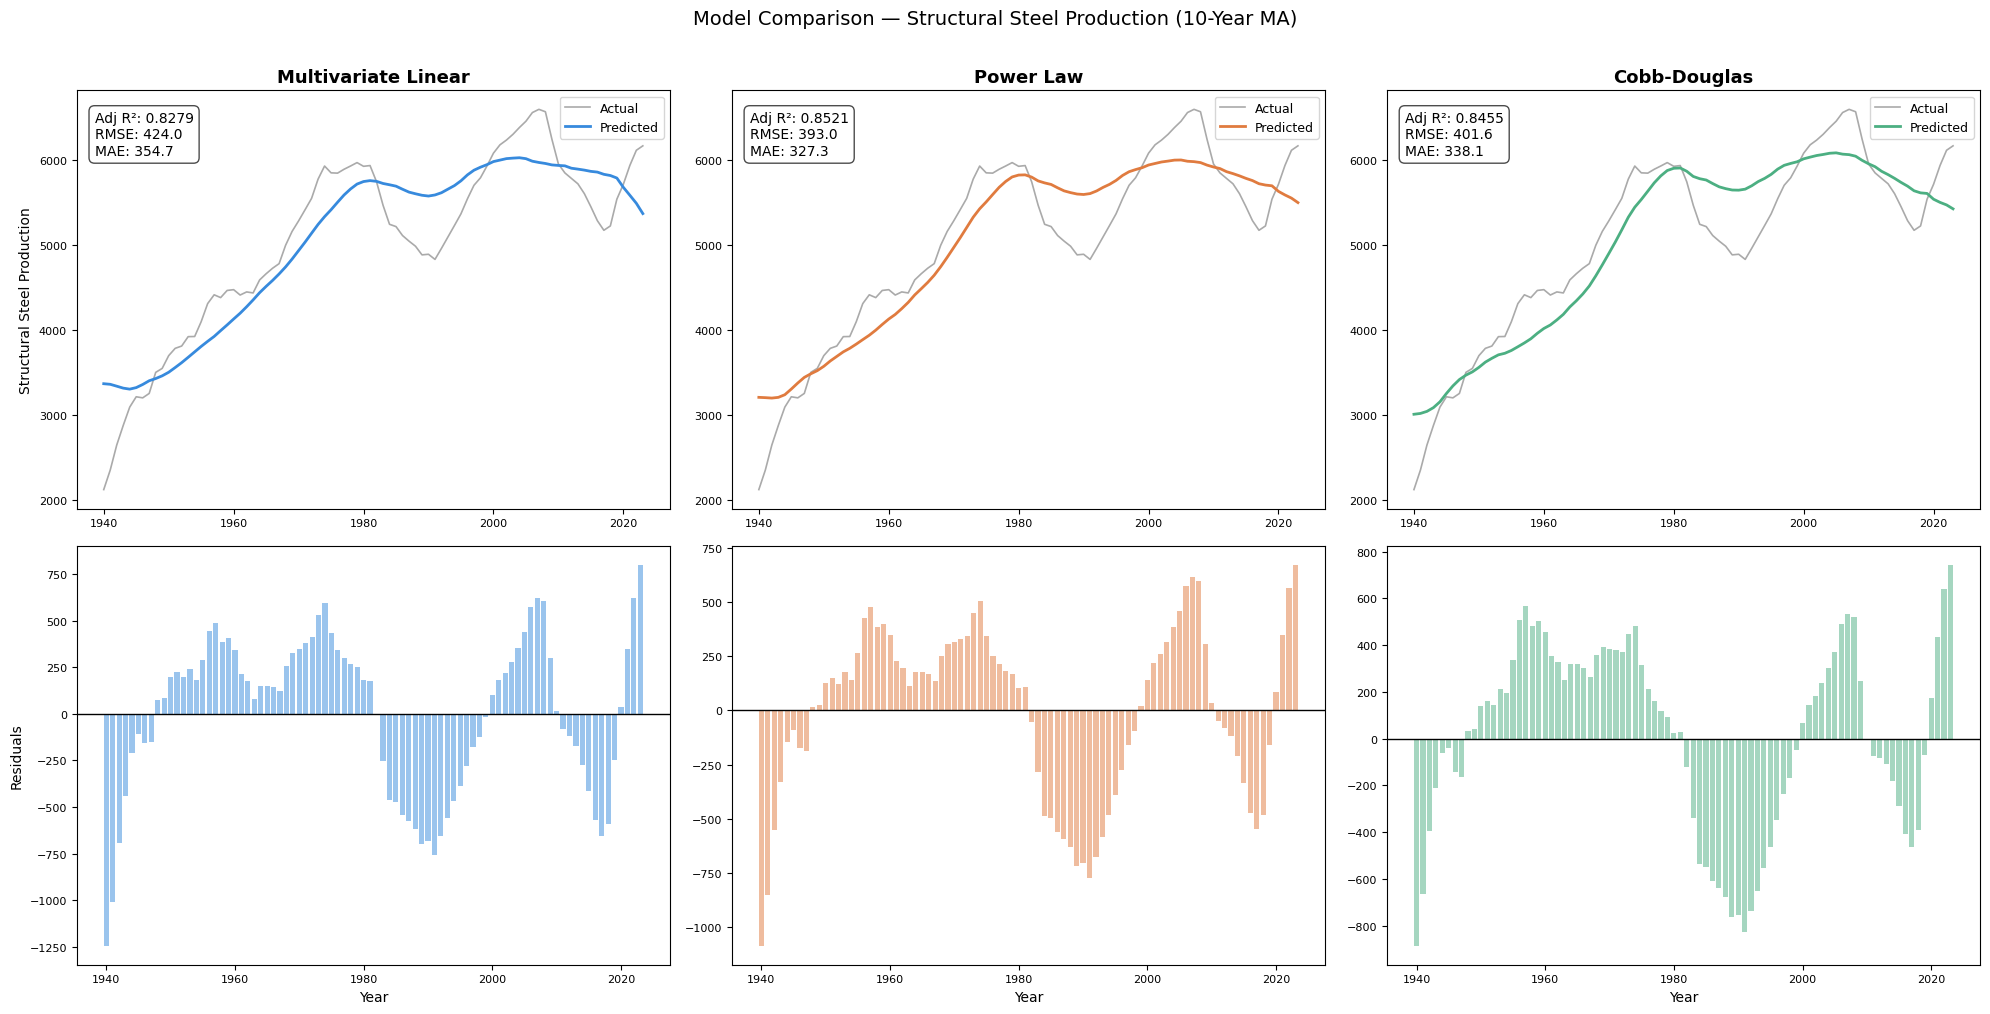

In [133]:
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from scipy.optimize import curve_fit
from sklearn.linear_model import LinearRegression
import numpy as np
import matplotlib.pyplot as plt

# ── shared data ───────────────────────────────────────────────────────────────
full_vars = ["pop_ssp2", "gdp_ssp2", "energy usage"]
n = len(df_MA_10)
k = 3  # number of predictors

pop    = df_MA_10["pop_ssp2"].values
gdp    = df_MA_10["gdp_ssp2"].values
energy = df_MA_10["energy usage"].values
y      = df_MA_10["structural-total"].values

def adj_r2(r2, n, k):
    return 1 - (1 - r2) * (n - 1) / (n - k - 1)

# ── 1. Multivariate Linear ────────────────────────────────────────────────────
X_fit = df_MA_10[full_vars].values
lin_model = LinearRegression().fit(X_fit, y)
pred_lin  = lin_model.predict(X_fit)

r2_lin   = r2_score(y, pred_lin)
metrics_lin = {
    "Adj R²": adj_r2(r2_lin, n, k),
    "RMSE":   np.sqrt(mean_squared_error(y, pred_lin)),
    "MAE":    mean_absolute_error(y, pred_lin),
}
resid_lin = y - pred_lin

# ── 2. Power Law ──────────────────────────────────────────────────────────────
def power_model(X, a, b, c, d, e, f):
    pop, gdp, energy = X
    return a * np.power(pop, b) * c * np.power(gdp, d) * e * np.power(energy, f)

popt, _ = curve_fit(power_model, (pop, gdp, energy), y, p0=[1,1,1,1,1,1], maxfev=50000)
pred_pow = power_model((pop, gdp, energy), *popt)

r2_pow   = r2_score(y, pred_pow)
metrics_pow = {
    "Adj R²": adj_r2(r2_pow, n, k),
    "RMSE":   np.sqrt(mean_squared_error(y, pred_pow)),
    "MAE":    mean_absolute_error(y, pred_pow),
}
resid_pow = y - pred_pow

# ── 3. Cobb-Douglas ───────────────────────────────────────────────────────────
log_X = np.column_stack([np.ones(n), np.log(pop), np.log(gdp), np.log(energy)])
coeffs, _, _, _ = np.linalg.lstsq(log_X, np.log(y), rcond=None)
log_A, b_cd, d_cd, f_cd = coeffs
A_cd = np.exp(log_A)
pred_cd = A_cd * np.power(pop, b_cd) * np.power(gdp, d_cd) * np.power(energy, f_cd)

r2_cd   = r2_score(y, pred_cd)
metrics_cd = {
    "Adj R²": adj_r2(r2_cd, n, k),
    "RMSE":   np.sqrt(mean_squared_error(y, pred_cd)),
    "MAE":    mean_absolute_error(y, pred_cd),
}
resid_cd = y - pred_cd

# ── plot ──────────────────────────────────────────────────────────────────────
models = [
    ("Multivariate Linear", pred_lin, resid_lin, metrics_lin, "#378ADD"),
    ("Power Law",           pred_pow, resid_pow, metrics_pow, "#E07B3F"),
    ("Cobb-Douglas",        pred_cd,  resid_cd,  metrics_cd,  "#4CAF82"),
]

fig, axes = plt.subplots(2, 3, figsize=(20, 10))
idx = df_MA_10.index

for col, (title, pred, resid, metrics, color) in enumerate(models):

    # ── top row: actual vs predicted ─────────────────────────────────────────
    ax = axes[0, col]
    ax.plot(idx, y,    color="#AAAAAA", linewidth=1.2, label="Actual")
    ax.plot(idx, pred, color=color,     linewidth=2,   label="Predicted")
    ax.set_title(title, fontsize=13, fontweight="bold")
    ax.set_ylabel("Structural Steel Production" if col == 0 else "")
    ax.legend(fontsize=9)

    metric_text = "\n".join(f"{k}: {v:,.1f}" if k != "Adj R²"
                            else f"{k}: {v:.4f}"
                            for k, v in metrics.items())
    ax.text(0.03, 0.95, metric_text, transform=ax.transAxes,
            fontsize=10, verticalalignment="top",
            bbox=dict(boxstyle="round,pad=0.4", facecolor="white", alpha=0.7))
    ax.tick_params(labelsize=8)

    # ── bottom row: residuals ─────────────────────────────────────────────────
    ax = axes[1, col]
    ax.bar(idx, resid, color=color, alpha=0.5, width=0.8)
    ax.axhline(0, color="black", linewidth=1)
    ax.set_xlabel("Year")
    ax.set_ylabel("Residuals" if col == 0 else "")
    ax.tick_params(labelsize=8)

plt.suptitle("Model Comparison — Structural Steel Production (10-Year MA)",
             fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

## No MA Forecast

Performing stepwise search to minimize aic
 ARIMA(0,0,0)(0,0,0)[0]             : AIC=1864.643, Time=0.03 sec
 ARIMA(1,0,0)(0,0,0)[0]             : AIC=1476.556, Time=0.03 sec
 ARIMA(0,0,1)(0,0,0)[0]             : AIC=1499.857, Time=0.04 sec
 ARIMA(2,0,0)(0,0,0)[0]             : AIC=1478.693, Time=0.04 sec
 ARIMA(1,0,1)(0,0,0)[0]             : AIC=1478.680, Time=0.04 sec
 ARIMA(2,0,1)(0,0,0)[0]             : AIC=1578.538, Time=0.13 sec
 ARIMA(1,0,0)(0,0,0)[0] intercept   : AIC=1478.603, Time=0.08 sec

Best model:  ARIMA(1,0,0)(0,0,0)[0]          
Total fit time: 0.386 seconds

ARIMAX selected order: (1, 0, 0)


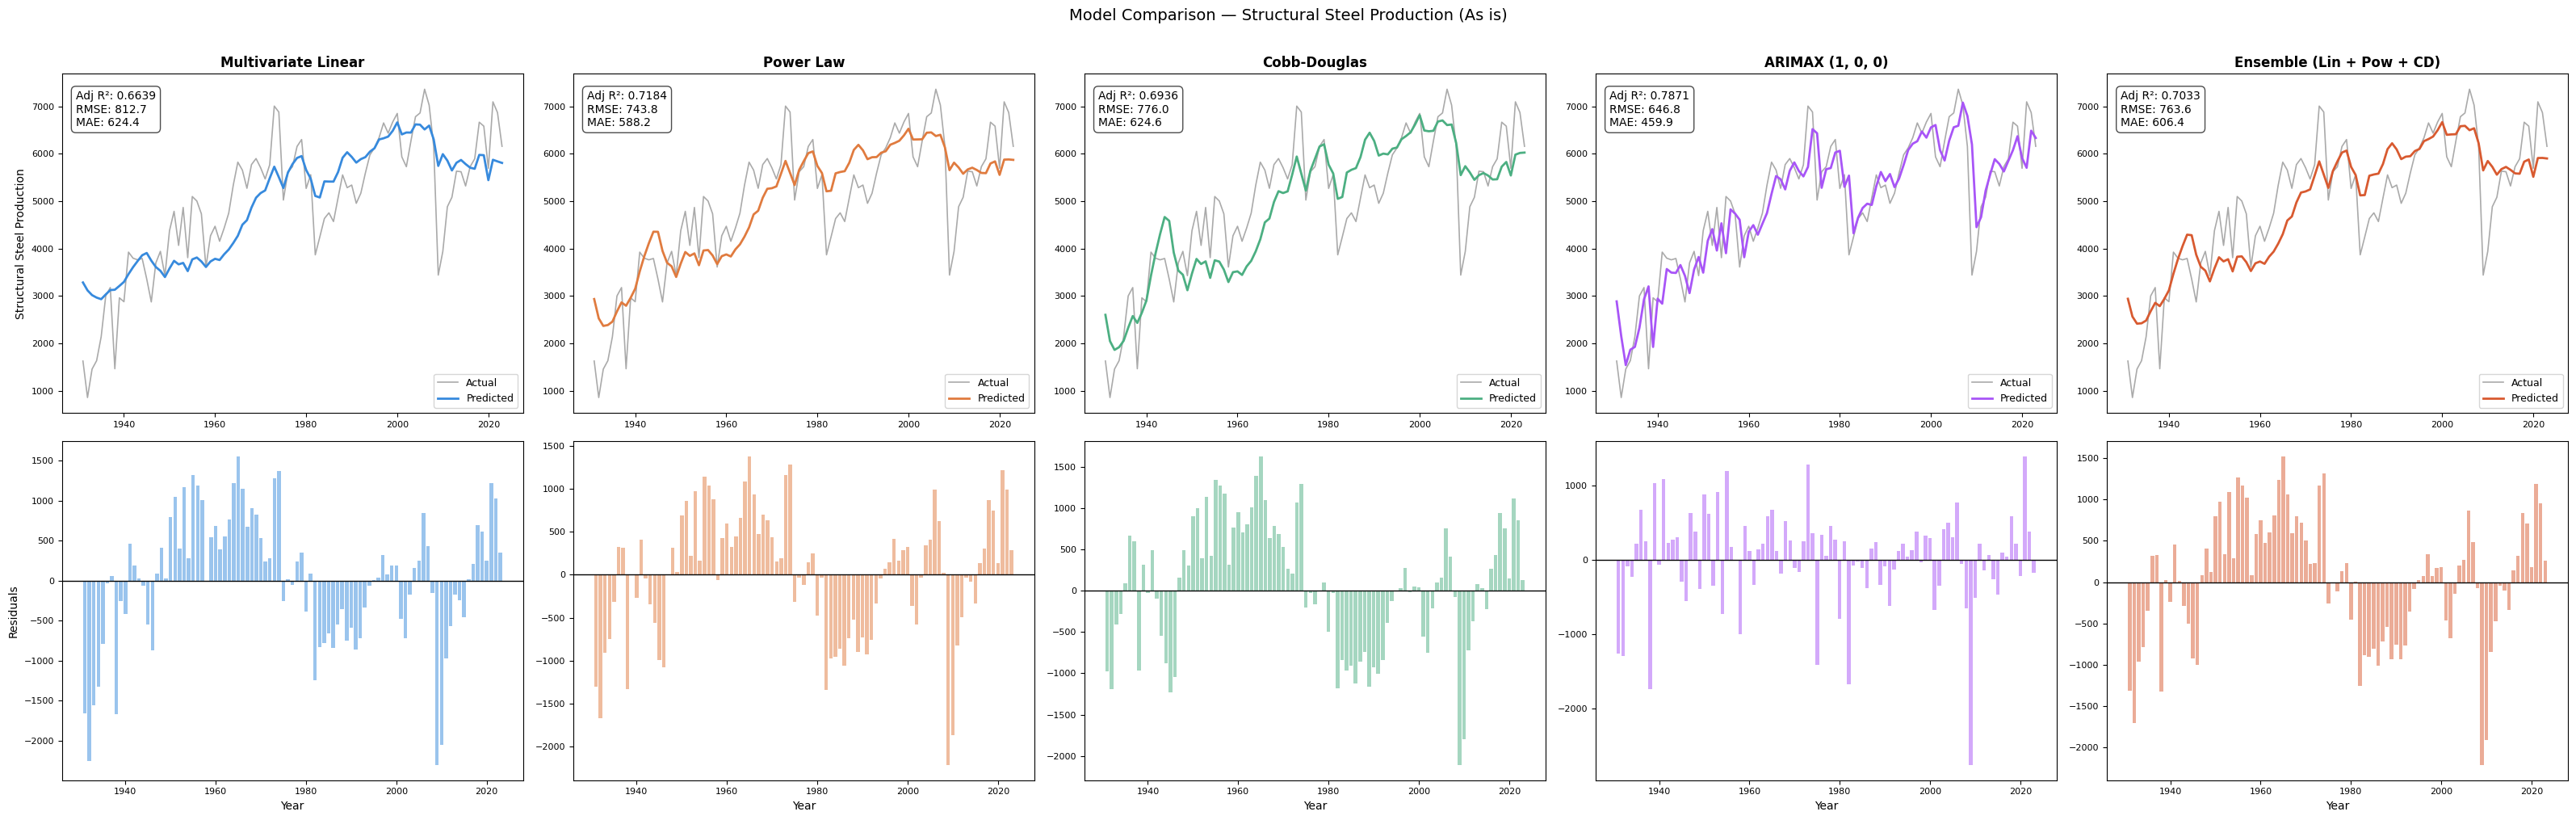

In [165]:
# ── shared data ───────────────────────────────────────────────────────────────
full_vars = ["pop_ssp2", "gdp_ssp2", "energy usage"]
n = len(df_elasticities)
k = 3

pop    = df_elasticities["pop_ssp2"].values
gdp    = df_elasticities["gdp_ssp2"].values
energy = df_elasticities["energy usage"].values
y      = df_elasticities["structural-total"].values
exog   = df_elasticities[full_vars].values

def adj_r2(r2, n, k):
    return 1 - (1 - r2) * (n - 1) / (n - k - 1)

# ── 1. Multivariate Linear ────────────────────────────────────────────────────
lin_model = LinearRegression().fit(exog, y)
pred_lin  = lin_model.predict(exog)
r2_lin    = r2_score(y, pred_lin)
metrics_lin = {
    "Adj R²": adj_r2(r2_lin, n, k),
    "RMSE":   np.sqrt(mean_squared_error(y, pred_lin)),
    "MAE":    mean_absolute_error(y, pred_lin),
}
resid_lin = y - pred_lin

# ── 2. Power Law ──────────────────────────────────────────────────────────────
def power_model(X, a, b, c, d, e, f):
    pop, gdp, energy = X
    return a * np.power(pop, b) * c * np.power(gdp, d) * e * np.power(energy, f)

popt, _ = curve_fit(power_model, (pop, gdp, energy), y, p0=[1,1,1,1,1,1], maxfev=50000)
pred_pow = power_model((pop, gdp, energy), *popt)
r2_pow   = r2_score(y, pred_pow)
metrics_pow = {
    "Adj R²": adj_r2(r2_pow, n, k),
    "RMSE":   np.sqrt(mean_squared_error(y, pred_pow)),
    "MAE":    mean_absolute_error(y, pred_pow),
}
resid_pow = y - pred_pow

# ── 3. Cobb-Douglas ───────────────────────────────────────────────────────────
log_X = np.column_stack([np.ones(n), np.log(pop), np.log(gdp), np.log(energy)])
coeffs, _, _, _ = np.linalg.lstsq(log_X, np.log(y), rcond=None)
log_A, b_cd, d_cd, f_cd = coeffs
A_cd    = np.exp(log_A)
pred_cd = A_cd * np.power(pop, b_cd) * np.power(gdp, d_cd) * np.power(energy, f_cd)
r2_cd   = r2_score(y, pred_cd)
metrics_cd = {
    "Adj R²": adj_r2(r2_cd, n, k),
    "RMSE":   np.sqrt(mean_squared_error(y, pred_cd)),
    "MAE":    mean_absolute_error(y, pred_cd),
}
resid_cd = y - pred_cd

# ── 4. ARIMAX (auto-selected order) ──────────────────────────────────────────
arimax_model = pm.auto_arima(
    y,
    X=exog,
    start_p=0, max_p=3,
    start_q=0, max_q=3,
    d=None,                     # force no differencing — let exog carry the trend
    seasonal=False,
    information_criterion="aic",
    stepwise=True,
    error_action="ignore",
    suppress_warnings=True,
    trace=True
)

print(f"\nARIMAX selected order: {arimax_model.order}")
pred_arimax = arimax_model.predict_in_sample(X=exog)
r2_arimax   = r2_score(y, pred_arimax)
metrics_arimax = {
    "Adj R²": adj_r2(r2_arimax, n, k),
    "RMSE":   np.sqrt(mean_squared_error(y, pred_arimax)),
    "MAE":    mean_absolute_error(y, pred_arimax),
}
resid_arimax = y - pred_arimax

# ── 5. Ensemble (Lin + Pow + CD) ─────────────────────────────────────────────
pred_ensemble = np.mean([pred_lin, pred_pow, pred_cd], axis=0)
r2_ensemble   = r2_score(y, pred_ensemble)
metrics_ensemble = {
    "Adj R²": adj_r2(r2_ensemble, n, k),
    "RMSE":   np.sqrt(mean_squared_error(y, pred_ensemble)),
    "MAE":    mean_absolute_error(y, pred_ensemble),
}
resid_ensemble = y - pred_ensemble

# ── plot (2 rows × 4 cols) ────────────────────────────────────────────────────
models = [
    ("Multivariate Linear",              pred_lin,    resid_lin,    metrics_lin,    "#378ADD"),
    ("Power Law",                         pred_pow,    resid_pow,    metrics_pow,    "#E07B3F"),
    ("Cobb-Douglas",                      pred_cd,     resid_cd,     metrics_cd,     "#4CAF82"),
    (f"ARIMAX {arimax_model.order}",      pred_arimax, resid_arimax, metrics_arimax, "#A855F7"),
    ("Ensemble (Lin + Pow + CD)",         pred_ensemble, resid_ensemble, metrics_ensemble, "#D85A30"),
]

fig, axes = plt.subplots(2, 5, figsize=(32, 10))
idx = df_elasticities.index

for col, (title, pred, resid, metrics, color) in enumerate(models):

    # ── top row: actual vs predicted ─────────────────────────────────────────
    ax = axes[0, col]
    ax.plot(idx, y,    color="#AAAAAA", linewidth=1.2, label="Actual")
    ax.plot(idx, pred, color=color,     linewidth=2,   label="Predicted")
    ax.set_title(title, fontsize=12, fontweight="bold")
    ax.set_ylabel("Structural Steel Production" if col == 0 else "")
    ax.legend(fontsize=9)

    metric_text = "\n".join(f"{k}: {v:,.1f}" if k != "Adj R²"
                            else f"{k}: {v:.4f}"
                            for k, v in metrics.items())
    ax.text(0.03, 0.95, metric_text, transform=ax.transAxes,
            fontsize=10, verticalalignment="top",
            bbox=dict(boxstyle="round,pad=0.4", facecolor="white", alpha=0.7))
    ax.tick_params(labelsize=8)

    # ── bottom row: residuals ─────────────────────────────────────────────────
    ax = axes[1, col]
    ax.bar(idx, resid, color=color, alpha=0.5, width=0.8)
    ax.axhline(0, color="black", linewidth=1)
    ax.set_xlabel("Year")
    ax.set_ylabel("Residuals" if col == 0 else "")
    ax.tick_params(labelsize=8)

plt.suptitle("Model Comparison — Structural Steel Production (As is)",
             fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

In [135]:
print(f"Population exponent: {b:.3f}")
print(f"GDP exponent:        {d:.3f}")
print(f"Energy exponent:     {f:.3f}")

Population exponent: -0.465
GDP exponent:        -0.153
Energy exponent:     0.911


In [136]:
print(f"Population exponent: {popt[1]:.3f}")
print(f"GDP exponent:        {popt[2]:.3f}")
print(f"Energy exponent:     {popt[3]:.3f}")

Population exponent: -1.623
GDP exponent:        -24312.899
Energy exponent:     0.652


### Forecast

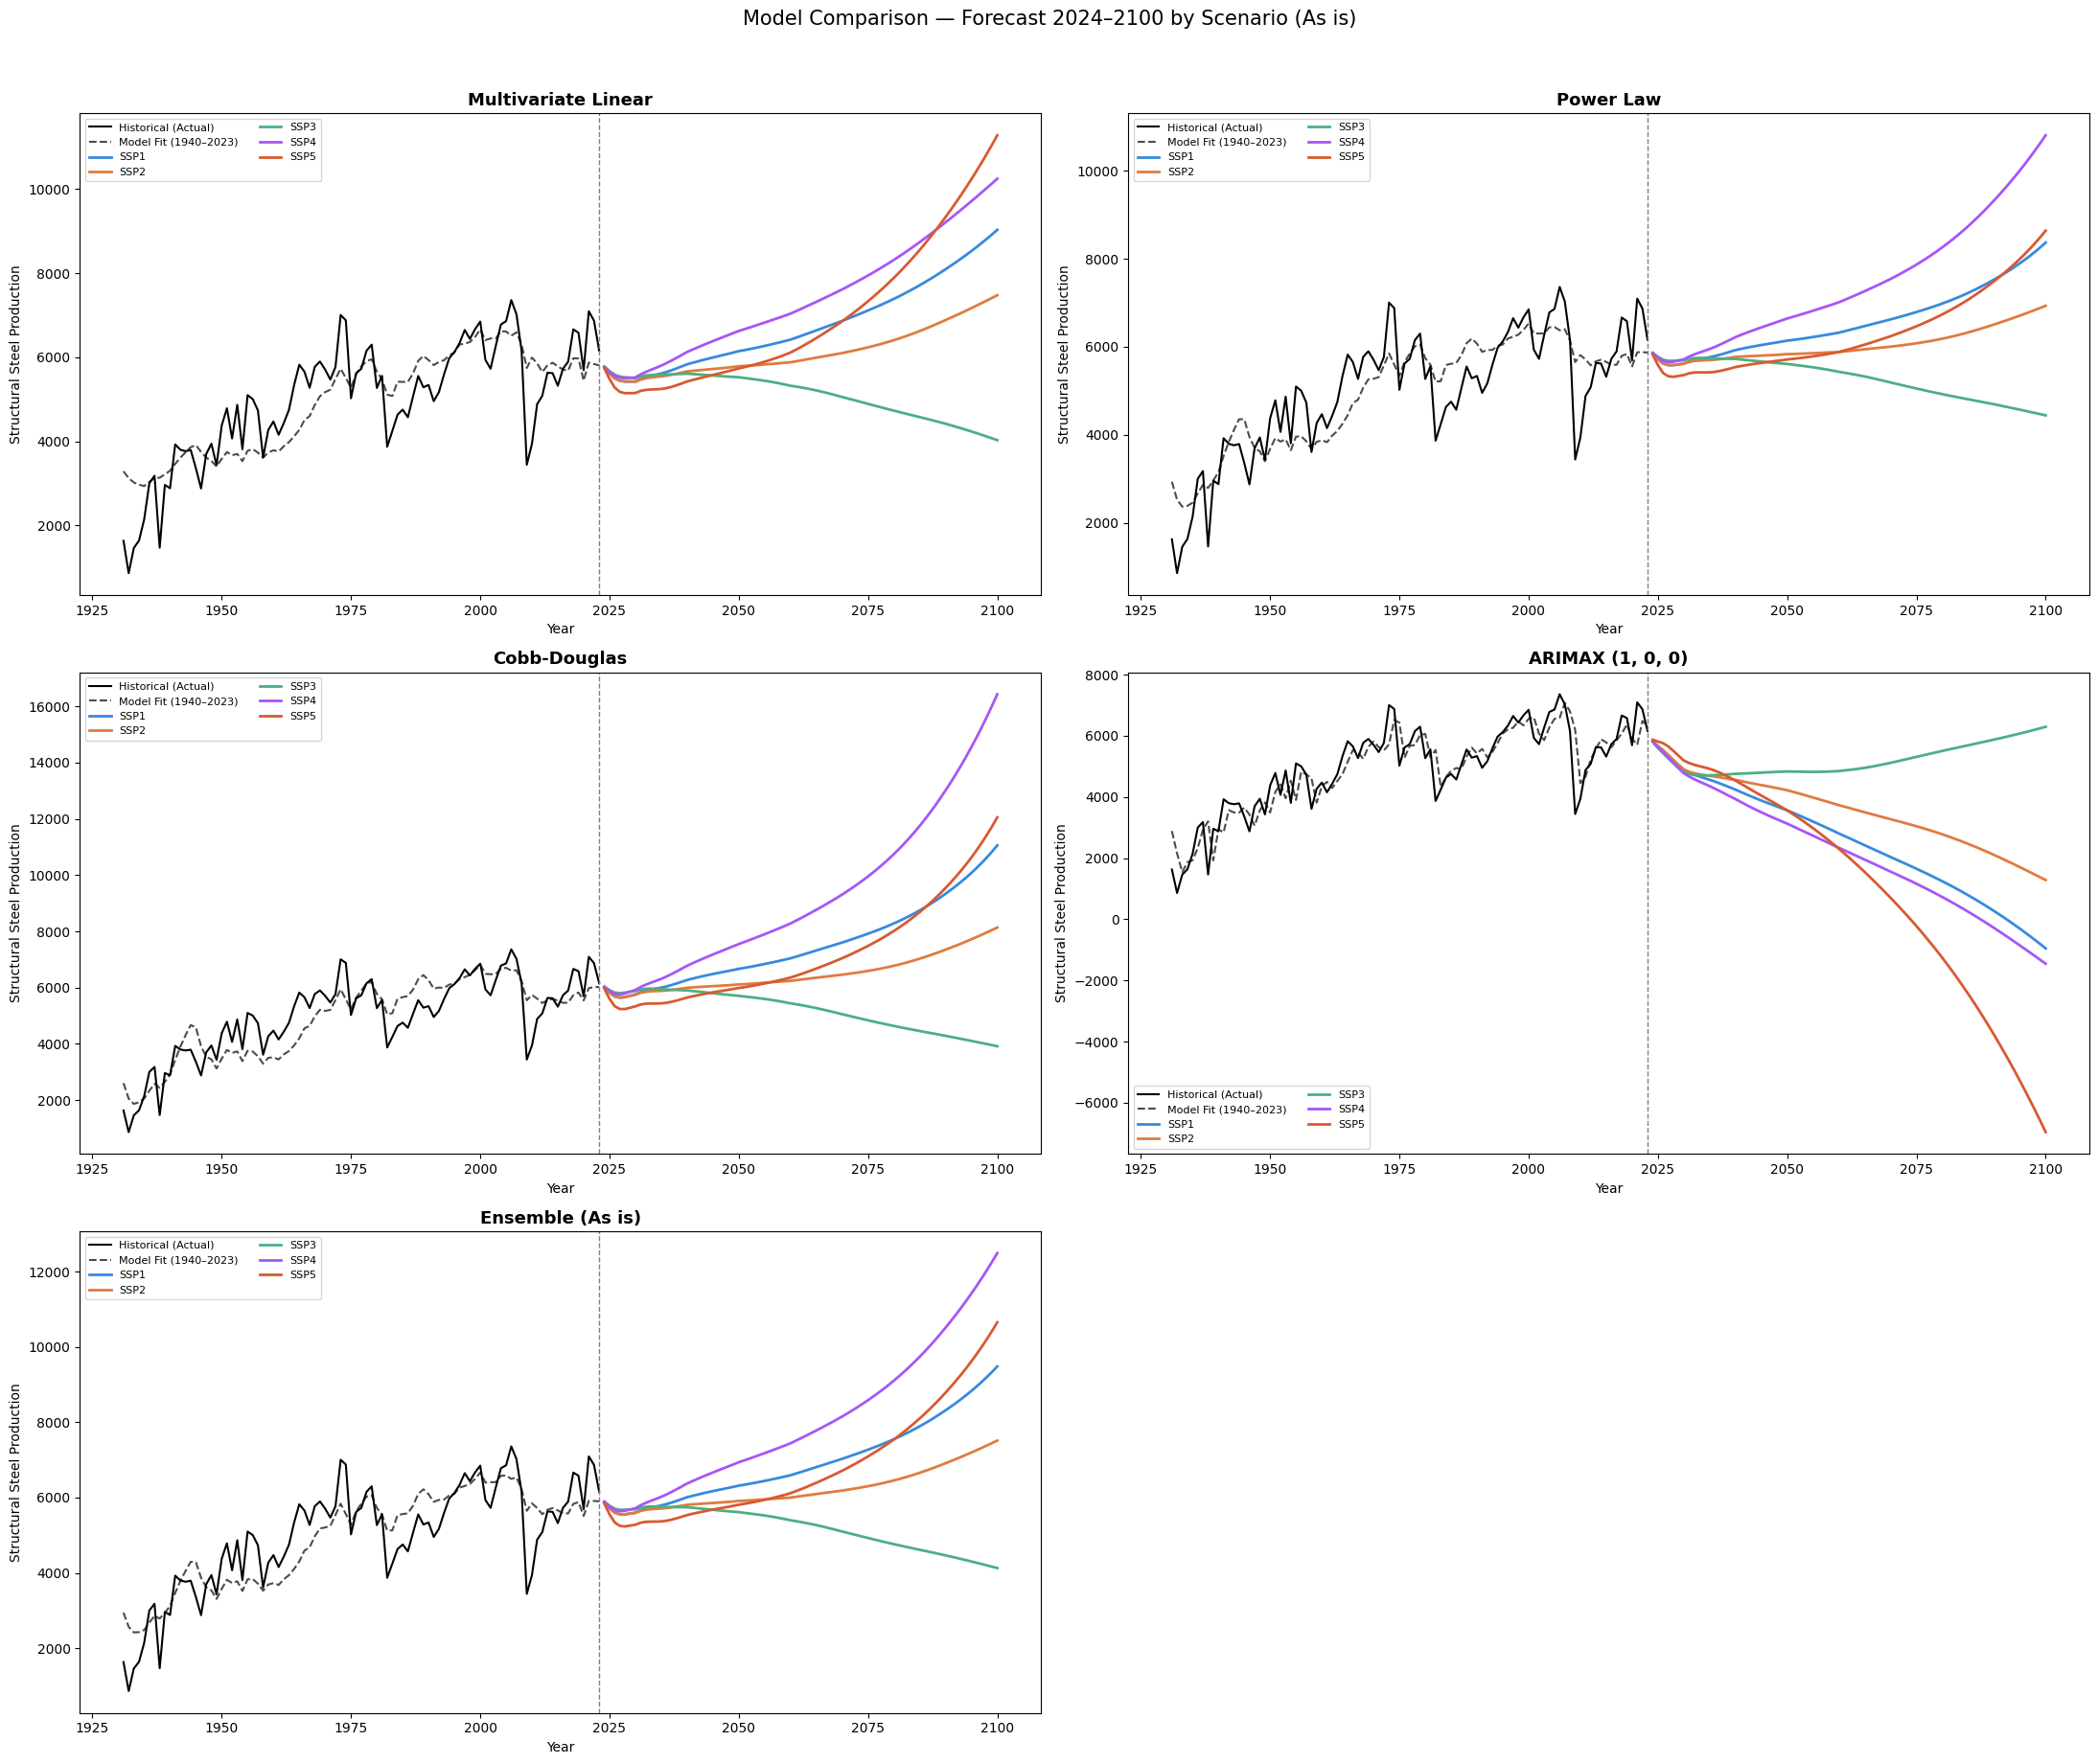

In [137]:
# ── config ────────────────────────────────────────────────────────────────────
scenarios = ["ssp1", "ssp2", "ssp3", "ssp4", "ssp5"]
forecast_years = np.arange(2024, 2101)

energy_forecast = df_energy_use.loc[forecast_years, "energy usage"].values

exog_forecast = {}
for s in scenarios:
    pop_f = df_population.loc[forecast_years, f"pop_{s}"].values
    gdp_f = df_gdp.loc[forecast_years, f"gdp_{s}"].values
    exog_forecast[s] = np.column_stack([pop_f, gdp_f, energy_forecast])

# ── 1. Multivariate Linear — forecast ────────────────────────────────────────
forecast_lin = {s: lin_model.predict(exog_forecast[s]) for s in scenarios}

# ── 2. Power Law — forecast ───────────────────────────────────────────────────
forecast_pow = {}
for s in scenarios:
    pop_f, gdp_f, en_f = exog_forecast[s][:,0], exog_forecast[s][:,1], exog_forecast[s][:,2]
    forecast_pow[s] = power_model((pop_f, gdp_f, en_f), *popt)

# ── 3. Cobb-Douglas — forecast ────────────────────────────────────────────────
forecast_cd = {}
for s in scenarios:
    pop_f, gdp_f, en_f = exog_forecast[s][:,0], exog_forecast[s][:,1], exog_forecast[s][:,2]
    forecast_cd[s] = A_cd * np.power(pop_f, b_cd) * np.power(gdp_f, d_cd) * np.power(en_f, f_cd)

# ── 4. ARIMAX (pm.auto_arima) — forecast ─────────────────────────────────────
n_periods = len(forecast_years)
forecast_arimax = {
    s: arimax_model.predict(n_periods=n_periods, X=exog_forecast[s])
    for s in scenarios
}
# ── 5. Ensemble (mean of Linear, Power Law, Cobb-Douglas) ────────────────────
forecast_ensemble = {
    s: np.mean([forecast_lin[s], forecast_pow[s], forecast_cd[s]], axis=0)
    for s in scenarios
}

# ── in-sample (historical) predictions per model ─────────────────────────────
hist_idx = df_elasticities.index
hist_y   = df_steel["structural-total"].values

insample_lin      = pred_lin
insample_pow      = pred_pow
insample_cd       = pred_cd
insample_arimax   = arimax_model.predict_in_sample(X=exog)
insample_ensemble = np.mean([insample_lin, insample_pow, insample_cd], axis=0)

model_forecasts = {
    "Multivariate Linear":            (forecast_lin,      insample_lin),
    "Power Law":                      (forecast_pow,      insample_pow),
    "Cobb-Douglas":                   (forecast_cd,       insample_cd),
    f"ARIMAX {arimax_model.order}":   (forecast_arimax,   insample_arimax),
    "Ensemble (As is)":      (forecast_ensemble, insample_ensemble),
}

colors = {"ssp1": "#378ADD", "ssp2": "#E07B3F", "ssp3": "#4CAF82",
          "ssp4": "#A855F7", "ssp5": "#D85A30"}

# ── 3x2 grid (5 models) ───────────────────────────────────────────────────────
fig, axes = plt.subplots(3, 2, figsize=(22, 18))
axes = axes.flatten()

for ax, (title, (forecasts, insample_pred)) in zip(axes, model_forecasts.items()):
    ax.plot(hist_idx, hist_y, color="black", linewidth=1.5, label="Historical (Actual)")
    ax.plot(hist_idx, insample_pred, color="black", linestyle="--", linewidth=1.5,
            alpha=0.7, label="Model Fit (1940–2023)")

    for s in scenarios:
        ax.plot(forecast_years, forecasts[s], color=colors[s], linewidth=2, label=s.upper())

    ax.axvline(hist_idx[-1], color="gray", linestyle="--", linewidth=1)
    ax.set_title(title, fontsize=13, fontweight="bold")
    ax.set_xlabel("Year")
    ax.set_ylabel("Structural Steel Production")
    ax.legend(fontsize=8, ncol=2)

# Hide the unused 6th subplot
axes[-1].set_visible(False)

plt.suptitle("Model Comparison — Forecast 2024–2100 by Scenario (As is)", fontsize=15, y=1.02)
plt.tight_layout()
plt.show()

## 2 Year Forecast 

Performing stepwise search to minimize aic
 ARIMA(0,1,0)(0,0,0)[0] intercept   : AIC=1323.694, Time=0.03 sec
 ARIMA(1,1,0)(0,0,0)[0] intercept   : AIC=1307.637, Time=0.04 sec
 ARIMA(0,1,1)(0,0,0)[0] intercept   : AIC=1290.664, Time=0.09 sec
 ARIMA(0,1,0)(0,0,0)[0]             : AIC=1642.187, Time=0.03 sec
 ARIMA(1,1,1)(0,0,0)[0] intercept   : AIC=1290.655, Time=0.10 sec
 ARIMA(2,1,1)(0,0,0)[0] intercept   : AIC=1295.766, Time=0.05 sec
 ARIMA(1,1,2)(0,0,0)[0] intercept   : AIC=1286.743, Time=0.06 sec
 ARIMA(0,1,2)(0,0,0)[0] intercept   : AIC=1283.600, Time=0.05 sec
 ARIMA(0,1,3)(0,0,0)[0] intercept   : AIC=1290.584, Time=0.06 sec
 ARIMA(1,1,3)(0,0,0)[0] intercept   : AIC=1289.167, Time=0.08 sec
 ARIMA(0,1,2)(0,0,0)[0]             : AIC=1281.686, Time=0.05 sec
 ARIMA(0,1,1)(0,0,0)[0]             : AIC=1288.791, Time=0.03 sec
 ARIMA(1,1,2)(0,0,0)[0]             : AIC=1284.983, Time=0.05 sec
 ARIMA(0,1,3)(0,0,0)[0]             : AIC=1288.853, Time=0.07 sec
 ARIMA(1,1,1)(0,0,0)[0]          

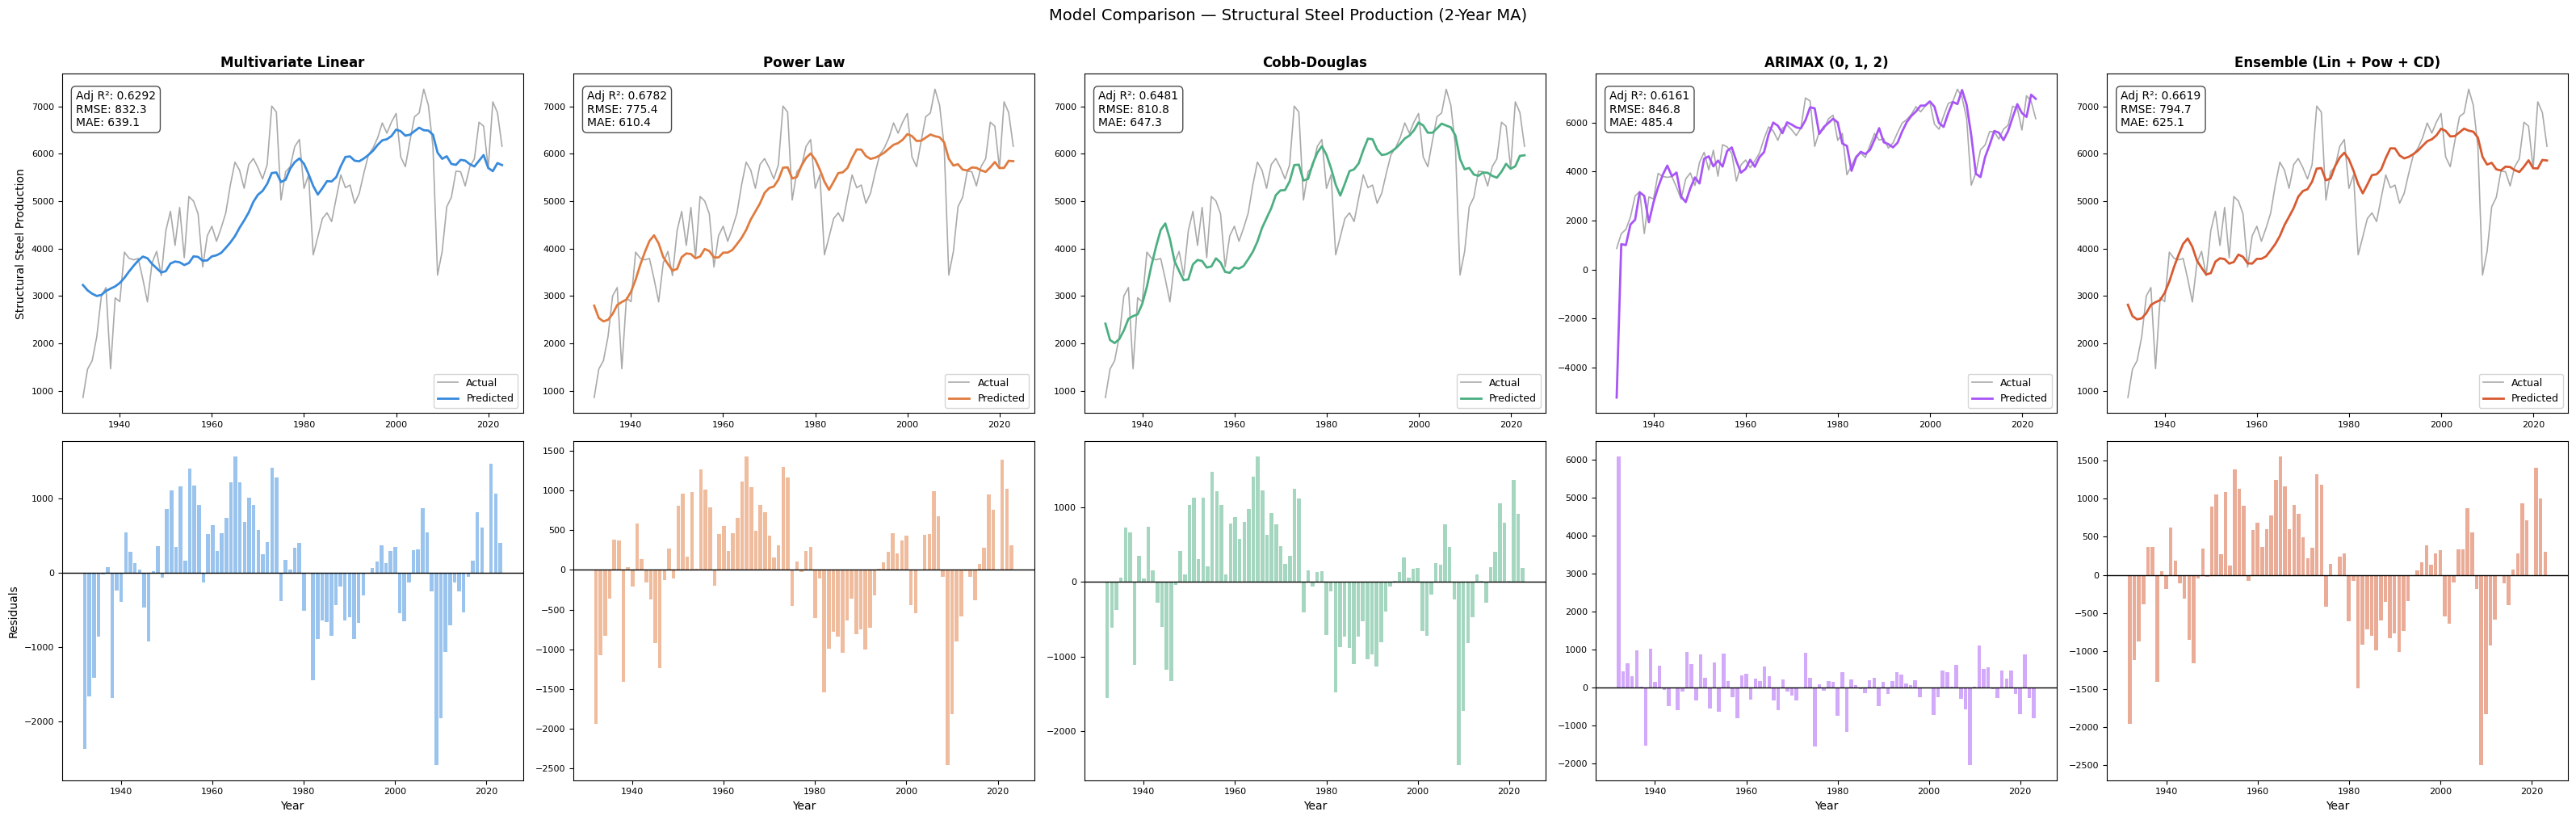

In [138]:

# ── shared data ───────────────────────────────────────────────────────────────
full_vars = ["pop_ssp2", "gdp_ssp2", "energy usage"]
n = len(df_MA_2)
k = 3

pop    = df_MA_2["pop_ssp2"].values
gdp    = df_MA_2["gdp_ssp2"].values
energy = df_MA_2["energy usage"].values
y      = df_MA_2["structural-total"].values
exog   = df_MA_2[full_vars].values

y_actual = df_steel["structural-total"].iloc[1:]

def adj_r2(r2, n, k):
    return 1 - (1 - r2) * (n - 1) / (n - k - 1)

# ── 1. Multivariate Linear ────────────────────────────────────────────────────
lin_model = LinearRegression().fit(exog, y)
pred_lin  = lin_model.predict(exog)
r2_lin    = r2_score(y_actual, pred_lin)
metrics_lin = {
    "Adj R²": adj_r2(r2_lin, n, k),
    "RMSE":   np.sqrt(mean_squared_error(y_actual, pred_lin)),
    "MAE":    mean_absolute_error(y_actual, pred_lin),
}
resid_lin = y_actual - pred_lin

# ── 2. Power Law ──────────────────────────────────────────────────────────────
def power_model(X, a, b, c, d, e, f):
    pop, gdp, energy = X
    return a * np.power(pop, b) * c * np.power(gdp, d) * e * np.power(energy, f)

popt, _ = curve_fit(power_model, (pop, gdp, energy), y, p0=[1,1,1,1,1,1], maxfev=50000)
pred_pow = power_model((pop, gdp, energy), *popt)
r2_pow   = r2_score(y_actual, pred_pow)
metrics_pow = {
    "Adj R²": adj_r2(r2_pow, n, k),
    "RMSE":   np.sqrt(mean_squared_error(y_actual, pred_pow)),
    "MAE":    mean_absolute_error(y_actual, pred_pow),
}
resid_pow = y_actual - pred_pow

# ── 3. Cobb-Douglas ───────────────────────────────────────────────────────────
log_X = np.column_stack([np.ones(n), np.log(pop), np.log(gdp), np.log(energy)])
coeffs, _, _, _ = np.linalg.lstsq(log_X, np.log(y), rcond=None)
log_A, b_cd, d_cd, f_cd = coeffs
A_cd    = np.exp(log_A)
pred_cd = A_cd * np.power(pop, b_cd) * np.power(gdp, d_cd) * np.power(energy, f_cd)
r2_cd   = r2_score(y_actual, pred_cd)
metrics_cd = {
    "Adj R²": adj_r2(r2_cd, n, k),
    "RMSE":   np.sqrt(mean_squared_error(y_actual, pred_cd)),
    "MAE":    mean_absolute_error(y_actual, pred_cd),
}
resid_cd = y_actual - pred_cd

# ── 4. ARIMAX (auto-selected order) ──────────────────────────────────────────
arimax_model = pm.auto_arima(
    y,
    X=exog,
    start_p=0, max_p=3,
    start_q=0, max_q=3,
    d=1,                     # force no differencing — let exog carry the trend
    seasonal=False,
    information_criterion="aic",
    stepwise=True,
    error_action="ignore",
    suppress_warnings=True,
    trace=True
)

print(f"\nARIMAX selected order: {arimax_model.order}")
pred_arimax = arimax_model.predict_in_sample(X=exog)
r2_arimax   = r2_score(y_actual, pred_arimax)
metrics_arimax = {
    "Adj R²": adj_r2(r2_arimax, n, k),
    "RMSE":   np.sqrt(mean_squared_error(y_actual, pred_arimax)),
    "MAE":    mean_absolute_error(y_actual, pred_arimax),
}
resid_arimax = y_actual - pred_arimax

# ── 5. Ensemble (Lin + Pow + CD) ─────────────────────────────────────────────
pred_ensemble = np.mean([pred_lin, pred_pow, pred_cd], axis=0)
r2_ensemble   = r2_score(y_actual, pred_ensemble)
metrics_ensemble = {
    "Adj R²": adj_r2(r2_ensemble, n, k),
    "RMSE":   np.sqrt(mean_squared_error(y_actual, pred_ensemble)),
    "MAE":    mean_absolute_error(y_actual, pred_ensemble),
}
resid_ensemble = y_actual - pred_ensemble

# ── plot (2 rows × 4 cols) ────────────────────────────────────────────────────
models = [
    ("Multivariate Linear",              pred_lin,    resid_lin,    metrics_lin,    "#378ADD"),
    ("Power Law",                         pred_pow,    resid_pow,    metrics_pow,    "#E07B3F"),
    ("Cobb-Douglas",                      pred_cd,     resid_cd,     metrics_cd,     "#4CAF82"),
    (f"ARIMAX {arimax_model.order}",      pred_arimax, resid_arimax, metrics_arimax, "#A855F7"),
    ("Ensemble (Lin + Pow + CD)",         pred_ensemble, resid_ensemble, metrics_ensemble, "#D85A30"),
]

fig, axes = plt.subplots(2, 5, figsize=(32, 10))
idx = df_MA_2.index

for col, (title, pred, resid, metrics, color) in enumerate(models):

    # ── top row: actual vs predicted ─────────────────────────────────────────
    ax = axes[0, col]
    ax.plot(idx, y_actual,    color="#AAAAAA", linewidth=1.2, label="Actual")
    ax.plot(idx, pred, color=color,     linewidth=2,   label="Predicted")
    ax.set_title(title, fontsize=12, fontweight="bold")
    ax.set_ylabel("Structural Steel Production" if col == 0 else "")
    ax.legend(fontsize=9)

    metric_text = "\n".join(f"{k}: {v:,.1f}" if k != "Adj R²"
                            else f"{k}: {v:.4f}"
                            for k, v in metrics.items())
    ax.text(0.03, 0.95, metric_text, transform=ax.transAxes,
            fontsize=10, verticalalignment="top",
            bbox=dict(boxstyle="round,pad=0.4", facecolor="white", alpha=0.7))
    ax.tick_params(labelsize=8)

    # ── bottom row: residuals ─────────────────────────────────────────────────
    ax = axes[1, col]
    ax.bar(idx, resid, color=color, alpha=0.5, width=0.8)
    ax.axhline(0, color="black", linewidth=1)
    ax.set_xlabel("Year")
    ax.set_ylabel("Residuals" if col == 0 else "")
    ax.tick_params(labelsize=8)

plt.suptitle("Model Comparison — Structural Steel Production (2-Year MA)",
             fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

In [139]:
print(f"Population exponent: {b:.3f}")
print(f"GDP exponent:        {d:.3f}")
print(f"Energy exponent:     {f:.3f}")

Population exponent: -0.465
GDP exponent:        -0.153
Energy exponent:     0.911


In [140]:
print(f"Population exponent: {popt[1]:.3f}")
print(f"GDP exponent:        {popt[2]:.3f}")
print(f"Energy exponent:     {popt[3]:.3f}")

Population exponent: -1.447
GDP exponent:        11192.466
Energy exponent:     0.562


### Forecasting

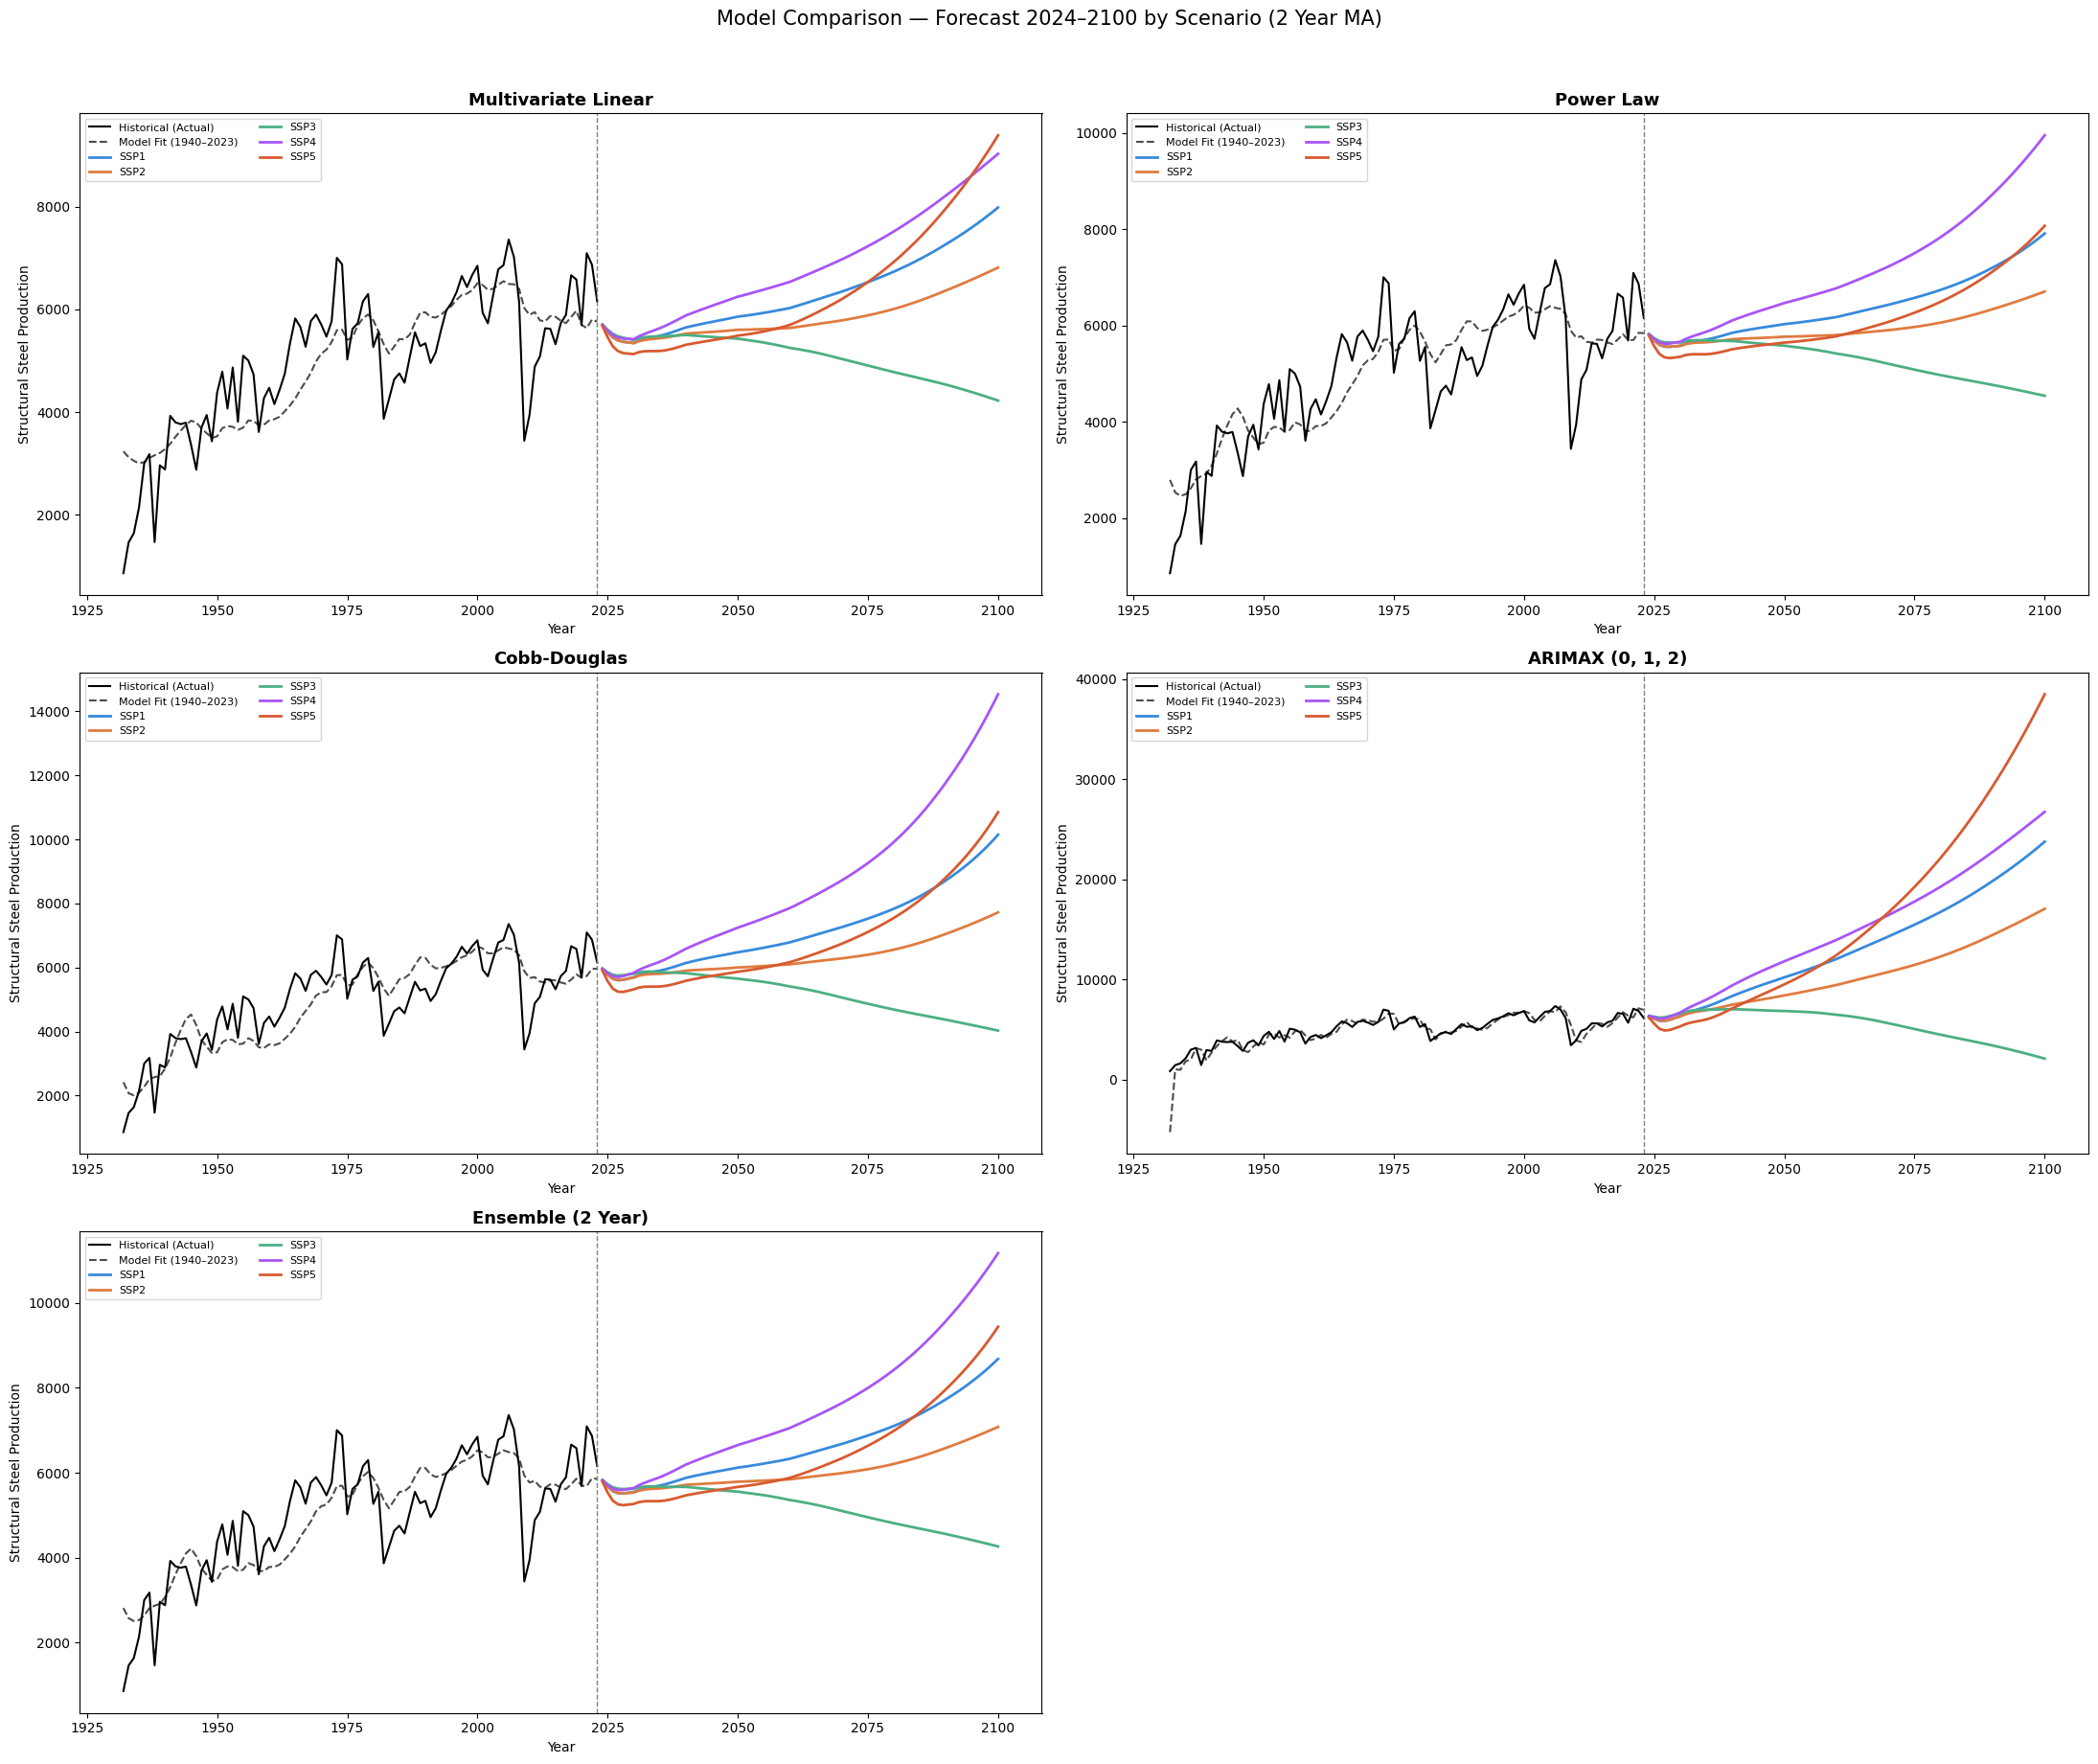

In [141]:
# ── config ────────────────────────────────────────────────────────────────────
scenarios = ["ssp1", "ssp2", "ssp3", "ssp4", "ssp5"]
forecast_years = np.arange(2024, 2101)

energy_forecast = df_energy_use.loc[forecast_years, "energy usage"].values

exog_forecast = {}
for s in scenarios:
    pop_f = df_population.loc[forecast_years, f"pop_{s}"].values
    gdp_f = df_gdp.loc[forecast_years, f"gdp_{s}"].values
    exog_forecast[s] = np.column_stack([pop_f, gdp_f, energy_forecast])

# ── 1. Multivariate Linear — forecast ────────────────────────────────────────
forecast_lin = {s: lin_model.predict(exog_forecast[s]) for s in scenarios}

# ── 2. Power Law — forecast ───────────────────────────────────────────────────
forecast_pow = {}
for s in scenarios:
    pop_f, gdp_f, en_f = exog_forecast[s][:,0], exog_forecast[s][:,1], exog_forecast[s][:,2]
    forecast_pow[s] = power_model((pop_f, gdp_f, en_f), *popt)

# ── 3. Cobb-Douglas — forecast ────────────────────────────────────────────────
forecast_cd = {}
for s in scenarios:
    pop_f, gdp_f, en_f = exog_forecast[s][:,0], exog_forecast[s][:,1], exog_forecast[s][:,2]
    forecast_cd[s] = A_cd * np.power(pop_f, b_cd) * np.power(gdp_f, d_cd) * np.power(en_f, f_cd)

# ── 4. ARIMAX (pm.auto_arima) — forecast ─────────────────────────────────────
n_periods = len(forecast_years)
forecast_arimax = {
    s: arimax_model.predict(n_periods=n_periods, X=exog_forecast[s])
    for s in scenarios
}

# ── 5. Ensemble (mean of Linear, Power Law, Cobb-Douglas) ────────────────────
forecast_ensemble = {
    s: np.mean([forecast_lin[s], forecast_pow[s], forecast_cd[s]], axis=0)
    for s in scenarios
}

# ── in-sample (historical) predictions per model ─────────────────────────────
hist_idx = df_MA_2.index
hist_y   = df_steel["structural-total"].iloc[1:]

insample_lin      = pred_lin
insample_pow      = pred_pow
insample_cd       = pred_cd
insample_arimax   = arimax_model.predict_in_sample(X=exog)
insample_ensemble = np.mean([insample_lin, insample_pow, insample_cd], axis=0)

model_forecasts = {
    "Multivariate Linear":            (forecast_lin,      insample_lin),
    "Power Law":                      (forecast_pow,      insample_pow),
    "Cobb-Douglas":                   (forecast_cd,       insample_cd),
    f"ARIMAX {arimax_model.order}":   (forecast_arimax,   insample_arimax),
    "Ensemble (2 Year)":      (forecast_ensemble, insample_ensemble),
}

colors = {"ssp1": "#378ADD", "ssp2": "#E07B3F", "ssp3": "#4CAF82",
          "ssp4": "#A855F7", "ssp5": "#D85A30"}

# ── 3x2 grid (5 models) ───────────────────────────────────────────────────────
fig, axes = plt.subplots(3, 2, figsize=(22, 18))
axes = axes.flatten()

for ax, (title, (forecasts, insample_pred)) in zip(axes, model_forecasts.items()):
    ax.plot(hist_idx, hist_y, color="black", linewidth=1.5, label="Historical (Actual)")
    ax.plot(hist_idx, insample_pred, color="black", linestyle="--", linewidth=1.5,
            alpha=0.7, label="Model Fit (1940–2023)")

    for s in scenarios:
        ax.plot(forecast_years, forecasts[s], color=colors[s], linewidth=2, label=s.upper())

    ax.axvline(hist_idx[-1], color="gray", linestyle="--", linewidth=1)
    ax.set_title(title, fontsize=13, fontweight="bold")
    ax.set_xlabel("Year")
    ax.set_ylabel("Structural Steel Production")
    ax.legend(fontsize=8, ncol=2)

# Hide the unused 6th subplot
axes[-1].set_visible(False)

plt.suptitle("Model Comparison — Forecast 2024–2100 by Scenario (2 Year MA)", fontsize=15, y=1.02)
plt.tight_layout()
plt.show()

## Turn into Dataframe for MFA

Turning the power law 2 year MA into a dataframe for an MFA

In [142]:
# ── time indices ──────────────────────────────────────────────────────────────
hist_years     = df_MA_2.index          # 1932–2023
forecast_years = np.arange(2024, 2101)          # 2024–2100
all_years      = np.concatenate([hist_years, forecast_years])

pow_data = {"year": all_years}

pow_data["actual"] = np.concatenate([hist_y, np.full(len(forecast_years), np.nan)])

for s in scenarios:
    pow_data[s] = np.concatenate([hist_y, forecast_pow[s]])

df_pow = pd.DataFrame(pow_data).set_index("year").drop(columns='actual')

df_pow


,ssp1,ssp2,ssp3,ssp4,ssp5
year,,,,,
1932,860.000000,860.000000,860.000000,860.000000,860.000000
1933,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000
1934,1637.000000,1637.000000,1637.000000,1637.000000,1637.000000
1935,2142.000000,2142.000000,2142.000000,2142.000000,2142.000000
1936,3002.000000,3002.000000,3002.000000,3002.000000,3002.000000
...,...,...,...,...,...
2096,7588.673078,6553.330789,4637.745062,9419.825752,7641.098170
2097,7663.735800,6591.073751,4614.733087,9547.423715,7741.600887
2098,7742.694145,6629.497866,4591.481455,9678.807832,7847.008039


In [143]:
df_steel_forecast = df_pow.to_csv(r"C:\Users\aorga\OneDrive\Documents\01_CU\00_Research\02_US Structural Steel MFA\steel_forecast.csv")

## 5 Year Forecast

Performing stepwise search to minimize aic
 ARIMA(0,0,0)(0,0,0)[0]             : AIC=1719.673, Time=0.03 sec
 ARIMA(1,0,0)(0,0,0)[0]             : AIC=1238.855, Time=0.03 sec
 ARIMA(0,0,1)(0,0,0)[0]             : AIC=1416.940, Time=0.05 sec
 ARIMA(2,0,0)(0,0,0)[0]             : AIC=1183.650, Time=0.04 sec


c:\Users\aorga\Lib\site-packages\statsmodels\tsa\statespace\sarimax.py:1908: RuntimeWarning: divide by zero encountered in reciprocal
  return np.roots(self.polynomial_reduced_ma)**-1


 ARIMA(3,0,0)(0,0,0)[0]             : AIC=1185.555, Time=0.06 sec
 ARIMA(2,0,1)(0,0,0)[0]             : AIC=1186.113, Time=0.05 sec
 ARIMA(1,0,1)(0,0,0)[0]             : AIC=1210.276, Time=0.05 sec
 ARIMA(3,0,1)(0,0,0)[0]             : AIC=1187.552, Time=0.07 sec
 ARIMA(2,0,0)(0,0,0)[0] intercept   : AIC=1186.164, Time=0.12 sec

Best model:  ARIMA(2,0,0)(0,0,0)[0]          
Total fit time: 0.514 seconds

ARIMAX selected order: (2, 0, 0)


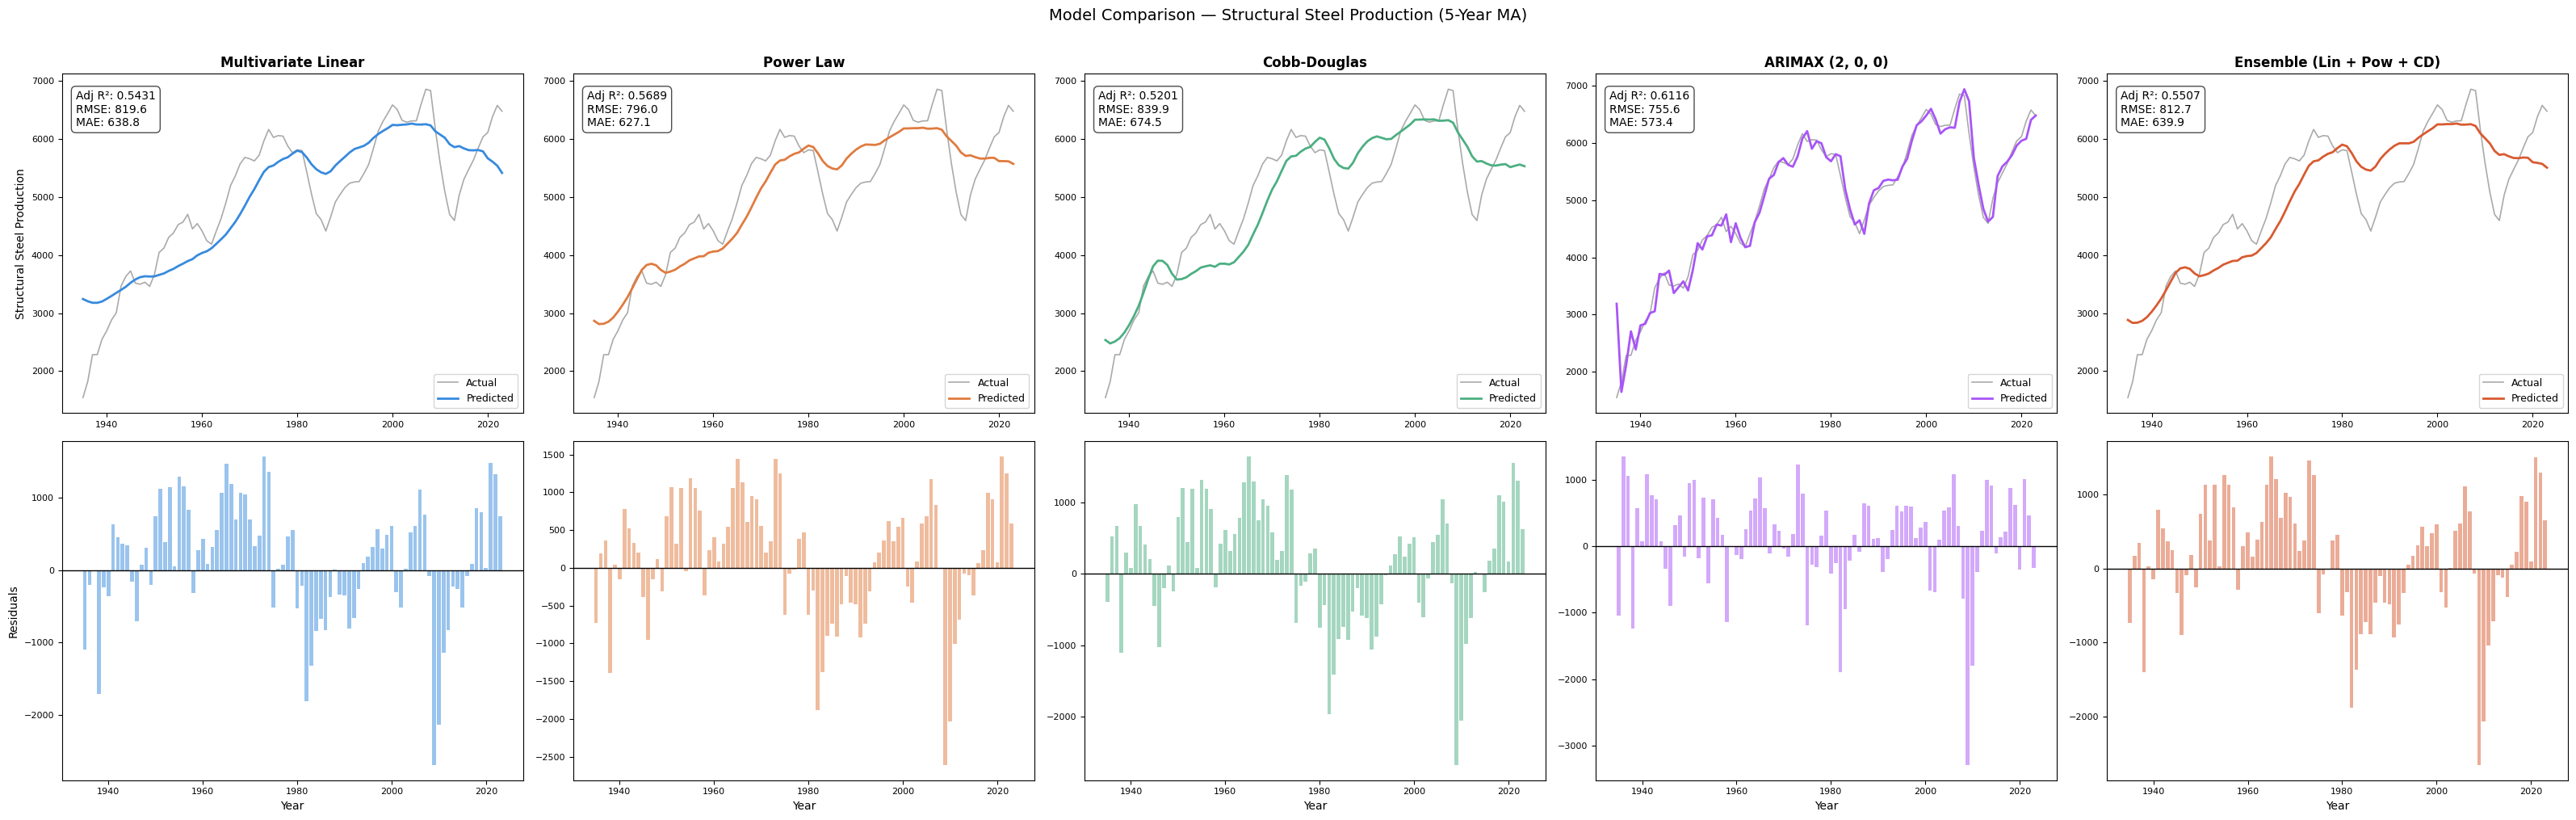

In [144]:
# ── shared data ───────────────────────────────────────────────────────────────
full_vars = ["pop_ssp2", "gdp_ssp2", "energy usage"]
n = len(df_MA_5)
k = 3

pop    = df_MA_5["pop_ssp2"].values
gdp    = df_MA_5["gdp_ssp2"].values
energy = df_MA_5["energy usage"].values
y      = df_MA_5["structural-total"]
exog   = df_MA_5[full_vars].values

y_actual = df_steel["structural-total"].iloc[4:]

def adj_r2(r2, n, k):
    return 1 - (1 - r2) * (n - 1) / (n - k - 1)

# ── 1. Multivariate Linear ────────────────────────────────────────────────────
lin_model = LinearRegression().fit(exog, y)
pred_lin  = lin_model.predict(exog)
r2_lin    = r2_score(y_actual, pred_lin)
metrics_lin = {
    "Adj R²": adj_r2(r2_lin, n, k),
    "RMSE":   np.sqrt(mean_squared_error(y_actual, pred_lin)),
    "MAE":    mean_absolute_error(y_actual, pred_lin),
}
resid_lin = y_actual - pred_lin

# ── 2. Power Law ──────────────────────────────────────────────────────────────
def power_model(X, a, b, c, d, e, f):
    pop, gdp, energy = X
    return a * np.power(pop, b) * c * np.power(gdp, d) * e * np.power(energy, f)

popt, _ = curve_fit(power_model, (pop, gdp, energy), y, p0=[1,1,1,1,1,1], maxfev=50000)
pred_pow = power_model((pop, gdp, energy), *popt)
r2_pow   = r2_score(y_actual, pred_pow)
metrics_pow = {
    "Adj R²": adj_r2(r2_pow, n, k),
    "RMSE":   np.sqrt(mean_squared_error(y_actual, pred_pow)),
    "MAE":    mean_absolute_error(y_actual, pred_pow),
}
resid_pow = y_actual - pred_pow

# ── 3. Cobb-Douglas ───────────────────────────────────────────────────────────
log_X = np.column_stack([np.ones(n), np.log(pop), np.log(gdp), np.log(energy)])
coeffs, _, _, _ = np.linalg.lstsq(log_X, np.log(y), rcond=None)
log_A, b_cd, d_cd, f_cd = coeffs
A_cd    = np.exp(log_A)
pred_cd = A_cd * np.power(pop, b_cd) * np.power(gdp, d_cd) * np.power(energy, f_cd)
r2_cd   = r2_score(y_actual, pred_cd)
metrics_cd = {
    "Adj R²": adj_r2(r2_cd, n, k),
    "RMSE":   np.sqrt(mean_squared_error(y_actual, pred_cd)),
    "MAE":    mean_absolute_error(y_actual, pred_cd),
}
resid_cd = y_actual - pred_cd

# ── 4. ARIMAX (auto-selected order) ──────────────────────────────────────────
arimax_model = pm.auto_arima(
    y,
    X=exog,
    start_p=0, max_p=3,
    start_q=0, max_q=3,
    d=None,                     # force no differencing — let exog carry the trend
    seasonal=False,
    information_criterion="aic",
    stepwise=True,
    error_action="ignore",
    suppress_warnings=True,
    trace=True
)

print(f"\nARIMAX selected order: {arimax_model.order}")
pred_arimax = arimax_model.predict_in_sample(X=exog)
r2_arimax   = r2_score(y_actual, pred_arimax)
metrics_arimax = {
    "Adj R²": adj_r2(r2_arimax, n, k),
    "RMSE":   np.sqrt(mean_squared_error(y_actual, pred_arimax)),
    "MAE":    mean_absolute_error(y_actual, pred_arimax),
}
resid_arimax = y_actual - pred_arimax


# ── 5. Ensemble (Lin + Pow + CD) ─────────────────────────────────────────────
pred_ensemble = np.mean([pred_lin, pred_pow, pred_cd], axis=0)
r2_ensemble   = r2_score(y_actual, pred_ensemble)
metrics_ensemble = {
    "Adj R²": adj_r2(r2_ensemble, n, k),
    "RMSE":   np.sqrt(mean_squared_error(y_actual, pred_ensemble)),
    "MAE":    mean_absolute_error(y_actual, pred_ensemble),
}
resid_ensemble = y_actual - pred_ensemble

# ── plot (2 rows × 4 cols) ────────────────────────────────────────────────────
models = [
    ("Multivariate Linear",              pred_lin,    resid_lin,    metrics_lin,    "#378ADD"),
    ("Power Law",                         pred_pow,    resid_pow,    metrics_pow,    "#E07B3F"),
    ("Cobb-Douglas",                      pred_cd,     resid_cd,     metrics_cd,     "#4CAF82"),
    (f"ARIMAX {arimax_model.order}",      pred_arimax, resid_arimax, metrics_arimax, "#A855F7"),
    ("Ensemble (Lin + Pow + CD)",         pred_ensemble, resid_ensemble, metrics_ensemble, "#D85A30"),
]

fig, axes = plt.subplots(2, 5, figsize=(32, 10))
idx = df_MA_5.index

for col, (title, pred, resid, metrics, color) in enumerate(models):

    # ── top row: actual vs predicted ─────────────────────────────────────────
    ax = axes[0, col]
    ax.plot(idx, y,    color="#AAAAAA", linewidth=1.2, label="Actual")
    ax.plot(idx, pred, color=color,     linewidth=2,   label="Predicted")
    ax.set_title(title, fontsize=12, fontweight="bold")
    ax.set_ylabel("Structural Steel Production" if col == 0 else "")
    ax.legend(fontsize=9)

    metric_text = "\n".join(f"{k}: {v:,.1f}" if k != "Adj R²"
                            else f"{k}: {v:.4f}"
                            for k, v in metrics.items())
    ax.text(0.03, 0.95, metric_text, transform=ax.transAxes,
            fontsize=10, verticalalignment="top",
            bbox=dict(boxstyle="round,pad=0.4", facecolor="white", alpha=0.7))
    ax.tick_params(labelsize=8)

    # ── bottom row: residuals ─────────────────────────────────────────────────
    ax = axes[1, col]
    ax.bar(idx, resid, color=color, alpha=0.5, width=0.8)
    ax.axhline(0, color="black", linewidth=1)
    ax.set_xlabel("Year")
    ax.set_ylabel("Residuals" if col == 0 else "")
    ax.tick_params(labelsize=8)

plt.suptitle("Model Comparison — Structural Steel Production (5-Year MA)",
             fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

In [145]:
print(f"Population exponent: {popt[1]:.3f}")
print(f"GDP exponent:        {popt[2]:.3f}")
print(f"Energy exponent:     {popt[3]:.3f}")

Population exponent: -0.858
GDP exponent:        887.078
Energy exponent:     0.183


In [146]:
print(f"Population exponent: {b:.3f}")
print(f"GDP exponent:        {d:.3f}")
print(f"Energy exponent:     {f:.3f}")

Population exponent: -0.465
GDP exponent:        -0.153
Energy exponent:     0.911


### Forecasting

c:\Users\aorga\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:837: ValueWarning: No supported index is available. Prediction results will be given with an integer index beginning at `start`.
  return get_prediction_index(
c:\Users\aorga\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:837: FutureWarning: No supported index is available. In the next version, calling this method in a model without a supported index will result in an exception.
  return get_prediction_index(
c:\Users\aorga\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:837: ValueWarning: No supported index is available. Prediction results will be given with an integer index beginning at `start`.
  return get_prediction_index(
c:\Users\aorga\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:837: FutureWarning: No supported index is available. In the next version, calling this method in a model without a supported index will result in an exception.
  return get_prediction_index(
c:\Users\aorga\Lib\site-packag

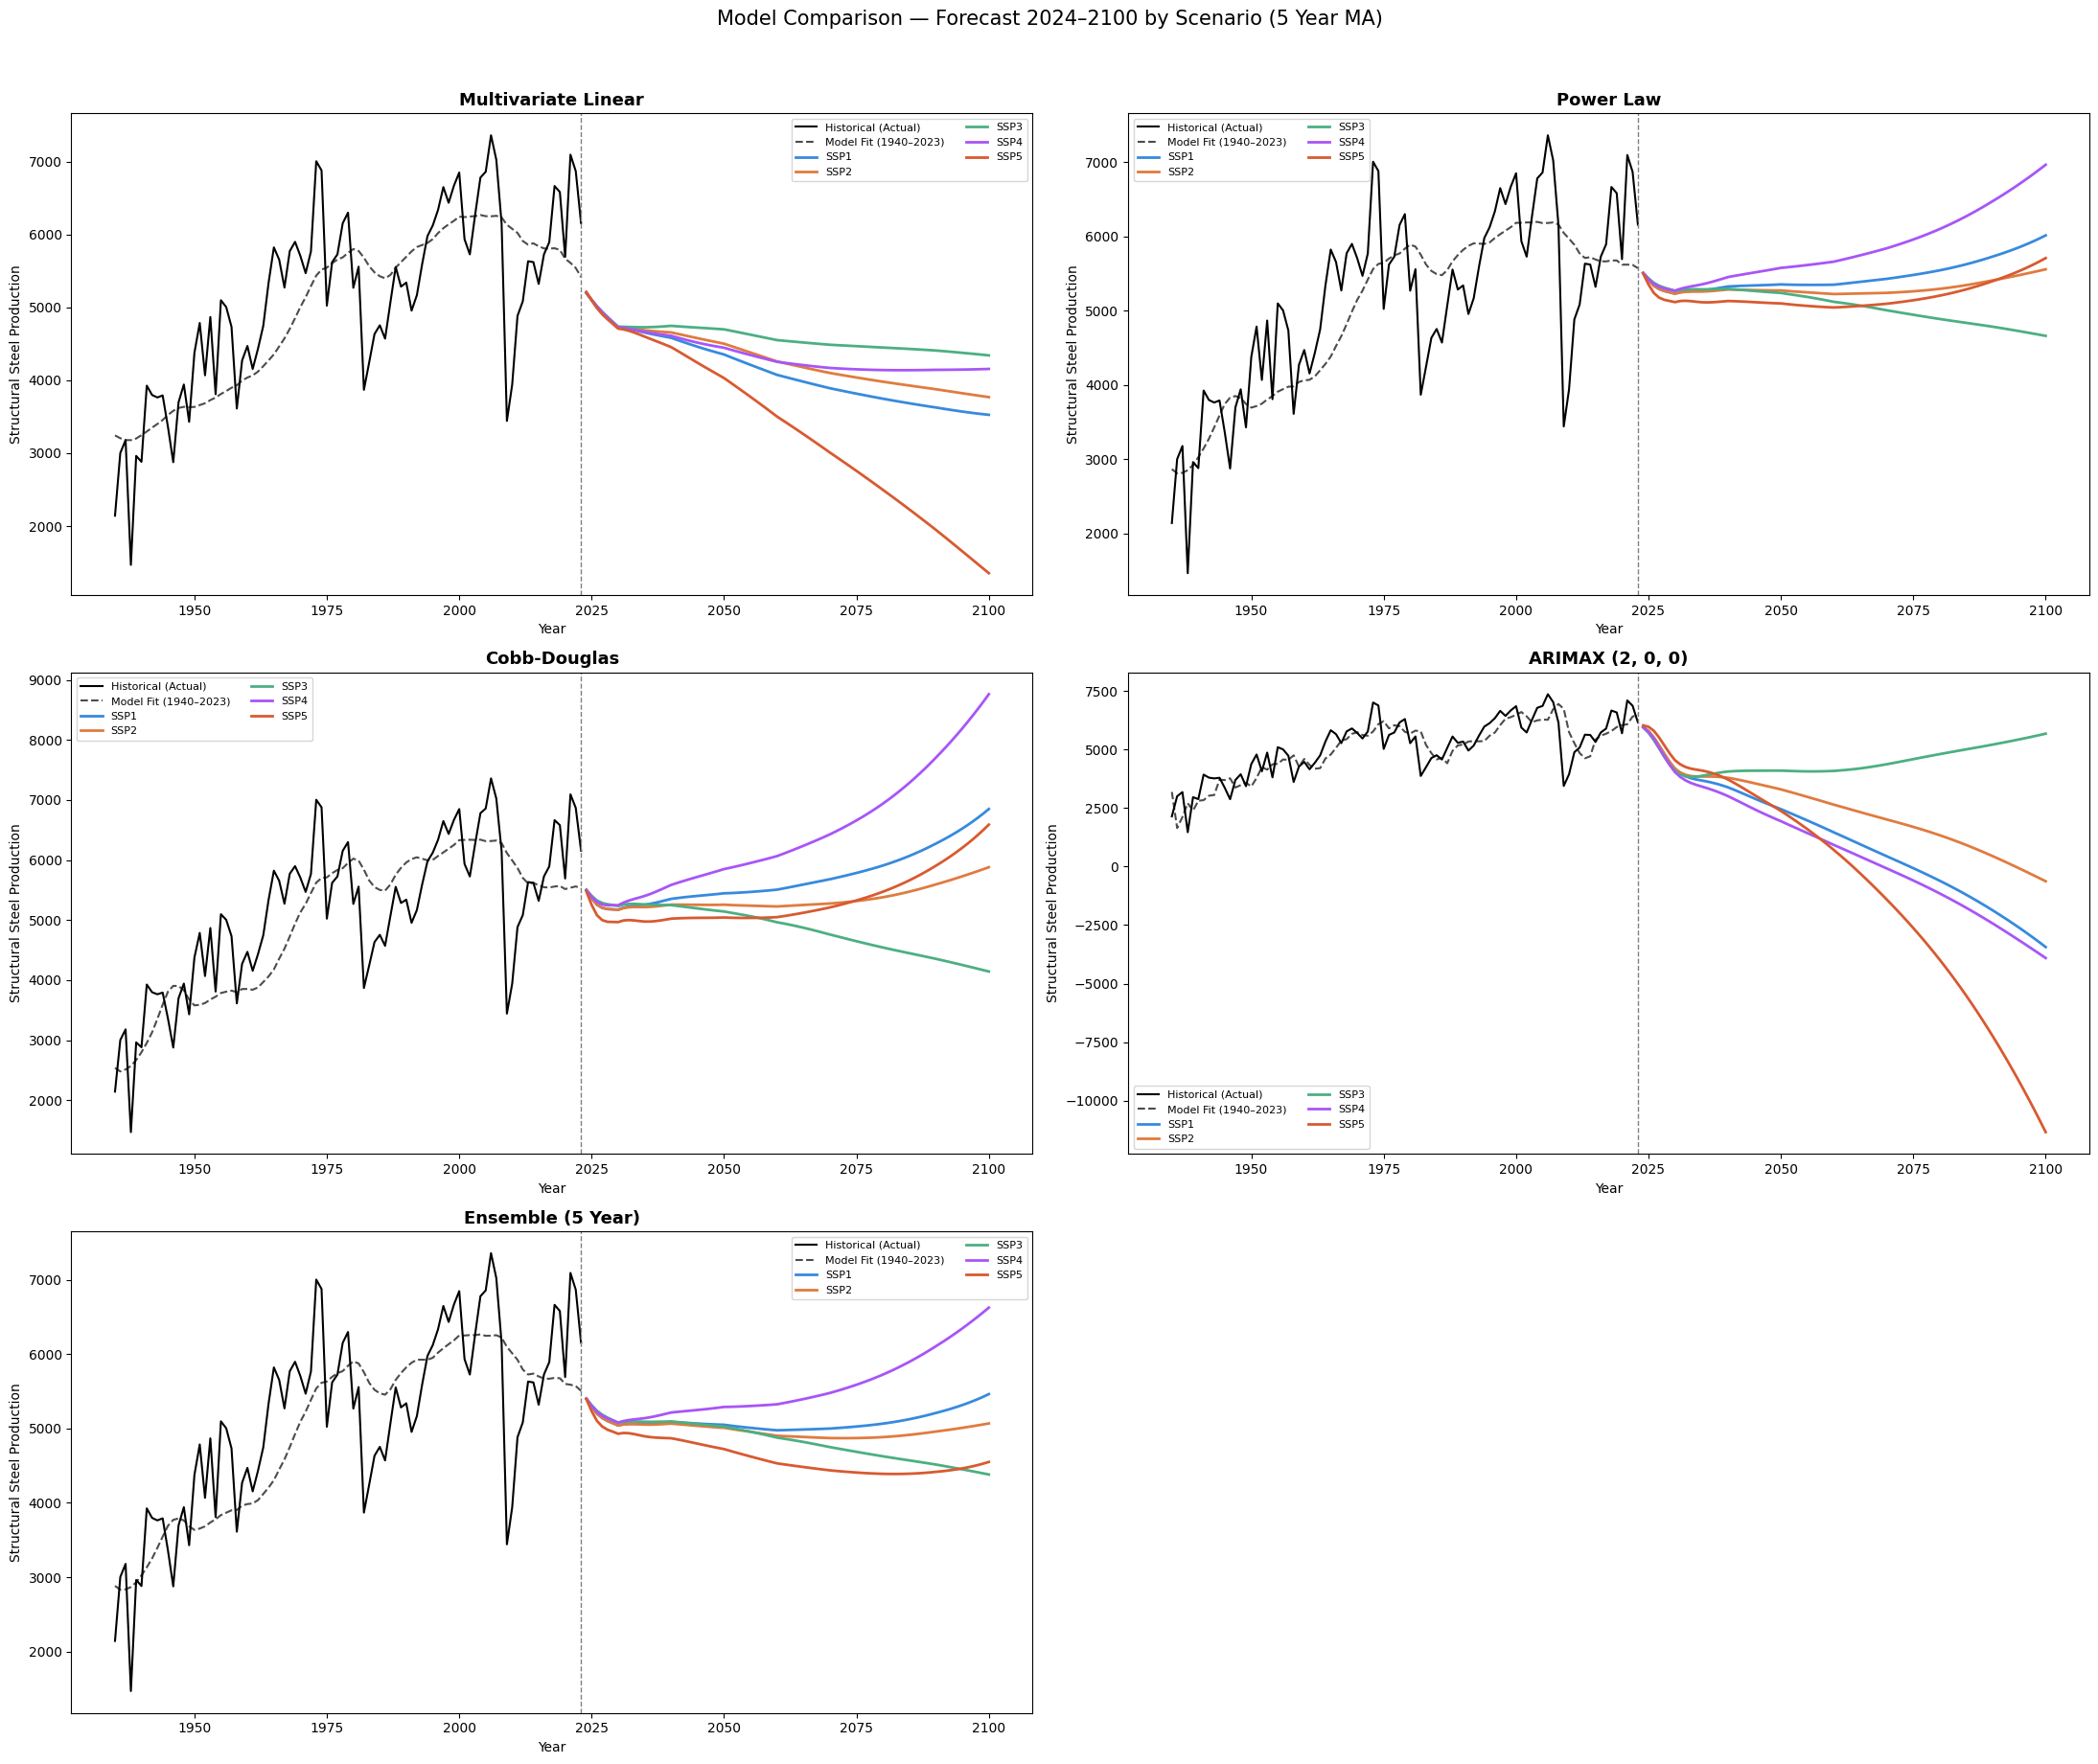

In [147]:
# ── config ────────────────────────────────────────────────────────────────────
scenarios = ["ssp1", "ssp2", "ssp3", "ssp4", "ssp5"]
forecast_years = np.arange(2024, 2101)

energy_forecast = df_energy_use.loc[forecast_years, "energy usage"].values

exog_forecast = {}
for s in scenarios:
    pop_f = df_population.loc[forecast_years, f"pop_{s}"].values
    gdp_f = df_gdp.loc[forecast_years, f"gdp_{s}"].values
    exog_forecast[s] = np.column_stack([pop_f, gdp_f, energy_forecast])

# ── 1. Multivariate Linear — forecast ────────────────────────────────────────
forecast_lin = {s: lin_model.predict(exog_forecast[s]) for s in scenarios}

# ── 2. Power Law — forecast ───────────────────────────────────────────────────
forecast_pow = {}
for s in scenarios:
    pop_f, gdp_f, en_f = exog_forecast[s][:,0], exog_forecast[s][:,1], exog_forecast[s][:,2]
    forecast_pow[s] = power_model((pop_f, gdp_f, en_f), *popt)

# ── 3. Cobb-Douglas — forecast ────────────────────────────────────────────────
forecast_cd = {}
for s in scenarios:
    pop_f, gdp_f, en_f = exog_forecast[s][:,0], exog_forecast[s][:,1], exog_forecast[s][:,2]
    forecast_cd[s] = A_cd * np.power(pop_f, b_cd) * np.power(gdp_f, d_cd) * np.power(en_f, f_cd)

# ── 4. ARIMAX (pm.auto_arima) — forecast ─────────────────────────────────────
n_periods = len(forecast_years)
forecast_arimax = {
    s: arimax_model.predict(n_periods=n_periods, X=exog_forecast[s],)
    for s in scenarios
}
# ── 5. Ensemble (mean of Linear, Power Law, Cobb-Douglas) ────────────────────
forecast_ensemble = {
    s: np.mean([forecast_lin[s], forecast_pow[s], forecast_cd[s]], axis=0)
    for s in scenarios
}

# ── in-sample (historical) predictions per model ─────────────────────────────
hist_idx = df_MA_5.index
hist_y   = df_steel["structural-total"].iloc[4:]

insample_lin      = pred_lin
insample_pow      = pred_pow
insample_cd       = pred_cd
insample_arimax   = arimax_model.predict_in_sample(X=exog)
insample_ensemble = np.mean([insample_lin, insample_pow, insample_cd], axis=0)

model_forecasts = {
    "Multivariate Linear":            (forecast_lin,      insample_lin),
    "Power Law":                      (forecast_pow,      insample_pow),
    "Cobb-Douglas":                   (forecast_cd,       insample_cd),
    f"ARIMAX {arimax_model.order}":   (forecast_arimax,   insample_arimax),
    "Ensemble (5 Year)":      (forecast_ensemble, insample_ensemble),
}

colors = {"ssp1": "#378ADD", "ssp2": "#E07B3F", "ssp3": "#4CAF82",
          "ssp4": "#A855F7", "ssp5": "#D85A30"}

# ── 3x2 grid (5 models) ───────────────────────────────────────────────────────
fig, axes = plt.subplots(3, 2, figsize=(22, 18))
axes = axes.flatten()

for ax, (title, (forecasts, insample_pred)) in zip(axes, model_forecasts.items()):
    ax.plot(hist_idx, hist_y, color="black", linewidth=1.5, label="Historical (Actual)")
    ax.plot(hist_idx, insample_pred, color="black", linestyle="--", linewidth=1.5,
            alpha=0.7, label="Model Fit (1940–2023)")

    for s in scenarios:
        ax.plot(forecast_years, forecasts[s], color=colors[s], linewidth=2, label=s.upper())

    ax.axvline(hist_idx[-1], color="gray", linestyle="--", linewidth=1)
    ax.set_title(title, fontsize=13, fontweight="bold")
    ax.set_xlabel("Year")
    ax.set_ylabel("Structural Steel Production")
    ax.legend(fontsize=8, ncol=2)

# Hide the unused 6th subplot
axes[-1].set_visible(False)

plt.suptitle("Model Comparison — Forecast 2024–2100 by Scenario (5 Year MA)", fontsize=15, y=1.02)
plt.tight_layout()
plt.show()

## 10 Year Forecast

Performing stepwise search to minimize aic
 ARIMA(0,1,0)(0,0,0)[0] intercept   : AIC=1013.470, Time=0.06 sec
 ARIMA(1,1,0)(0,0,0)[0] intercept   : AIC=958.562, Time=0.04 sec
 ARIMA(0,1,1)(0,0,0)[0] intercept   : AIC=979.681, Time=0.06 sec
 ARIMA(0,1,0)(0,0,0)[0]             : AIC=1296.250, Time=0.03 sec
 ARIMA(2,1,0)(0,0,0)[0] intercept   : AIC=960.807, Time=0.06 sec
 ARIMA(1,1,1)(0,0,0)[0] intercept   : AIC=960.600, Time=0.06 sec
 ARIMA(2,1,1)(0,0,0)[0] intercept   : AIC=1045.194, Time=0.07 sec
 ARIMA(1,1,0)(0,0,0)[0]             : AIC=956.401, Time=0.07 sec


c:\Users\aorga\Lib\site-packages\statsmodels\tsa\statespace\sarimax.py:1901: RuntimeWarning: divide by zero encountered in reciprocal
  return np.roots(self.polynomial_reduced_ar)**-1
c:\Users\aorga\Lib\site-packages\statsmodels\tsa\statespace\sarimax.py:1908: RuntimeWarning: divide by zero encountered in reciprocal
  return np.roots(self.polynomial_reduced_ma)**-1


 ARIMA(2,1,0)(0,0,0)[0]             : AIC=958.536, Time=0.11 sec
 ARIMA(1,1,1)(0,0,0)[0]             : AIC=958.391, Time=0.10 sec
 ARIMA(0,1,1)(0,0,0)[0]             : AIC=977.665, Time=0.13 sec
 ARIMA(2,1,1)(0,0,0)[0]             : AIC=1042.884, Time=0.06 sec

Best model:  ARIMA(1,1,0)(0,0,0)[0]          
Total fit time: 0.844 seconds

ARIMAX selected order: (1, 1, 0)


c:\Users\aorga\Lib\site-packages\statsmodels\tsa\statespace\sarimax.py:1901: RuntimeWarning: divide by zero encountered in reciprocal
  return np.roots(self.polynomial_reduced_ar)**-1
c:\Users\aorga\Lib\site-packages\statsmodels\tsa\statespace\sarimax.py:1908: RuntimeWarning: divide by zero encountered in reciprocal
  return np.roots(self.polynomial_reduced_ma)**-1


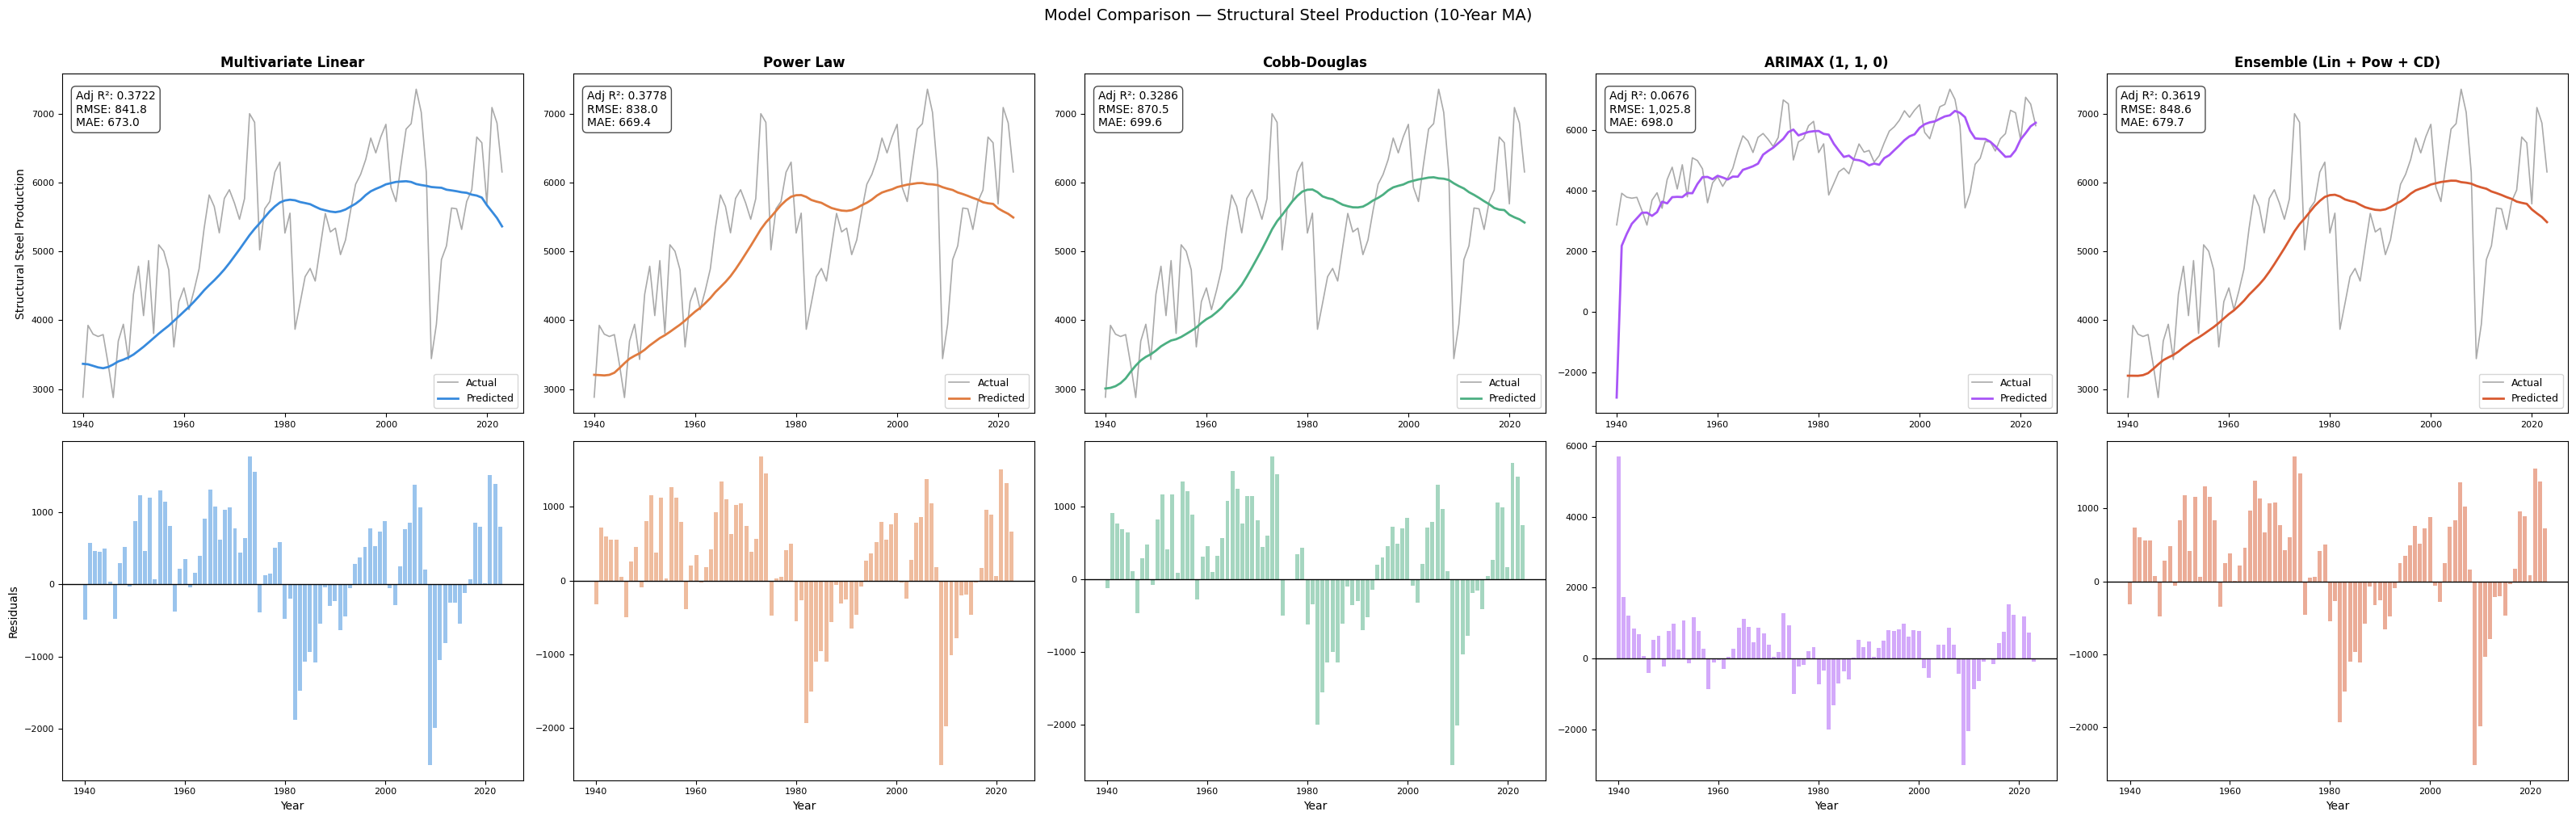

In [148]:
# ── shared data ───────────────────────────────────────────────────────────────
full_vars = ["pop_ssp2", "gdp_ssp2", "energy usage"]
n = len(df_MA_10)
k = 3

pop    = df_MA_10["pop_ssp2"].values
gdp    = df_MA_10["gdp_ssp2"].values
energy = df_MA_10["energy usage"].values
y      = df_MA_10["structural-total"].values
exog   = df_MA_10[full_vars].values

y_actual = df_steel['structural-total'].iloc[9:]

def adj_r2(r2, n, k):
    return 1 - (1 - r2) * (n - 1) / (n - k - 1)

# ── 1. Multivariate Linear ────────────────────────────────────────────────────
lin_model = LinearRegression().fit(exog, y)
pred_lin  = lin_model.predict(exog)
r2_lin    = r2_score(y_actual, pred_lin)
metrics_lin = {
    "Adj R²": adj_r2(r2_lin, n, k),
    "RMSE":   np.sqrt(mean_squared_error(y_actual, pred_lin)),
    "MAE":    mean_absolute_error(y_actual, pred_lin),
}
resid_lin = y_actual - pred_lin

# ── 2. Power Law ──────────────────────────────────────────────────────────────
def power_model(X, a, b, c, d, e, f):
    pop, gdp, energy = X
    return a * np.power(pop, b) * c * np.power(gdp, d) * e * np.power(energy, f)

popt, _ = curve_fit(power_model, (pop, gdp, energy), y, p0=[1,1,1,1,1,1], maxfev=50000)
pred_pow = power_model((pop, gdp, energy), *popt)
r2_pow   = r2_score(y_actual, pred_pow)
metrics_pow = {
    "Adj R²": adj_r2(r2_pow, n, k),
    "RMSE":   np.sqrt(mean_squared_error(y_actual, pred_pow)),
    "MAE":    mean_absolute_error(y_actual, pred_pow),
}
resid_pow = y_actual - pred_pow

# ── 3. Cobb-Douglas ───────────────────────────────────────────────────────────
log_X = np.column_stack([np.ones(n), np.log(pop), np.log(gdp), np.log(energy)])
coeffs, _, _, _ = np.linalg.lstsq(log_X, np.log(y), rcond=None)
log_A, b_cd, d_cd, f_cd = coeffs
A_cd    = np.exp(log_A)
pred_cd = A_cd * np.power(pop, b_cd) * np.power(gdp, d_cd) * np.power(energy, f_cd)
r2_cd   = r2_score(y_actual, pred_cd)
metrics_cd = {
    "Adj R²": adj_r2(r2_cd, n, k),
    "RMSE":   np.sqrt(mean_squared_error(y_actual, pred_cd)),
    "MAE":    mean_absolute_error(y_actual, pred_cd),
}
resid_cd = y_actual - pred_cd

# ── 4. ARIMAX (auto-selected order) ──────────────────────────────────────────
arimax_model = pm.auto_arima(
    y,
    X=exog,
    start_p=0, max_p=3,
    start_q=0, max_q=3,
    d=1,                     # force no differencing — let exog carry the trend
    seasonal=False,
    information_criterion="aic",
    stepwise=True,
    error_action="ignore",
    suppress_warnings=True,
    trace=True
)

print(f"\nARIMAX selected order: {arimax_model.order}")
pred_arimax = arimax_model.predict_in_sample(X=exog)
r2_arimax   = r2_score(y_actual, pred_arimax)
metrics_arimax = {
    "Adj R²": adj_r2(r2_arimax, n, k),
    "RMSE":   np.sqrt(mean_squared_error(y_actual, pred_arimax)),
    "MAE":    mean_absolute_error(y_actual, pred_arimax),
}
resid_arimax = y_actual - pred_arimax

# ── 5. Ensemble (Lin + Pow + CD) ─────────────────────────────────────────────
pred_ensemble = np.mean([pred_lin, pred_pow, pred_cd], axis=0)
r2_ensemble   = r2_score(y_actual, pred_ensemble)
metrics_ensemble = {
    "Adj R²": adj_r2(r2_ensemble, n, k),
    "RMSE":   np.sqrt(mean_squared_error(y_actual, pred_ensemble)),
    "MAE":    mean_absolute_error(y_actual, pred_ensemble),
}
resid_ensemble = y_actual - pred_ensemble

# ── plot (2 rows × 4 cols) ────────────────────────────────────────────────────
models = [
    ("Multivariate Linear",              pred_lin,    resid_lin,    metrics_lin,    "#378ADD"),
    ("Power Law",                         pred_pow,    resid_pow,    metrics_pow,    "#E07B3F"),
    ("Cobb-Douglas",                      pred_cd,     resid_cd,     metrics_cd,     "#4CAF82"),
    (f"ARIMAX {arimax_model.order}",      pred_arimax, resid_arimax, metrics_arimax, "#A855F7"),
    ("Ensemble (Lin + Pow + CD)",         pred_ensemble, resid_ensemble, metrics_ensemble, "#D85A30"),
]
fig, axes = plt.subplots(2, 5, figsize=(32, 10))
idx = df_MA_10.index

for col, (title, pred, resid, metrics, color) in enumerate(models):

    # ── top row: actual vs predicted ─────────────────────────────────────────
    ax = axes[0, col]
    ax.plot(idx, y_actual,    color="#AAAAAA", linewidth=1.2, label="Actual")
    ax.plot(idx, pred, color=color,     linewidth=2,   label="Predicted")
    ax.set_title(title, fontsize=12, fontweight="bold")
    ax.set_ylabel("Structural Steel Production" if col == 0 else "")
    ax.legend(fontsize=9)

    metric_text = "\n".join(f"{k}: {v:,.1f}" if k != "Adj R²"
                            else f"{k}: {v:.4f}"
                            for k, v in metrics.items())
    ax.text(0.03, 0.95, metric_text, transform=ax.transAxes,
            fontsize=10, verticalalignment="top",
            bbox=dict(boxstyle="round,pad=0.4", facecolor="white", alpha=0.7))
    ax.tick_params(labelsize=8)

    # ── bottom row: residuals ─────────────────────────────────────────────────
    ax = axes[1, col]
    ax.bar(idx, resid, color=color, alpha=0.5, width=0.8)
    ax.axhline(0, color="black", linewidth=1)
    ax.set_xlabel("Year")
    ax.set_ylabel("Residuals" if col == 0 else "")
    ax.tick_params(labelsize=8)

plt.suptitle("Model Comparison — Structural Steel Production (10-Year MA)",
             fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

### Forecasting

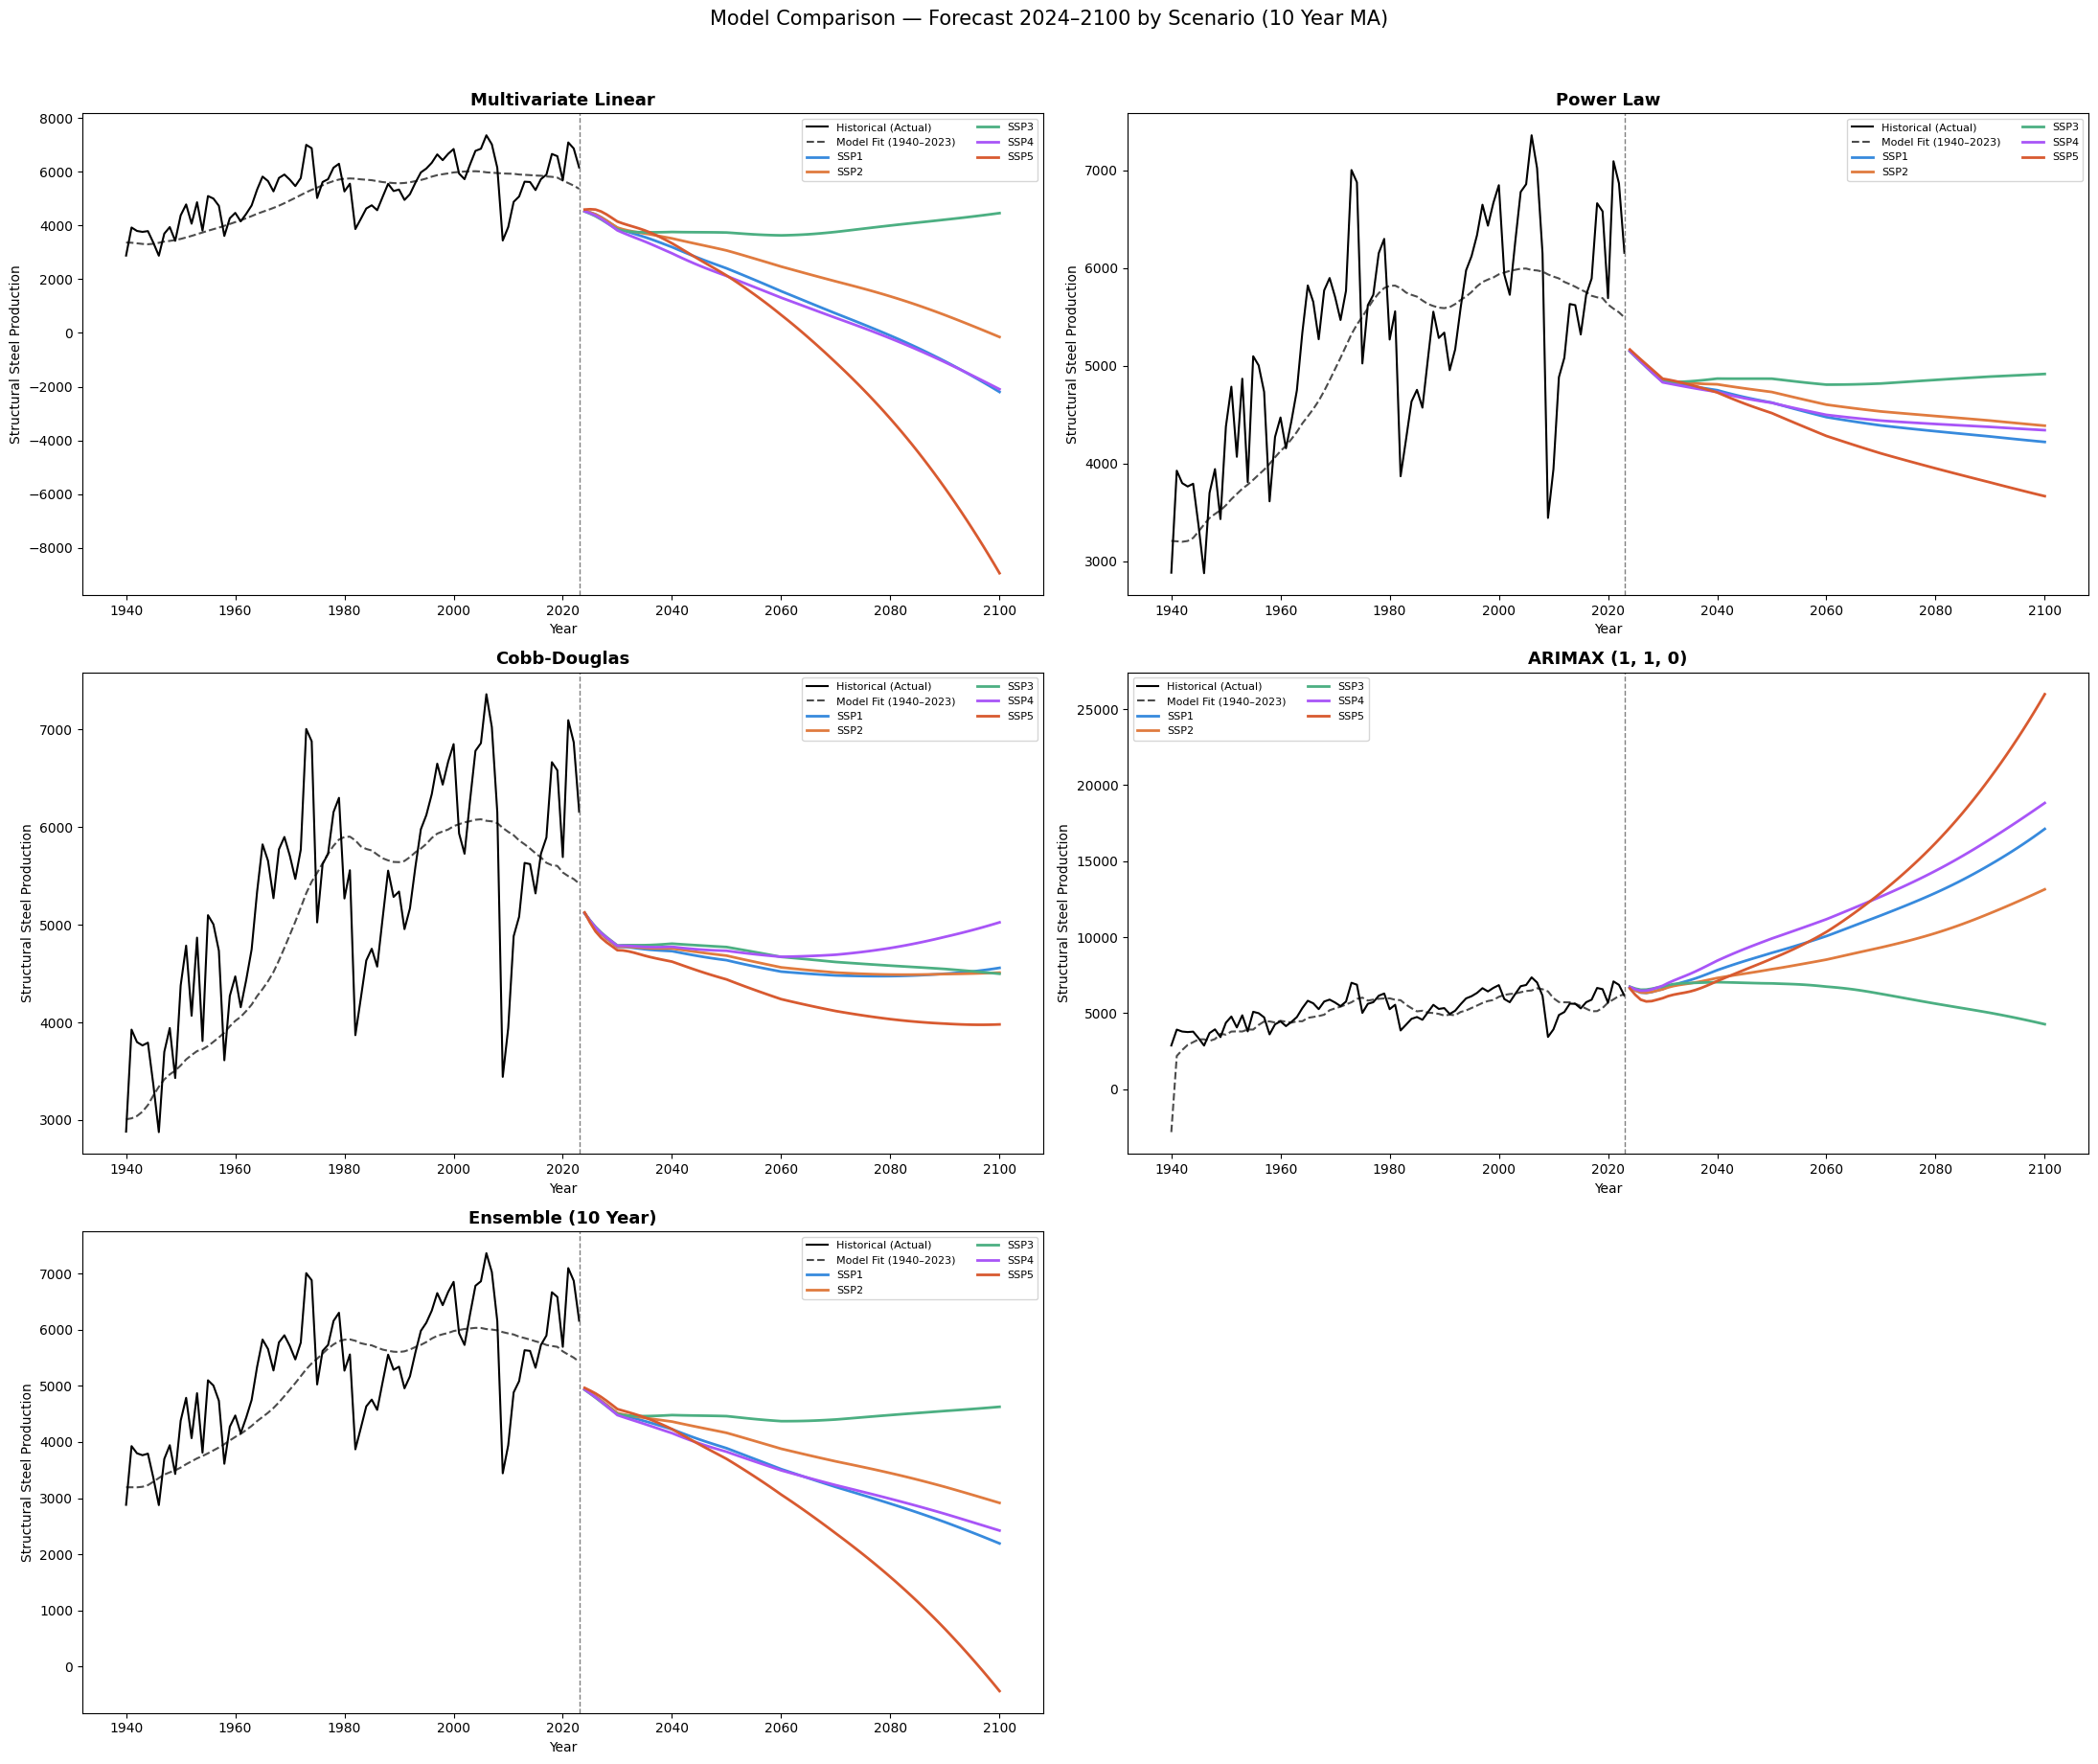

In [149]:
# ── config ────────────────────────────────────────────────────────────────────
scenarios = ["ssp1", "ssp2", "ssp3", "ssp4", "ssp5"]
forecast_years = np.arange(2024, 2101)

energy_forecast = df_energy_use.loc[forecast_years, "energy usage"].values

exog_forecast = {}
for s in scenarios:
    pop_f = df_population.loc[forecast_years, f"pop_{s}"].values
    gdp_f = df_gdp.loc[forecast_years, f"gdp_{s}"].values
    exog_forecast[s] = np.column_stack([pop_f, gdp_f, energy_forecast])

# ── 1. Multivariate Linear — forecast ────────────────────────────────────────
forecast_lin = {s: lin_model.predict(exog_forecast[s]) for s in scenarios}

# ── 2. Power Law — forecast ───────────────────────────────────────────────────
forecast_pow = {}
for s in scenarios:
    pop_f, gdp_f, en_f = exog_forecast[s][:,0], exog_forecast[s][:,1], exog_forecast[s][:,2]
    forecast_pow[s] = power_model((pop_f, gdp_f, en_f), *popt)

# ── 3. Cobb-Douglas — forecast ────────────────────────────────────────────────
forecast_cd = {}
for s in scenarios:
    pop_f, gdp_f, en_f = exog_forecast[s][:,0], exog_forecast[s][:,1], exog_forecast[s][:,2]
    forecast_cd[s] = A_cd * np.power(pop_f, b_cd) * np.power(gdp_f, d_cd) * np.power(en_f, f_cd)

# ── 4. ARIMAX (pm.auto_arima) — forecast ─────────────────────────────────────
n_periods = len(forecast_years)
forecast_arimax = {
    s: arimax_model.predict(n_periods=n_periods, X=exog_forecast[s])
    for s in scenarios
}

# ── 5. Ensemble (mean of Linear, Power Law, Cobb-Douglas) ────────────────────
forecast_ensemble = {
    s: np.mean([forecast_lin[s], forecast_pow[s], forecast_cd[s]], axis=0)
    for s in scenarios
}

# ── in-sample (historical) predictions per model ─────────────────────────────
hist_idx = df_MA_10.index
hist_y   = df_steel["structural-total"].iloc[9:]

insample_lin      = pred_lin
insample_pow      = pred_pow
insample_cd       = pred_cd
insample_arimax   = arimax_model.predict_in_sample(X=exog)
insample_ensemble = np.mean([insample_lin, insample_pow, insample_cd], axis=0)

model_forecasts = {
    "Multivariate Linear":            (forecast_lin,      insample_lin),
    "Power Law":                      (forecast_pow,      insample_pow),
    "Cobb-Douglas":                   (forecast_cd,       insample_cd),
    f"ARIMAX {arimax_model.order}":   (forecast_arimax,   insample_arimax),
    "Ensemble (10 Year)":      (forecast_ensemble, insample_ensemble),
}

colors = {"ssp1": "#378ADD", "ssp2": "#E07B3F", "ssp3": "#4CAF82",
          "ssp4": "#A855F7", "ssp5": "#D85A30"}

# ── 3x2 grid (5 models) ───────────────────────────────────────────────────────
fig, axes = plt.subplots(3, 2, figsize=(22, 18))
axes = axes.flatten()

for ax, (title, (forecasts, insample_pred)) in zip(axes, model_forecasts.items()):
    ax.plot(hist_idx, hist_y, color="black", linewidth=1.5, label="Historical (Actual)")
    ax.plot(hist_idx, insample_pred, color="black", linestyle="--", linewidth=1.5,
            alpha=0.7, label="Model Fit (1940–2023)")

    for s in scenarios:
        ax.plot(forecast_years, forecasts[s], color=colors[s], linewidth=2, label=s.upper())

    ax.axvline(hist_idx[-1], color="gray", linestyle="--", linewidth=1)
    ax.set_title(title, fontsize=13, fontweight="bold")
    ax.set_xlabel("Year")
    ax.set_ylabel("Structural Steel Production")
    ax.legend(fontsize=8, ncol=2)

# Hide the unused 6th subplot
axes[-1].set_visible(False)

plt.suptitle("Model Comparison — Forecast 2024–2100 by Scenario (10 Year MA)", fontsize=15, y=1.02)
plt.tight_layout()
plt.show()

In [150]:
print(f"Population exponent: {popt[1]:.3f}")
print(f"GDP exponent:        {popt[2]:.3f}")
print(f"Energy exponent:     {popt[3]:.3f}")

Population exponent: -0.029
GDP exponent:        -25.485
Energy exponent:     -0.320


In [151]:
print(f"Population exponent: {b:.3f}")
print(f"GDP exponent:        {d:.3f}")
print(f"Energy exponent:     {f:.3f}")

Population exponent: -0.465
GDP exponent:        -0.153
Energy exponent:     0.911


In [167]:
 # ── 2. Power Law (log-linearized) ────────────────────────────────────────────
log_y      = np.log(y)
log_pop    = np.log(pop)
log_gdp    = np.log(gdp)
log_energy = np.log(energy)

X_log = np.column_stack([np.ones(len(y)), log_pop, log_gdp, log_energy])
pow_coeffs, _, _, _ = np.linalg.lstsq(X_log, log_y, rcond=None)

log_A_pow, b_pow, d_pow, f_pow = pow_coeffs
A_pow = np.exp(log_A_pow)

print("Power Law (log-linearized)")
print(f"  A (scale):           {A_pow:.6f}")
print(f"  Population exponent: {b_pow:.3f}")
print(f"  GDP exponent:        {d_pow:.3f}")
print(f"  Energy exponent:     {f_pow:.3f}")

# ── predict ───────────────────────────────────────────────────────────────────
pred_pow = A_pow * np.power(pop, b_pow) * np.power(gdp, d_pow) * np.power(energy, f_pow)

r2_pow = r2_score(y_actual, pred_pow)
metrics_pow = {
    "Adj R²": adj_r2(r2_pow, n, k),
    "RMSE":   np.sqrt(mean_squared_error(y_actual, pred_pow)),
    "MAE":    mean_absolute_error(y_actual, pred_pow),
}
resid_pow = y_actual - pred_pow


# ── forecast ──────────────────────────────────────────────────────────────────
forecast_pow = {}
for s in scenarios:
    pop_f, gdp_f, en_f = exog_forecast[s][:,0], exog_forecast[s][:,1], exog_forecast[s][:,2]
    forecast_pow[s] = A_pow * np.power(pop_f, b_pow) * np.power(gdp_f, d_pow) * np.power(en_f, f_pow)

Power Law (log-linearized)
  A (scale):           2065011307386781440.000000
  Population exponent: -2.554
  GDP exponent:        1.112
  Energy exponent:     0.966


ValueError: Found input variables with inconsistent numbers of samples: [84, 93]

In [159]:
df_MA_2["structural-total"]

1932    1245.0
1933    1160.0
1934    1548.5
1935    1889.5
1936    2572.0
         ...  
2019    6623.5
2020    6137.5
2021    6394.0
2022    6982.0
2023    6513.0
Name: structural-total, Length: 92, dtype: float64

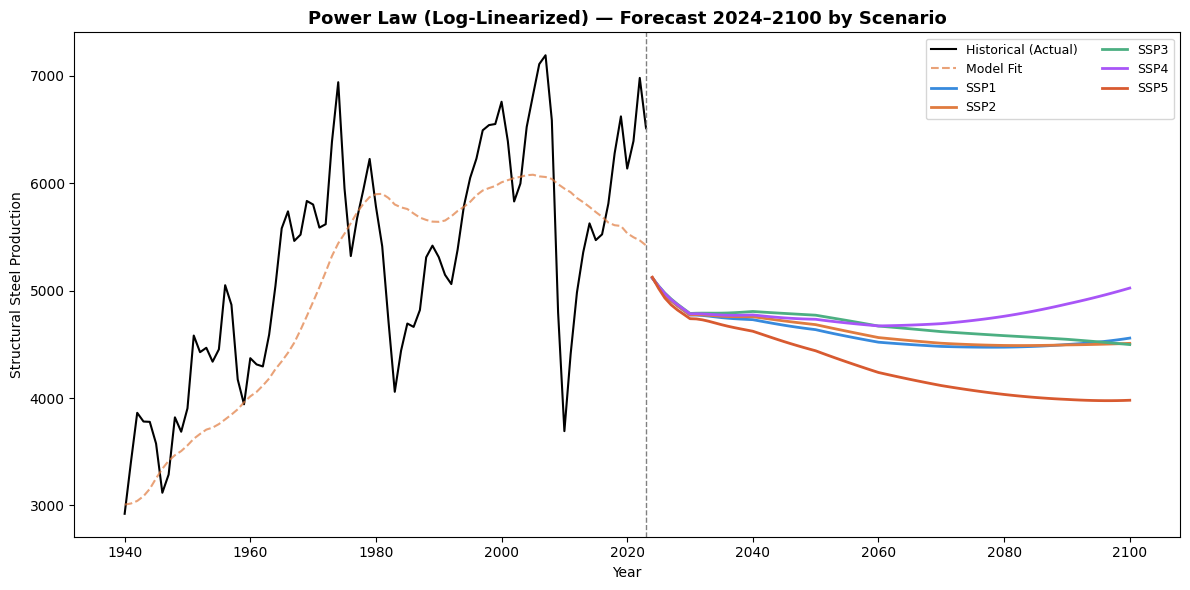

In [163]:
fig, ax = plt.subplots(figsize=(12, 6))

ax.plot(hist_idx, df_MA_2["structural-total"].loc[1940:], color="black", linewidth=1.5, label="Historical (Actual)")
ax.plot(hist_idx, pred_pow, color="#E07B3F", linestyle="--", linewidth=1.5, alpha=0.7, label="Model Fit")

for s in scenarios:
    ax.plot(forecast_years, forecast_pow[s], color=colors[s], linewidth=2, label=s.upper())

ax.axvline(hist_idx[-1], color="gray", linestyle="--", linewidth=1)
ax.set_title("Power Law (Log-Linearized) — Forecast 2024–2100 by Scenario", fontsize=13, fontweight="bold")
ax.set_xlabel("Year")
ax.set_ylabel("Structural Steel Production")
ax.legend(fontsize=9, ncol=2)
plt.tight_layout()
plt.show()

In [ ]:
# ── time indices ──────────────────────────────────────────────────────────────
hist_years     = df_MA_1.index          # 1932–2023
forecast_years = np.arange(2024, 2101)          # 2024–2100
all_years      = np.concatenate([hist_years, forecast_years])

pow_data = {"year": all_years}

pow_data["actual"] = np.concatenate([hist_y, np.full(len(forecast_years), np.nan)])

for s in scenarios:
    pow_data[s] = np.concatenate([hist_y, forecast_pow[s]])

df_pow = pd.DataFrame(pow_data).set_index("year").drop(columns='actual')

df_pow